# Phenology-Aware Target Selection for a Compact Temporal JEPA — Crop Classification Research Notebook

**Notebook version 1.0.0** · Primary dataset: **PASTIS (Sentinel-2), parcel-level crop-type classification** · Designed for an RTX 3050 Laptop GPU (4 GB VRAM), 16 GB RAM.

> **Status discipline.** This notebook never prints or plots a number that it did not compute from saved run outputs. Any experiment that has not executed is reported as **PENDING**. Results produced on **synthetic data** or under the **SMOKE_TEST** profile are stamped as pipeline checks and must never be cited as research evidence.

## 0. Research overview

### 0.1 Research question (frozen for the pilot)

In a compact temporal Joint-Embedding Predictive Architecture (an **I-JEPA-style objective adapted to parcel-level Sentinel-2 time series**), does placing the prediction **targets** on temporal windows with high *unsupervised* vegetation-index change (**phenology-aware target selection**) produce representations that classify crops better than uniformly placed targets — under a **matched masking budget, identical model, data, optimiser and training budget** — and is any benefit larger when **few labels** are available or **observations are missing**?

* **H1:** phenology-aware target placement improves frozen-representation crop classification (macro-F1) relative to uniform target placement.
* **H0:** no difference beyond seed-to-seed and test-sampling variability.
* A **negative or null result is an acceptable outcome**; the decision rules below are fixed before any real-data run.

### 0.2 Pre-registered endpoints and decision rules

| Item | Definition |
|---|---|
| Primary endpoint | Test macro-F1 of a **frozen linear probe** on the EMA target encoder, at the **10 % label budget**, fold configuration 0 (train folds 1-3, val fold 4, test fold 5) |
| Key secondary | Linear probe at 1 %; fine-tuning macro-F1 at 1 % / 10 % / 100 %; macro-F1 with 50 % of observations removed; contiguous May–June gap |
| Other metrics | Balanced accuracy, overall accuracy, per-class F1, confusion matrix; runtime, peak GPU memory |
| SSL checkpoint | **Final epoch of a fixed schedule** (no label-based selection of pretraining checkpoints) |
| Downstream checkpoint | Best **validation** macro-F1 (val fold only; test labels never used for selection) |
| "Supported" | Mean paired difference (phenology − random) > 0, positive for **every** seed (≥ 3 seeds), and the per-seed paired-bootstrap 95 % CI excludes 0 for a majority of seeds |
| "Contradicted" | Mean difference < 0 and negative for every seed |
| Otherwise | "Inconclusive" — scale up (more seeds/folds) before any claim |

Even a "supported" pilot result is **not** a publishable claim: the control policies (`spectral_change`, `inverse_phenology`) and multiple folds in `RESEARCH_RUN` are required to show that the effect is *phenology-specific* rather than a generic "informative masking" effect.

### 0.3 Pipeline

`Sentinel-2 patches (T×10×128×128)` → **per-parcel median time series** (T×10, with acquisition dates and validity masks) → leakage-safe official-fold splits → (a) supervised baseline, (b) Random-Forest reference, (c) temporal JEPA pretraining on **training-fold parcels only** with either uniform (`random_block`) or phenology-aware (`phenology`) target placement → linear probe / fine-tuning at nested label budgets → evaluation on the held-out fold with controlled observation removal.

### 0.4 Deviations from canonical I-JEPA (disclosed)

| Canonical I-JEPA (Assran et al., CVPR 2023) | This notebook | Why |
|---|---|---|
| ViT on image patches; 2-D multi-block masks | Transformer over **acquisition-date tokens** of a parcel time series; **1-D temporal** multi-block masks | The hypothesis concerns *temporal* target placement; parcel series keep the experiment feasible on 4 GB |
| 4 target blocks, may overlap | 4 target blocks, **sampled without overlap** (overlap only as rare fallback) | Guarantees an identical masked-token budget across policies, so policies differ *only* in where targets are placed |
| Learned/fixed 2-D positional embeddings added to patch embeddings | $\mathrm{LN}(W_x x) + W_d\,e(\text{day})$ with sinusoidal $e$ and small-init learned $W_d$ | Irregular dates; prevents the positional shortcut observed with a plain sum |
| Target = LayerNorm(target-encoder output on full image), masked *after* encoding | Same: target encoder sees the **full** series; targets are selected from its output | Faithful |
| Context encoder sees context block only | Same (implemented as attention key-masking; equivalent for a transformer) | Faithful; tested by a context-isolation test |
| Narrow ViT predictor, one pass per target block | Narrow transformer predictor, one pass per target block | Faithful |
| EMA momentum 0.996 → 1.0 | Same | Faithful |
| Loss: paper text says L2; official code uses smooth-L1 (to be verified) | `smooth_l1` by default, `l2` selectable | Matches the official code as recalled; verify against the repository |
| Weight decay cosine-scheduled 0.04 → 0.4 | Fixed 0.05 | Simplification for a compact model |
| Evaluation with the target encoder, average-pooled | Same | Faithful |

### 0.5 Section map

The requested section order was adapted so that every cell only uses names defined in earlier cells (no forward references):

| Notebook section | Content | Requested section |
|---|---|---|
| 0 | Overview & configuration | 0 |
| 1 | Environment & hardware audit | 1 |
| 2 | Dependencies, imports, device & precision | 2 |
| 3 | Dataset acquisition (+ synthetic PASTIS-format generator for pipeline checks) | 3 |
| 4 | Raw dataset audit & visualisation | 4 |
| 5 | Parcel extraction, splits, leakage checks, normalisation, parcel-level audit | 5 |
| 6 | Model components & JEPA objective | 8 |
| 7 | Target-selection policies (baseline + **research modification** + controls) | 9 |
| 8 | Metrics & evaluation utilities | 11 |
| 9 | Training infrastructure: checkpoints, resume, logging, trainers | 10 |
| 10 | Sanity tests (decision gate) | 6 |
| 11 | Runtime benchmark & projected runtime | (Phase 4-D) |
| 12 | Controlled experiments (supervised baseline, RF, JEPA baseline, modification, probes, fine-tuning, missing observations) | 7, 12 |
| 13 | Results & visualisations from saved outputs | 13 |
| 14 | Automatically generated research summary | 14 |

### 0.6 How to run

1. First run: keep `PROFILE="SMOKE_TEST"`, `DATA_SOURCE="synthetic"` and run all cells. This verifies the whole pipeline on your machine in minutes, without downloading anything.
2. Obtain PASTIS (Section 3), set `DATA_SOURCE="pastis"`, keep `SMOKE_TEST` once more (uses a 60-patch subset).
3. Switch to `PROFILE="QUICK_PILOT"` for the first meaningful experiment. `RESEARCH_RUN` is intended for a longer campaign or a cloud GPU.

Every profile/data-source pair writes to its own namespace under `WORK_DIR/runs/`, so smoke-test outputs can never be mixed into pilot results. Re-running a cell skips completed runs and resumes interrupted ones.

In [1]:
# ===================== 0.1 Central configuration — edit only this cell =====================
import os, sys, json, math, time, copy, random, shutil, hashlib, platform, re
import datetime as dt
from pathlib import Path

NOTEBOOK_VERSION = "1.0.0"

# ---- What to run (environment variables override, useful for headless execution) ----
PROFILE     = os.environ.get("JEPA_PROFILE", "SMOKE_TEST")      # "SMOKE_TEST" | "QUICK_PILOT" | "RESEARCH_RUN"
DATA_SOURCE = os.environ.get("JEPA_DATA_SOURCE", "synthetic")   # "synthetic" (pipeline check) | "pastis" (real data)

# ---- Paths (relative paths resolve against the directory Jupyter was started in) ----
WORK_DIR    = Path(os.environ.get("JEPA_WORK_DIR", "jepa_work")).expanduser().resolve()      # generated artifacts
PASTIS_ROOT = Path(os.environ.get("JEPA_PASTIS_ROOT", "data/PASTIS")).expanduser().resolve() # raw data (read-only use)

# ---- Device and precision policy ----
# CPU is only allowed for SMOKE_TEST by default; real experiments refuse to fall back silently.
ALLOW_CPU = os.environ.get("JEPA_ALLOW_CPU", "1" if PROFILE == "SMOKE_TEST" else "0") == "1"
AMP_MODE = "auto"                 # "auto": bf16 if supported, else fp16+GradScaler (CUDA only); "off": fp32
DETERMINISTIC = True              # deterministic algorithms where available (warn-only)
KEEP_DATA_ON_GPU_MAX_MB = 800     # keep the normalised parcel tensor on the GPU if it fits in this budget

# ---- Dataset acquisition gate (never downloads unless you opt in) ----
ALLOW_DOWNLOAD = False
PASTIS_ARCHIVE_URL = ""           # paste the official archive URL from the PASTIS repository / Zenodo record
PASTIS_ARCHIVE_MD5 = ""           # optional: checksum published with the archive
DELETE_ARCHIVE_AFTER_EXTRACT = False

# ---- Misc behaviour ----
INSTALL_MISSING = False           # Section 2: pip-install missing non-torch packages (requires kernel restart)
STOP_ON_RUN_FAILURE = True        # stop the experiment loop at the first failed run (never silently skip)
SPLIT_MODE = "official_folds"     # "official_folds" | "tile_holdout"
TEST_TILE = None                  # used only for SPLIT_MODE == "tile_holdout" (e.g. a TILE value from metadata)
KEEP_SHARDS = False               # keep per-chunk preprocessing shards after the merged cache is written
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")  # must be set before CUDA initialises

# ---- Official PASTIS 5-fold rotation: (train folds, val fold, test fold) ----
FOLD_CONFIGS = [([1, 2, 3], [4], [5]), ([2, 3, 4], [5], [1]), ([3, 4, 5], [1], [2]),
                ([4, 5, 1], [2], [3]), ([5, 1, 2], [3], [4])]

# ---- Run profiles ----
PROFILES = {
    "SMOKE_TEST": dict(
        seeds=[0], fold_configs=[0], pretrain_policies=["random_block", "phenology"],
        pretrain_epochs=2, ssl_batch_size=64,
        lp_budgets=[0.1, 1.0], ft_budgets=[0.1], sup_budgets=[0.1, 1.0], rf_budgets=[0.1],
        downstream_epochs=3, downstream_min_steps=20, downstream_batch_size=64, eval_every_steps=10,
        missing_rates=[0.0, 0.5], eval_gap=True,
        d_model=64, depth=2, heads=4, pred_dim=32, pred_depth=2,
        rf_trees=50, run_rf=True, max_patches_pastis=60, synthetic_patches=150,
        knn_monitor=True, bootstrap_reps=200, benchmark_steps=10, benchmark_pilot_config=True,
    ),
    "QUICK_PILOT": dict(
        seeds=[0, 1, 2], fold_configs=[0], pretrain_policies=["random_block", "phenology"],
        pretrain_epochs=40, ssl_batch_size=256,
        lp_budgets=[0.01, 0.05, 0.1, 0.25, 1.0], ft_budgets=[0.01, 0.1, 1.0],
        sup_budgets=[0.01, 0.1, 1.0], rf_budgets=[0.01, 0.1, 1.0],
        downstream_epochs=30, downstream_min_steps=400, downstream_batch_size=256, eval_every_steps=100,
        missing_rates=[0.0, 0.3, 0.5, 0.7], eval_gap=True,
        d_model=128, depth=4, heads=4, pred_dim=64, pred_depth=3,
        rf_trees=200, run_rf=True, max_patches_pastis=None, synthetic_patches=800,
        knn_monitor=True, bootstrap_reps=1000, benchmark_steps=50, benchmark_pilot_config=False,
    ),
    "RESEARCH_RUN": dict(
        seeds=[0, 1, 2, 3, 4], fold_configs=[0, 1, 2, 3, 4],
        pretrain_policies=["random_block", "phenology", "spectral_change", "inverse_phenology"],
        pretrain_epochs=100, ssl_batch_size=256,
        lp_budgets=[0.005, 0.01, 0.02, 0.05, 0.1, 0.25, 0.5, 1.0], ft_budgets=[0.01, 0.05, 0.1, 0.25, 1.0],
        sup_budgets=[0.01, 0.05, 0.1, 0.25, 1.0], rf_budgets=[0.01, 0.1, 1.0],
        downstream_epochs=50, downstream_min_steps=600, downstream_batch_size=256, eval_every_steps=200,
        missing_rates=[0.0, 0.3, 0.5, 0.7, 0.85], eval_gap=True,
        d_model=128, depth=4, heads=4, pred_dim=64, pred_depth=3,
        rf_trees=200, run_rf=True, max_patches_pastis=None, synthetic_patches=800,
        knn_monitor=True, bootstrap_reps=1000, benchmark_steps=50, benchmark_pilot_config=False,
    ),
}

# ---- Hyperparameters shared by all profiles (fixed before any real-data run) ----
HP = dict(
    # temporal multi-block masking (I-JEPA analogue)
    n_target_blocks=4, target_block_scale=(0.08, 0.15), context_scale=(0.85, 1.0), min_context_tokens=3,
    # target-placement policy (research modification); epsilon mixes in uniform placement
    policy_epsilon=0.2, policy_alpha=1.0, pheno_smooth_window=3, pheno_cloud_blue_thresh=0.25,
    # SSL optimisation
    ssl_lr=1e-3, ssl_min_lr=1e-5, ssl_weight_decay=0.05, ssl_warmup_frac=0.05,
    ema_start=0.996, ema_end=1.0, grad_clip=1.0, ssl_loss="smooth_l1",
    # downstream optimisation (identical for supervised and fine-tuning except the encoder LR)
    sup_lr=1e-3, ft_encoder_lr=1e-3, head_lr=1e-3,    # identical optimisation for scratch and fine-tuning: only the init differs
    down_weight_decay=0.05, down_warmup_frac=0.05,
    head_dropout=0.1, train_obs_dropout_max=0.3, class_weighting="inv_sqrt",
    lp_weight_decays=[1e-5, 1e-4, 1e-3, 1e-2], lp_max_iter=200,
    # parcel extraction
    min_parcel_pixels=10, min_parcel_purity=0.8, min_obs=3, shard_size=200,
    # evaluation
    primary_budget=0.1, missing_eval_seed=12345, min_keep_obs=3,
    gap_window_days=(242, 302),          # 2019-05-01 .. 2019-06-30 relative to 2018-09-01
    # monitoring / collapse diagnostics
    # collapse = LOSS of dimensions relative to initialisation (pooled crop-series features are intrinsically low-rank)
    collapse_rank_rel=0.5, collapse_rank_floor=1.2, collapse_std_min=1e-3, probe_size=2048, stop_on_collapse=True,
    # positional-shortcut flags (calibrated ONLY on synthetic data: healthy 0.13-0.15 / 0.37 vs shortcut 0.65 / 0.01 - re-check on PASTIS)
    date_var_ratio_max=0.5,               # share of target-feature variance explained by acquisition date alone
    shortcut_loss_ratio_min=0.05,         # final SSL loss / first-epoch SSL loss below this = targets trivially predictable
    # token embedding (see Section 6); "raw_sum" is an ablation only
    token_embed="ln_content_learned_date",
    checkpoint_every_minutes=10.0,
)

_hov = json.loads(os.environ.get("JEPA_HP_OVERRIDES", "{}"))   # optional: override HP entries (ablations)
assert set(_hov) <= set(HP), f"unknown HP override keys {set(_hov) - set(HP)}"
HP.update(_hov)
if _hov:
    print("HP overrides applied:", _hov)

REF_DATE = dt.date(2018, 9, 1)            # day 0 for date encodings
REFLECTANCE_SCALE = 1e-4                  # stored integer reflectance x 1e-4 -> reflectance
BAND_NAMES = ["B2", "B3", "B4", "B5", "B6", "B7", "B8", "B8A", "B11", "B12"]   # PASTIS S2 order (verify; checked in 5.4)
BLUE_IDX, RED_IDX, NIR_IDX = 0, 2, 6

# ---- Validate configuration ----
assert PROFILE in PROFILES, f"Unknown PROFILE {PROFILE!r}"
assert DATA_SOURCE in ("synthetic", "pastis"), f"Unknown DATA_SOURCE {DATA_SOURCE!r}"
assert SPLIT_MODE in ("official_folds", "tile_holdout")
P = dict(PROFILES[PROFILE])
_ov = json.loads(os.environ.get("JEPA_P_OVERRIDES", "{}"))     # optional: override profile entries, e.g. '{"pretrain_epochs": 10}'
assert set(_ov) <= set(P), f"unknown override keys {set(_ov) - set(P)}"
P.update(_ov)
if _ov:
    print("Profile overrides applied:", _ov)
assert HP["primary_budget"] in P["lp_budgets"] or PROFILE == "SMOKE_TEST", "primary budget must be evaluated"

# ---- Output namespace: one per (data source, profile) so results never mix ----
NS = f"{DATA_SOURCE}__{PROFILE}"
DIRS = {k: WORK_DIR / k for k in ["cache", "runs", "results", "figures", "tables", "logs", "downloads", "synthetic"]}
for k in ["runs", "results", "figures", "tables"]:
    DIRS[k] = DIRS[k] / NS
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)

if DATA_SOURCE == "synthetic":
    RESULT_BANNER = "SYNTHETIC DATA - pipeline verification only - NOT research evidence"
elif PROFILE == "SMOKE_TEST":
    RESULT_BANNER = "SMOKE TEST on a real-data subset - correctness check only - NOT a benchmark"
else:
    RESULT_BANNER = ""

_snapshot = dict(notebook_version=NOTEBOOK_VERSION, profile=PROFILE, data_source=DATA_SOURCE, P=P, overrides=_ov, hp_overrides=_hov, HP=HP,
                 work_dir=str(WORK_DIR), pastis_root=str(PASTIS_ROOT), split_mode=SPLIT_MODE, test_tile=TEST_TILE,
                 allow_cpu=ALLOW_CPU, amp_mode=AMP_MODE, deterministic=DETERMINISTIC,
                 created=dt.datetime.now().isoformat(timespec="seconds"))
_snap_path = DIRS["logs"] / f"config_{NS}_{dt.datetime.now().strftime('%Y%m%d_%H%M%S')}.json"
_snap_path.write_text(json.dumps(_snapshot, indent=2, default=str), encoding="utf-8")

print(f"PROFILE={PROFILE}  DATA_SOURCE={DATA_SOURCE}  namespace={NS}")
print(f"WORK_DIR={WORK_DIR}")
print(f"PASTIS_ROOT={PASTIS_ROOT}  (used only when DATA_SOURCE='pastis')")
print(f"Config snapshot saved to {_snap_path}")
if RESULT_BANNER:
    print("\n*** " + RESULT_BANNER + " ***")

PROFILE=SMOKE_TEST  DATA_SOURCE=synthetic  namespace=synthetic__SMOKE_TEST
WORK_DIR=/home/claude/valH/jepa_work
PASTIS_ROOT=/home/claude/valH/data/PASTIS  (used only when DATA_SOURCE='pastis')
Config snapshot saved to /home/claude/valH/jepa_work/logs/config_synthetic__SMOKE_TEST_20261009_080938.json

*** SYNTHETIC DATA - pipeline verification only - NOT research evidence ***


## 1. Environment and hardware audit

Records Python, OS, CPU, RAM, disk and GPU details to `WORK_DIR/logs/environment.json`. This cell only *reports*; device selection happens in Section 2 after dependencies are verified. Integrated graphics (e.g. Intel UHD) is never used for training: PyTorch's CUDA backend only sees NVIDIA GPUs.

In [2]:
# 1.1 Environment and hardware audit (works even if torch/psutil are not installed yet)
def _cpu_name():
    try:
        if sys.platform.startswith("linux"):
            with open("/proc/cpuinfo", encoding="utf-8") as f:
                for line in f:
                    if line.lower().startswith("model name"):
                        return line.split(":", 1)[1].strip()
        elif sys.platform == "darwin":
            import subprocess
            out = subprocess.run(["sysctl", "-n", "machdep.cpu.brand_string"], capture_output=True, text=True, timeout=10)
            if out.stdout.strip():
                return out.stdout.strip()
        elif sys.platform.startswith("win"):
            import subprocess
            out = subprocess.run(["powershell", "-NoProfile", "-Command", "(Get-CimInstance Win32_Processor).Name"],
                                 capture_output=True, text=True, timeout=30)
            if out.stdout.strip():
                return out.stdout.strip().splitlines()[0]
    except Exception as e:   # diagnostic only: fall back to platform.processor()
        print(f"[info] CPU name lookup failed ({type(e).__name__}); using platform.processor()")
    return platform.processor() or "unknown"

def _existing_parent(p):
    p = Path(p)
    while not p.exists() and p != p.parent:
        p = p.parent
    return p

def disk_free_gb(p):
    return shutil.disk_usage(_existing_parent(p)).free / 1e9

ENV = dict(python=sys.version.split()[0], executable=sys.executable, os=platform.platform(),
           cpu=_cpu_name(), cpu_logical_cores=os.cpu_count(),
           disk_free_gb_work_dir=round(disk_free_gb(WORK_DIR), 1),
           disk_free_gb_pastis_root=round(disk_free_gb(PASTIS_ROOT), 1))
ENV_WARNINGS = []
try:
    import psutil
    vm = psutil.virtual_memory()
    ENV.update(ram_total_gb=round(vm.total / 1e9, 1), ram_available_gb=round(vm.available / 1e9, 1),
               cpu_physical_cores=psutil.cpu_count(logical=False))
    if vm.total / 1e9 < 15:
        ENV_WARNINGS.append(f"System RAM {vm.total/1e9:.1f} GB < 16 GB: PASTIS preprocessing still fits, keep other apps closed.")
except ImportError:
    ENV["ram_total_gb"] = None
    ENV_WARNINGS.append("psutil not installed - RAM cannot be audited (installed in Section 2).")
try:
    import torch as _t
    ENV.update(torch=_t.__version__, cuda_available=_t.cuda.is_available(),
               cuda_build=_t.version.cuda, cudnn=_t.backends.cudnn.version() if _t.backends.cudnn.is_available() else None)
    if _t.cuda.is_available():
        props = _t.cuda.get_device_properties(0)
        ENV.update(gpu_count=_t.cuda.device_count(), gpu_name=props.name,
                   gpu_vram_gb=round(props.total_memory / 1e9, 2),
                   gpu_compute_capability=f"{props.major}.{props.minor}",
                   gpu_bf16=_t.cuda.is_bf16_supported())
        if props.total_memory / 1e9 < 3.5:
            ENV_WARNINGS.append("GPU has < 3.5 GB VRAM: reduce ssl_batch_size / downstream_batch_size if OOM occurs.")
    else:
        ENV_WARNINGS.append("CUDA is NOT available to PyTorch. Real experiments require an NVIDIA GPU with a CUDA build of torch.")
except ImportError:
    ENV["torch"] = None
    ENV_WARNINGS.append("PyTorch is not installed - see Section 2 / README for the CUDA-enabled install command.")

if ENV["disk_free_gb_work_dir"] < 5:
    ENV_WARNINGS.append(f"Only {ENV['disk_free_gb_work_dir']} GB free at WORK_DIR.")

for k, v in ENV.items():
    print(f"{k:28s} {v}")
print()
for w in ENV_WARNINGS:
    print("WARNING:", w)
(DIRS["logs"] / "environment.json").write_text(json.dumps(ENV, indent=2, default=str), encoding="utf-8")

python                       3.12.3
executable                   /usr/bin/python3
os                           Linux-6.18.44-fc-v80-x86_64-with-glibc2.39
cpu                          Intel(R) Xeon(R) Processor @ 2.10GHz
cpu_logical_cores            1
disk_free_gb_work_dir        3.9
disk_free_gb_pastis_root     3.9
ram_total_gb                 4.2
ram_available_gb             3.8
cpu_physical_cores           1
torch                        2.14.1+cu130
cuda_available               False
cuda_build                   13.0
cudnn                        92400



429

## 2. Dependencies, imports, device and precision

Only six packages are required: `numpy`, `pandas`, `scikit-learn`, `matplotlib`, `psutil`, `torch`. **PyTorch is never installed automatically**, because the right wheel depends on your CUDA driver — use the command from the PyTorch "Get Started" selector (see README). If `INSTALL_MISSING=True`, missing non-torch packages are installed with the current interpreter's pip and you must **restart the kernel** afterwards.

Device policy: CUDA is required unless `ALLOW_CPU` is true (default only for `SMOKE_TEST`). There is no silent fallback. Precision: bf16 autocast on GPUs that support it (the RTX 3050 / Ampere does), otherwise fp16 with a gradient scaler; fp32 on CPU.

In [3]:
# 2.1 Verify (and optionally install) dependencies
import importlib, subprocess
REQUIRED = [("numpy", "numpy", "1.24"), ("pandas", "pandas", "1.5"), ("sklearn", "scikit-learn", "1.2"),
            ("matplotlib", "matplotlib", "3.6"), ("psutil", "psutil", "5.9"), ("torch", "torch", "2.1")]

def _vt(v):
    return tuple(int(x) for x in re.findall(r"\d+", str(v))[:3])

missing, too_old, versions = [], [], {}
for mod, pipname, minv in REQUIRED:
    try:
        m = importlib.import_module(mod)
        versions[pipname] = getattr(m, "__version__", "?")
        if _vt(versions[pipname]) < _vt(minv):
            too_old.append((pipname, versions[pipname], minv))
    except ImportError:
        missing.append(pipname)

print("Installed:", versions)
if too_old:
    print("Older than tested minimum (may still work):", too_old)
if missing:
    non_torch = [m for m in missing if m != "torch"]
    if "torch" in missing:
        print("PyTorch is missing. Install a CUDA build using the selector at https://pytorch.org/get-started/locally/ "
              "(e.g. 'pip install torch --index-url https://download.pytorch.org/whl/<cuda-tag>'), then restart the kernel.")
    if non_torch and INSTALL_MISSING:
        cmd = [sys.executable, "-m", "pip", "install"] + non_torch
        print("Running:", " ".join(cmd))
        subprocess.run(cmd, check=True)
        raise RuntimeError("Packages installed. RESTART THE KERNEL and run the notebook from the top.")
    raise RuntimeError(f"Missing required packages: {missing}. Install them (see README) or set INSTALL_MISSING=True "
                       f"for non-torch packages, then restart the kernel.")
(DIRS["logs"] / "package_versions.json").write_text(json.dumps(versions, indent=2), encoding="utf-8")

Installed: {'numpy': '2.4.4', 'pandas': '3.0.2', 'scikit-learn': '1.8.0', 'matplotlib': '3.10.8', 'psutil': '7.2.2', 'torch': '2.14.1+cu130'}


144

In [4]:
# 2.2 Imports, device selection, precision, seeding
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
import psutil

def select_device():
    if torch.cuda.is_available():
        dev = torch.device("cuda:0")
        print(f"Using CUDA device 0: {torch.cuda.get_device_name(0)}")
        if torch.cuda.device_count() > 1:
            print(f"[info] {torch.cuda.device_count()} CUDA devices visible; using device 0 only.")
        return dev
    if ALLOW_CPU:
        print("!" * 90)
        print("WARNING: CUDA unavailable -> running on CPU because ALLOW_CPU=True.")
        print("This is acceptable for SMOKE_TEST only. Timings measured on CPU do not represent GPU runtimes.")
        print("!" * 90)
        return torch.device("cpu")
    raise RuntimeError("CUDA is not available and ALLOW_CPU=False. Install a CUDA-enabled PyTorch build, check the "
                       "NVIDIA driver (nvidia-smi), or set JEPA_ALLOW_CPU=1 for a SMOKE_TEST only.")

DEVICE = select_device()
if DEVICE.type == "cuda" and AMP_MODE == "auto":
    AMP_DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
    USE_AMP = True
else:
    AMP_DTYPE, USE_AMP = torch.float32, False
USE_GRAD_SCALER = USE_AMP and AMP_DTYPE == torch.float16

def autocast_ctx():
    return torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP)

class NoScaler:
    """Drop-in replacement for GradScaler when no loss scaling is needed (fp32 / bf16)."""
    def scale(self, loss): return loss
    def unscale_(self, opt): pass
    def step(self, opt): opt.step()
    def update(self): pass
    def state_dict(self): return {}
    def load_state_dict(self, s): pass

def make_grad_scaler():
    if not USE_GRAD_SCALER:
        return NoScaler()
    try:
        return torch.amp.GradScaler("cuda")
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler()

def set_global_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

if DETERMINISTIC:
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True, warn_only=True)
set_global_seed(0)
print(f"device={DEVICE}  amp={USE_AMP} dtype={AMP_DTYPE}  grad_scaler={USE_GRAD_SCALER}  deterministic={DETERMINISTIC}")
print("Note: bit-exact reproducibility on GPUs is not guaranteed even with deterministic settings; "
      "seeds, configs and data splits are recorded for every run.")

!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
This is acceptable for SMOKE_TEST only. Timings measured on CPU do not represent GPU runtimes.
!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!


device=cpu  amp=False dtype=torch.float32  grad_scaler=False  deterministic=True
Note: bit-exact reproducibility on GPUs is not guaranteed even with deterministic settings; seeds, configs and data splits are recorded for every run.


## 3. Dataset acquisition

### 3.1 PASTIS (primary dataset)

* **What:** 2,433 Sentinel-2 patches of 128 × 128 px (10 m), 10 bands, 38–61 acquisitions between Sept 2018 and Nov 2019, from four S2 tiles in France; semantic labels (18 crop classes + background + void) and parcel instances; official 5-fold split (`Fold` in `metadata.geojson`).
* **Official source:** the PASTIS benchmark repository by V. Sainte Fare Garnot (`github.com/VSainteuf/pastis-benchmark`), which links the Zenodo archive. **Check the licence and the current archive size on the Zenodo record before downloading.** This notebook does not hard-code a URL: paste the official link into `PASTIS_ARCHIVE_URL` and set `ALLOW_DOWNLOAD=True`, or download manually.
* **Needed files:** `metadata.geojson`, `DATA_S2/S2_<id>.npy`, `ANNOTATIONS/TARGET_<id>.npy`, and parcel IDs from `ANNOTATIONS/ParcelIDs_<id>.npy` (fallback: `INSTANCE_ANNOTATIONS/INSTANCES_<id>.npy`). Sentinel-1 (PASTIS-R) is **not** needed.
* **Expected layout:** `PASTIS_ROOT/metadata.geojson`, `PASTIS_ROOT/DATA_S2/…`, `PASTIS_ROOT/ANNOTATIONS/…`.

> The file names and array layouts above are taken from the official data loader as I understand it; Section 4 checks them on your copy and stops with a diagnostic if they differ.

### 3.2 Synthetic PASTIS-format data (pipeline verification only)

`DATA_SOURCE="synthetic"` writes a small dataset **in the same file format** (32 × 32 px patches, irregular dates per tile, clouds, nodata dates, tiny parcels, void parcels, and a few duplicated parcel IDs across patches) so that the *same* parsing, extraction, split and leakage code paths are exercised. Synthetic crop classes follow invented double-logistic NDVI curves; they say nothing about real crops.

In [5]:
# 3.3 Storage planning (ESTIMATES, not measurements) and free-space check
STORAGE_EST_GB = {   # planning ranges (low, typical, high). PASTIS values are recollections - verify on the Zenodo record.
    "pastis_archive (zip, S2+annotations)": (25.0, 29.0, 35.0),
    "pastis_extracted (needed members)":    (25.0, 32.0, 45.0),
    "parcel_cache (float16 series)":        (0.1, 0.2, 0.5),
    "checkpoints (QUICK_PILOT)":            (0.2, 0.5, 1.0),
    "logs / predictions / figures":         (0.05, 0.2, 0.5),
}
if DATA_SOURCE == "pastis":
    have_extracted = (PASTIS_ROOT / "metadata.geojson").exists()
    need = sum(v[2] for k, v in STORAGE_EST_GB.items()
               if not (have_extracted and k.startswith("pastis_")))
else:
    need = 0.2 + P["synthetic_patches"] * 1.3e-3
print(pd.DataFrame(STORAGE_EST_GB, index=["low", "typical", "high"]).T.to_string())
print(f"\nPlanning requirement for this configuration (high estimate, excluding data already present): {need:.1f} GB")
print(f"Free at WORK_DIR: {disk_free_gb(WORK_DIR):.1f} GB   Free at PASTIS_ROOT: {disk_free_gb(PASTIS_ROOT):.1f} GB")
if disk_free_gb(WORK_DIR) < need:
    print("WARNING: free space at WORK_DIR may be insufficient for the planned workflow.")

                                        low  typical  high
pastis_archive (zip, S2+annotations)  25.00     29.0  35.0
pastis_extracted (needed members)     25.00     32.0  45.0
parcel_cache (float16 series)          0.10      0.2   0.5
checkpoints (QUICK_PILOT)              0.20      0.5   1.0
logs / predictions / figures           0.05      0.2   0.5

Planning requirement for this configuration (high estimate, excluding data already present): 0.4 GB
Free at WORK_DIR: 3.9 GB   Free at PASTIS_ROOT: 3.9 GB


In [6]:
# 3.4 PASTIS presence check and optional, explicitly-gated download/extraction
import urllib.request, zipfile

NEEDED_MEMBER_KEYS = ("DATA_S2/", "ANNOTATIONS/", "INSTANCE_ANNOTATIONS/", "metadata.geojson", "NORM_S2_patch.json")

def check_pastis_root(root):
    root = Path(root)
    problems = []
    if not (root / "metadata.geojson").is_file():
        problems.append(f"missing {root/'metadata.geojson'}")
    for sub in ("DATA_S2", "ANNOTATIONS"):
        if not (root / sub).is_dir():
            problems.append(f"missing directory {root/sub}")
    return problems

def _md5(path, chunk=1 << 24):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()

def download_with_resume(url, dest, expected_md5=""):
    dest = Path(dest); part = dest.with_name(dest.name + ".part")
    if not dest.exists():
        have = part.stat().st_size if part.exists() else 0
        req = urllib.request.Request(url, headers={"Range": f"bytes={have}-"} if have else {})
        with urllib.request.urlopen(req, timeout=120) as r:
            if have and r.status != 206:
                print("Server ignored the resume request; restarting download from zero.")
                have = 0
            remaining = int(r.headers.get("Content-Length") or 0)
            if remaining and remaining / 1e9 > disk_free_gb(dest) - 1:
                raise RuntimeError(f"Not enough disk space: need {remaining/1e9:.1f} GB at {dest.parent}")
            t0, done, last = time.time(), 0, 0
            with open(part, "ab" if have else "wb") as f:
                while True:
                    buf = r.read(1 << 23)
                    if not buf:
                        break
                    f.write(buf); done += len(buf)
                    if remaining and (done - last) / remaining > 0.05:
                        last = done
                        print(f"  {100*done/remaining:5.1f}%  {done/1e9:.2f} GB  {done/1e6/(time.time()-t0+1e-9):.1f} MB/s")
        part.rename(dest)
    if expected_md5:
        got = _md5(dest)
        if got.lower() != expected_md5.lower():
            raise RuntimeError(f"MD5 mismatch for {dest}: {got} != {expected_md5}. The file was kept for inspection.")
        print("MD5 verified.")
    return dest

def extract_needed_members(zip_path, target_parent):
    target_parent = Path(target_parent).resolve()
    n_new = 0
    with zipfile.ZipFile(zip_path) as zf:
        members = [m for m in zf.infolist() if any(k in m.filename for k in NEEDED_MEMBER_KEYS)]
        print(f"Extracting {len(members)} needed members (of {len(zf.infolist())}) to {target_parent}")
        for m in members:
            out = (target_parent / m.filename).resolve()
            if not str(out).startswith(str(target_parent)):
                raise RuntimeError(f"Unsafe path in archive: {m.filename}")
            if out.exists() and out.stat().st_size == m.file_size:
                continue
            zf.extract(m, target_parent); n_new += 1
    print(f"Extracted {n_new} new files.")

if DATA_SOURCE == "pastis":
    problems = check_pastis_root(PASTIS_ROOT)
    if problems and ALLOW_DOWNLOAD:
        if not PASTIS_ARCHIVE_URL:
            raise RuntimeError("ALLOW_DOWNLOAD=True but PASTIS_ARCHIVE_URL is empty. Paste the official archive URL.")
        archive = download_with_resume(PASTIS_ARCHIVE_URL, DIRS["downloads"] / "PASTIS.zip", PASTIS_ARCHIVE_MD5)
        extract_needed_members(archive, PASTIS_ROOT.parent)
        if DELETE_ARCHIVE_AFTER_EXTRACT and not check_pastis_root(PASTIS_ROOT):
            archive.unlink(); print("Archive deleted after successful extraction.")
        problems = check_pastis_root(PASTIS_ROOT)
    if problems:
        hint = [str(p.parent) for p in PASTIS_ROOT.parent.rglob("metadata.geojson")][:3] if PASTIS_ROOT.parent.exists() else []
        raise FileNotFoundError("PASTIS not found:\n  " + "\n  ".join(problems) +
                                (f"\nmetadata.geojson found under: {hint} -> set JEPA_PASTIS_ROOT accordingly." if hint else "") +
                                "\nDownload it (see 3.1/README) or set DATA_SOURCE='synthetic' to verify the pipeline first.")
    DATA_ROOT = PASTIS_ROOT
    print(f"PASTIS found at {DATA_ROOT}")
else:
    DATA_ROOT = None   # set by the synthetic generator below
    print("DATA_SOURCE='synthetic': no download needed.")

DATA_SOURCE='synthetic': no download needed.


In [7]:
# 3.5 Synthetic PASTIS-format generator (used only when DATA_SOURCE == "synthetic")
SYN_CLASS_SPECS = {   # raw label -> (name, list of growth bumps (green-up day, senescence day, amplitude), base, special)
    1: ("syn_winter_cereal_A", [(50, 140, 0.20), (200, 300, 0.65)], 0.10, None),
    2: ("syn_winter_cereal_B", [(50, 140, 0.20), (214, 288, 0.65)], 0.10, None),
    3: ("syn_rapeseed_like",   [(20, 150, 0.45), (190, 280, 0.55)], 0.10, None),
    4: ("syn_summer_crop_A",   [(280, 380, 0.75)], 0.10, None),
    5: ("syn_summer_crop_B",   [(265, 345, 0.60)], 0.10, None),
    6: ("syn_meadow",          [(190, 330, 0.30)], 0.45, "mowing"),
    7: ("syn_double_crop",     [(190, 260, 0.60), (290, 360, 0.50)], 0.10, None),
    8: ("syn_late_summer",     [(300, 400, 0.65)], 0.10, None),
}
SYN_CLASS_FREQ = np.array([0.24, 0.08, 0.10, 0.20, 0.08, 0.17, 0.08, 0.05])
SOIL = np.array([0.07, 0.10, 0.13, 0.15, 0.16, 0.17, 0.18, 0.19, 0.28, 0.24])
VEG  = np.array([0.03, 0.07, 0.035, 0.11, 0.27, 0.35, 0.40, 0.42, 0.22, 0.11])

def _sig(x):
    return 1.0 / (1.0 + np.exp(-x))

def syn_veg_fraction(cls, days, shift, amp_scale, base_jit):
    _, bumps, base, special = SYN_CLASS_SPECS[cls]
    d = days - shift
    v = np.full_like(d, base + base_jit, dtype=np.float64)
    for g, s, a in bumps:
        v = v + a * amp_scale * (_sig((d - g) / 9.0) - _sig((d - s) / 9.0))
    if special == "mowing":
        v = v * (1 - 0.35 * np.exp(-0.5 * ((d - 250) / 6) ** 2) - 0.35 * np.exp(-0.5 * ((d - 318) / 6) ** 2))
    return np.clip(v, 0.0, 0.98)

def generate_synthetic_pastis(out_dir, n_patches, seed=0, size=32, cell=8):
    out_dir = Path(out_dir)
    done_flag = out_dir / "COMPLETE.json"
    if done_flag.exists():
        print(f"Synthetic dataset already present at {out_dir}")
        return out_dir
    rng = np.random.default_rng(seed)
    (out_dir / "DATA_S2").mkdir(parents=True, exist_ok=True)
    (out_dir / "ANNOTATIONS").mkdir(parents=True, exist_ok=True)
    tiles = ["SYN_TILE_A", "SYN_TILE_B", "SYN_TILE_C", "SYN_TILE_D"]
    tile_days = {}
    for t in tiles:   # irregular acquisition calendars, 38..61 dates per tile
        n = int(rng.integers(38, 62))
        tile_days[t] = np.sort(rng.choice(np.arange(5, 435), size=n, replace=False))
    features, next_pid, used_ids = [], 1_000_000, []
    for i in range(n_patches):
        pid = 10000 + i
        tile = tiles[i % 4]; fold = int(rng.integers(1, 6))
        days = tile_days[tile].astype(np.float64); T = len(days)
        sem = np.zeros((size, size), np.uint8); pids = np.zeros((size, size), np.int64)
        veg = np.full((T, size, size), 0.15) + rng.normal(0, 0.02, (T, size, size))
        n_par = 0
        for r0 in range(0, size, cell):
            for c0 in range(0, size, cell):
                if rng.random() > 0.85:
                    continue
                inner = 3 if rng.random() < 0.05 else cell - 1          # some tiny parcels (filtered later)
                cls = int(rng.choice(np.arange(1, 9), p=SYN_CLASS_FREQ / SYN_CLASS_FREQ.sum()))
                if used_ids and rng.random() < 0.01:                     # duplicated ID (border-cut parcel)
                    gid = int(rng.choice(used_ids))
                else:
                    gid = next_pid; next_pid += 1; used_ids.append(gid)
                label = 19 if rng.random() < 0.03 else cls               # void parcels
                v = syn_veg_fraction(cls, days, rng.normal(0, 7), rng.uniform(0.85, 1.15), rng.normal(0, 0.03))
                sl = (slice(r0, r0 + inner), slice(c0, c0 + inner))
                sem[sl] = label; pids[sl] = gid
                veg[:, sl[0], sl[1]] = v[:, None, None] + rng.normal(0, 0.03, (T, inner, inner))
                n_par += 1
        veg = np.clip(veg, 0, 1)
        refl = SOIL[None, :, None, None] * (1 - veg[:, None]) + VEG[None, :, None, None] * veg[:, None]
        refl = refl + rng.normal(0, 0.005, refl.shape)
        for t in range(T):            # clouds, haze and nodata dates
            u = rng.random()
            if u < 0.18:
                rows = int(rng.integers(size // 4, size + 1)); r_start = int(rng.integers(0, size - rows + 1))
                op = rng.uniform(0.5, 1.0)
                refl[t, :, r_start:r_start + rows] = refl[t, :, r_start:r_start + rows] * (1 - op) + 0.45 * op
            elif u < 0.26:
                refl[t] = refl[t] * 0.85 + 0.15 * 0.30
            elif u < 0.28:
                refl[t] = 0.0
        s2 = np.clip(np.round(refl / REFLECTANCE_SCALE), 0, 32767).astype(np.int16)
        target = np.zeros((3, size, size), np.uint8); target[0] = sem
        np.save(out_dir / "DATA_S2" / f"S2_{pid}.npy", s2)
        np.save(out_dir / "ANNOTATIONS" / f"TARGET_{pid}.npy", target)
        np.save(out_dir / "ANNOTATIONS" / f"ParcelIDs_{pid}.npy", pids)
        dates = {str(k): int((REF_DATE + dt.timedelta(days=int(d))).strftime("%Y%m%d")) for k, d in enumerate(days)}
        features.append({"type": "Feature", "geometry": None,
                         "properties": {"ID_PATCH": pid, "Fold": fold, "TILE": tile, "N_Parcel": n_par, "dates-S2": dates}})
    (out_dir / "metadata.geojson").write_text(json.dumps({"type": "FeatureCollection", "features": features}), encoding="utf-8")
    (out_dir / "SYNTHETIC_DATA_README.txt").write_text("Synthetic data in PASTIS file format for pipeline verification only.\n", encoding="utf-8")
    done_flag.write_text(json.dumps({"n_patches": n_patches, "seed": seed, "class_specs": {k: v[0] for k, v in SYN_CLASS_SPECS.items()}}), encoding="utf-8")
    return out_dir

if DATA_SOURCE == "synthetic":
    t0 = time.time()
    DATA_ROOT = generate_synthetic_pastis(DIRS["synthetic"] / f"synthetic_pastis_n{P['synthetic_patches']}", P["synthetic_patches"])
    print(f"Synthetic PASTIS-format data at {DATA_ROOT} ({time.time()-t0:.1f} s)")

# Class names for the active data source (raw label ids -> names; 0 = background, 19 = void)
if DATA_SOURCE == "pastis":
    RAW_CLASS_NAMES = {0: "Background", 1: "Meadow", 2: "Soft winter wheat", 3: "Corn", 4: "Winter barley",
                       5: "Winter rapeseed", 6: "Spring barley", 7: "Sunflower", 8: "Grapevine", 9: "Beet",
                       10: "Winter triticale", 11: "Winter durum wheat", 12: "Fruits, vegetables, flowers",
                       13: "Potatoes", 14: "Leguminous fodder", 15: "Soybeans", 16: "Orchard", 17: "Mixed cereal",
                       18: "Sorghum", 19: "Void label"}
else:
    RAW_CLASS_NAMES = {0: "Background", **{k: v[0] for k, v in SYN_CLASS_SPECS.items()}, 19: "Void label"}
CROP_RAW_LABELS = sorted(k for k in RAW_CLASS_NAMES if k not in (0, 19))
RAW_TO_IDX = {r: i for i, r in enumerate(CROP_RAW_LABELS)}
CLASS_NAMES = [RAW_CLASS_NAMES[r] for r in CROP_RAW_LABELS]
N_CLASSES = len(CLASS_NAMES)
print(f"{N_CLASSES} crop classes:", CLASS_NAMES)

Synthetic PASTIS-format data at /home/claude/valH/jepa_work/synthetic/synthetic_pastis_n150 (2.9 s)
8 crop classes: ['syn_winter_cereal_A', 'syn_winter_cereal_B', 'syn_rapeseed_like', 'syn_summer_crop_A', 'syn_summer_crop_B', 'syn_meadow', 'syn_double_crop', 'syn_late_summer']


## 4. Raw dataset audit and visualisation

Parses `metadata.geojson`, checks that every patch has its image, label and parcel-ID files, inspects a sample of arrays (shape, dtype, value range, NaNs, zeros) and visualises one patch. Any structural mismatch with the expected PASTIS layout stops the notebook with a diagnostic rather than guessing.

In [8]:
# 4.1 Metadata parsing and file-integrity check
def _find_key(props, candidates):
    for c in candidates:
        if c in props:
            return c
    low = {k.lower(): k for k in props}
    for c in candidates:
        if c.lower() in low:
            return low[c.lower()]
    return None

def _parse_dates(v):
    if isinstance(v, str):
        v = json.loads(v)
    items = [v[k] for k in sorted(v, key=lambda s: int(s))] if isinstance(v, dict) else list(v)
    out = []
    for x in items:
        s = x.replace("-", "") if isinstance(x, str) else str(int(x))
        out.append(dt.date(int(s[:4]), int(s[4:6]), int(s[6:8])))
    return out

def load_pastis_metadata(root):
    gj = json.loads((Path(root) / "metadata.geojson").read_text(encoding="utf-8"))
    feats = gj["features"]
    p0 = feats[0]["properties"]
    kid, kf = _find_key(p0, ["ID_PATCH", "id_patch"]), _find_key(p0, ["Fold", "fold"])
    kt, kd = _find_key(p0, ["TILE", "tile"]), _find_key(p0, ["dates-S2", "dates_S2", "dates-s2"])
    miss = [n for n, k in [("ID_PATCH", kid), ("Fold", kf), ("dates-S2", kd)] if k is None]
    if miss:
        raise KeyError(f"metadata.geojson lacks properties {miss}. Available: {sorted(p0)}")
    rows = []
    for ft in feats:
        p = ft["properties"]
        d = _parse_dates(p[kd])
        rows.append(dict(patch_id=int(p[kid]), fold=int(p[kf]), tile=str(p[kt]) if kt else "unknown",
                         n_dates=len(d), dates=d))
    df = pd.DataFrame(rows).sort_values("patch_id").reset_index(drop=True)
    if not df.patch_id.is_unique:
        raise ValueError("Duplicate ID_PATCH values in metadata")
    return df

def parcel_id_path(root, pid):
    for p in (Path(root) / "ANNOTATIONS" / f"ParcelIDs_{pid}.npy",
              Path(root) / "INSTANCE_ANNOTATIONS" / f"INSTANCES_{pid}.npy"):
        if p.exists():
            return p
    return None

t0 = time.time()
META_ALL = load_pastis_metadata(DATA_ROOT)
if DATA_SOURCE == "pastis" and P["max_patches_pastis"]:
    per_fold = int(math.ceil(P["max_patches_pastis"] / 5))
    META = META_ALL.sort_values("patch_id").groupby("fold").head(per_fold).sort_values("patch_id").reset_index(drop=True)
    print(f"SMOKE subset: {len(META)} of {len(META_ALL)} patches ({per_fold} per fold)")
else:
    META = META_ALL
missing_files = []
for pid in META.patch_id:
    if not (DATA_ROOT / "DATA_S2" / f"S2_{pid}.npy").exists():
        missing_files.append(f"DATA_S2/S2_{pid}.npy")
    if not (DATA_ROOT / "ANNOTATIONS" / f"TARGET_{pid}.npy").exists():
        missing_files.append(f"ANNOTATIONS/TARGET_{pid}.npy")
    if parcel_id_path(DATA_ROOT, pid) is None:
        missing_files.append(f"ParcelIDs/INSTANCES for {pid}")
if missing_files:
    raise FileNotFoundError(f"{len(missing_files)} required files missing, e.g. {missing_files[:5]}")
T_MAX = int(META_ALL.n_dates.max())
print(f"{len(META)} patches, all required files present ({time.time()-t0:.1f} s). T_MAX={T_MAX}")
print("\nPatches per fold x tile:")
print(pd.crosstab(META.fold, META.tile, margins=True).to_string())
print("\nAcquisitions per patch:", META.n_dates.describe()[["min", "mean", "max"]].round(1).to_dict())

150 patches, all required files present (0.0 s). T_MAX=60

Patches per fold x tile:
tile  SYN_TILE_A  SYN_TILE_B  SYN_TILE_C  SYN_TILE_D  All
fold                                                     
1              5          10           6           5   26
2              4           5          10           9   28
3              9           7           4           9   29
4             10           8           8          10   36
5             10           8           9           4   31
All           38          38          37          37  150

Acquisitions per patch: {'min': 54.0, 'mean': 56.7, 'max': 60.0}


 patch            shape dtype  min  max  nan  zero_frac                          labels  n_parcel_ids
 10114 (60, 10, 32, 32) int16  196 4453    0     0.0000       [0, 1, 3, 4, 5, 6, 7, 19]            13
 10062 (60, 10, 32, 32) int16    0 4498    0     0.0500           [0, 1, 3, 4, 6, 7, 8]            12
 10033 (54, 10, 32, 32) int16    0 4484    0     0.0370          [0, 1, 4, 5, 6, 8, 19]            15
 10107 (55, 10, 32, 32) int16    0 4459    0     0.0182 [0, 1, 2, 3, 4, 5, 6, 7, 8, 19]            14
 10007 (55, 10, 32, 32) int16  185 4498    0     0.0000    [0, 1, 2, 3, 4, 5, 6, 7, 19]            14
 10100 (58, 10, 32, 32) int16  188 4486    0     0.0000    [0, 1, 2, 3, 4, 5, 6, 7, 19]            16
 10040 (58, 10, 32, 32) int16    0 4458    0     0.0172        [0, 1, 2, 4, 5, 6, 7, 8]            14
 10086 (60, 10, 32, 32) int16  190 4484    0     0.0000        [0, 1, 3, 4, 5, 6, 7, 8]            13


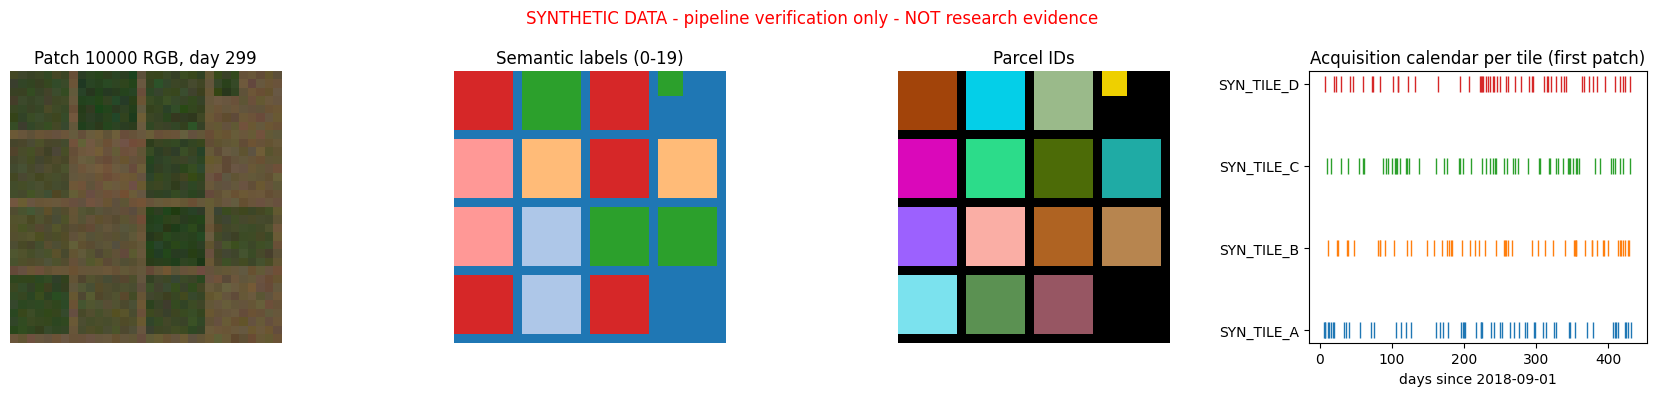

In [9]:
# 4.2 Array-level inspection of a sample of patches
def load_patch(root, pid):
    s2 = np.load(Path(root) / "DATA_S2" / f"S2_{pid}.npy")
    tgt = np.load(Path(root) / "ANNOTATIONS" / f"TARGET_{pid}.npy")
    ids = np.load(parcel_id_path(root, pid))
    sem = tgt[0] if tgt.ndim == 3 else tgt
    if ids.ndim == 3:
        ids = ids[0]
    if s2.ndim != 4 or s2.shape[1] != len(BAND_NAMES):
        raise ValueError(f"Patch {pid}: expected S2 array (T, {len(BAND_NAMES)}, H, W), got {s2.shape}. "
                         "The band axis/order assumption does not hold for this copy of the data.")
    if sem.shape != s2.shape[2:] or ids.shape != s2.shape[2:]:
        raise ValueError(f"Patch {pid}: label {sem.shape} / parcel-id {ids.shape} vs image {s2.shape[2:]}")
    return s2, sem.astype(np.int64), ids.astype(np.int64)

rows = []
for pid in META.patch_id.sample(min(8, len(META)), random_state=0):
    s2, sem, ids = load_patch(DATA_ROOT, pid)
    n_dates = int(META.loc[META.patch_id == pid, "n_dates"].iloc[0])
    if s2.shape[0] != n_dates:
        raise ValueError(f"Patch {pid}: {s2.shape[0]} images but {n_dates} dates in metadata")
    rows.append(dict(patch=pid, shape=tuple(s2.shape), dtype=str(s2.dtype), min=int(s2.min()), max=int(s2.max()),
                     nan=int(np.isnan(s2).sum()) if s2.dtype.kind == "f" else 0,
                     zero_frac=round(float((s2 == 0).mean()), 4),
                     labels=sorted(np.unique(sem).tolist())[:12], n_parcel_ids=int(len(np.unique(ids)) - (ids == 0).any())))
print(pd.DataFrame(rows).to_string(index=False))

# Visualise one patch: RGB near late June, semantic labels, parcel ids
pid = int(META.patch_id.iloc[0])
s2, sem, ids = load_patch(DATA_ROOT, pid)
days = np.array([(d - REF_DATE).days for d in META.loc[META.patch_id == pid, "dates"].iloc[0]])
t_show = int(np.argmin(np.abs(days - 300)))
rgb = np.clip(s2[t_show, [RED_IDX, 1, BLUE_IDX]].transpose(1, 2, 0) * REFLECTANCE_SCALE * 3.5, 0, 1)
fig, ax = plt.subplots(1, 4, figsize=(17, 4))
ax[0].imshow(rgb); ax[0].set_title(f"Patch {pid} RGB, day {days[t_show]}")
ax[1].imshow(sem, cmap="tab20", vmin=0, vmax=19, interpolation="nearest"); ax[1].set_title("Semantic labels (0-19)")
rng_c = np.random.default_rng(0).random((int(ids.max()) % 997 + 2, 3)) if ids.max() > 0 else np.zeros((2, 3))
ax[2].imshow(np.where(ids[..., None] > 0, rng_c[ids % len(rng_c)], 0), interpolation="nearest"); ax[2].set_title("Parcel IDs")
for tile, g in META.groupby("tile"):
    d0 = g.iloc[0]
    ax[3].plot([(d - REF_DATE).days for d in d0.dates], [tile] * d0.n_dates, "|", ms=12)
ax[3].set_title("Acquisition calendar per tile (first patch)"); ax[3].set_xlabel(f"days since {REF_DATE}")
for a in ax[:3]:
    a.axis("off")
if RESULT_BANNER:
    fig.suptitle(RESULT_BANNER, color="red")
plt.tight_layout(); fig.savefig(DIRS["figures"] / "04_patch_overview.png", dpi=110); plt.show()

## 5. Preprocessing, splits and leakage control

### 5.1 Task definition: parcel-level crop-type classification

Each parcel instance becomes one sample: the **per-date median** of its pixels for each of the 10 bands, plus acquisition days and a validity mask. The label is the **majority semantic class** of its pixels; parcels are excluded if they are background/void, smaller than `min_parcel_pixels`, less than `min_parcel_purity` pure, or have fewer than `min_obs` valid dates. Valid observations are stored first, in chronological order (padding at the end), so the temporal masking code can rely on a contiguous valid prefix. This is **not** the official PASTIS semantic-segmentation task, so numbers are not comparable with published PASTIS mIoU results.

Extraction is written in shards of `shard_size` patches and is resumable; the merged cache records a SHA-256 checksum and the exact build configuration. Normalisation statistics are computed **from training rows only**.

In [10]:
# 5.2 Build (or reuse) the parcel time-series cache
def _hash(obj, n=10):
    return hashlib.sha256(json.dumps(obj, sort_keys=True, default=str).encode()).hexdigest()[:n]

def _sha256_file(path, chunk=1 << 24):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()

def extract_patch_parcels(root, row, t_max, tile_index):
    pid = int(row.patch_id)
    s2, sem, ids = load_patch(root, pid)
    T, C, H, W = s2.shape
    if T != row.n_dates:
        raise ValueError(f"patch {pid}: {T} images but {row.n_dates} dates")
    days = np.array([(d - REF_DATE).days for d in row.dates], dtype=np.int32)
    perm = np.argsort(days, kind="stable"); s2, days = s2[perm], days[perm]
    flat = s2.reshape(T, C, H * W); idf = ids.reshape(-1); semf = sem.reshape(-1)
    order = np.argsort(idf, kind="stable")
    uniq, start, cnt = np.unique(idf[order], return_index=True, return_counts=True)
    out = {k: [] for k in ["X", "valid", "days", "y", "parcel_id", "n_pix", "purity"]}
    skip = dict(too_small=0, background_or_void=0, impure=0, too_few_obs=0)
    for u, s, c in zip(uniq, start, cnt):
        if u == 0:
            continue
        if c < HP["min_parcel_pixels"]:
            skip["too_small"] += 1; continue
        pix = order[s:s + c]
        bc = np.bincount(semf[pix], minlength=max(20, int(semf[pix].max()) + 1))
        maj = int(bc.argmax()); pur = bc[maj] / c
        if maj not in RAW_TO_IDX:
            skip["background_or_void"] += 1; continue
        if pur < HP["min_parcel_purity"]:
            skip["impure"] += 1; continue
        series = np.median(flat[:, :, pix].astype(np.float32), axis=2) * REFLECTANCE_SCALE
        valid = np.isfinite(series).all(1) & (np.abs(series).sum(1) > 0)
        nv = int(valid.sum())
        if nv < HP["min_obs"]:
            skip["too_few_obs"] += 1; continue
        o = np.argsort(~valid, kind="stable")[:nv]
        Xp = np.zeros((t_max, C), np.float16); vp = np.zeros(t_max, bool); dp = np.zeros(t_max, np.int16)
        Xp[:nv] = series[o]; vp[:nv] = True; dp[:nv] = days[o]
        for k, v in zip(out, [Xp, vp, dp, maj, int(u), int(c), pur]):
            out[k].append(v)
    n = len(out["y"])
    arrays = dict(X=np.stack(out["X"]) if n else np.zeros((0, t_max, C), np.float16),
                  valid=np.stack(out["valid"]) if n else np.zeros((0, t_max), bool),
                  days=np.stack(out["days"]) if n else np.zeros((0, t_max), np.int16),
                  y=np.array(out["y"], np.int16), parcel_id=np.array(out["parcel_id"], np.int64),
                  n_pix=np.array(out["n_pix"], np.int32), purity=np.array(out["purity"], np.float32),
                  patch_id=np.full(n, pid, np.int32), fold=np.full(n, int(row.fold), np.int8),
                  tile_idx=np.full(n, tile_index[row.tile], np.int8))
    return arrays, skip

def build_parcel_cache(root, meta, t_max):
    tiles = sorted(meta.tile.unique().tolist()); tile_index = {t: i for i, t in enumerate(tiles)}
    cfg = dict(cache_version=2, notebook_version=NOTEBOOK_VERSION, data_source=DATA_SOURCE, data_root=str(root),
               patch_ids_hash=_hash(sorted(meta.patch_id.tolist())), n_patches=len(meta), t_max=t_max,
               min_pixels=HP["min_parcel_pixels"], purity=HP["min_parcel_purity"], min_obs=HP["min_obs"],
               bands=BAND_NAMES, refl_scale=REFLECTANCE_SCALE, ref_date=str(REF_DATE), crop_labels=CROP_RAW_LABELS)
    cdir = DIRS["cache"] / f"{DATA_SOURCE}_{len(meta)}p_{_hash(cfg)}"
    final, manifest_path = cdir / "parcels.npz", cdir / "manifest.json"
    if final.exists() and manifest_path.exists():
        man = json.loads(manifest_path.read_text(encoding="utf-8"))
        if man["build_config"] != cfg:
            raise RuntimeError(f"Existing cache at {cdir} was built with a different configuration. "
                               "Move it aside or use a new WORK_DIR; it is not deleted automatically.")
        print(f"Reusing cache {final}")
        return final, man
    (cdir / "shards").mkdir(parents=True, exist_ok=True)
    chunks = [meta.iloc[i:i + HP["shard_size"]] for i in range(0, len(meta), HP["shard_size"])]
    t0 = time.time()
    for k, chunk in enumerate(chunks):
        sp = cdir / "shards" / f"shard_{k:04d}.npz"
        if sp.exists():
            try:
                with np.load(sp) as z:
                    _ = z["y"].shape
                continue
            except Exception as e:
                print(f"Shard {sp.name} unreadable ({type(e).__name__}); renaming to .corrupt and rebuilding it")
                sp.rename(sp.with_suffix(".corrupt"))
        parts, skips = [], dict(too_small=0, background_or_void=0, impure=0, too_few_obs=0)
        for row in chunk.itertuples(index=False):
            a, s = extract_patch_parcels(root, row, t_max, tile_index)
            parts.append(a)
            for kk in skips:
                skips[kk] += s[kk]
        merged = {key: np.concatenate([p[key] for p in parts]) for key in parts[0]}
        merged["skip_counts"] = np.array([skips[kk] for kk in sorted(skips)], np.int64)
        tmp = sp.with_suffix(".tmp")
        with open(tmp, "wb") as f:
            np.savez(f, **merged)
        os.replace(tmp, sp)
        el = time.time() - t0
        print(f"  shard {k+1}/{len(chunks)}: {len(merged['y'])} parcels  elapsed {el:.0f}s  "
              f"ETA {el/(k+1)*(len(chunks)-k-1):.0f}s (estimate)")
    arrays, skip_total = {}, np.zeros(4, np.int64)
    shard_files = [cdir / "shards" / f"shard_{k:04d}.npz" for k in range(len(chunks))]
    loaded = [dict(np.load(s)) for s in shard_files]
    for key in loaded[0]:
        if key == "skip_counts":
            skip_total = sum(l[key] for l in loaded)
        else:
            arrays[key] = np.concatenate([l[key] for l in loaded])
    tmp = final.with_suffix(".tmp")
    with open(tmp, "wb") as f:
        np.savez(f, **arrays)
    os.replace(tmp, final)
    man = dict(build_config=cfg, tiles=tiles, n_parcels=int(len(arrays["y"])), sha256=_sha256_file(final),
               skipped=dict(zip(sorted(["too_small", "background_or_void", "impure", "too_few_obs"]), skip_total.tolist())),
               build_seconds=round(time.time() - t0, 1), size_mb=round(final.stat().st_size / 1e6, 1))
    manifest_path.write_text(json.dumps(man, indent=2), encoding="utf-8")
    if not KEEP_SHARDS:
        for s in shard_files:
            s.unlink()
    return final, man

t0 = time.time()
CACHE_PATH, CACHE_MANIFEST = build_parcel_cache(DATA_ROOT, META, T_MAX)
CACHE = dict(np.load(CACHE_PATH))
if _sha256_file(CACHE_PATH) != CACHE_MANIFEST["sha256"]:
    raise RuntimeError(f"Checksum mismatch for {CACHE_PATH}: the cache file is corrupt. Move it aside and rebuild.")
TIMINGS = {"dataset_preparation_s": round(time.time() - t0, 1)}
N_PARCELS = len(CACHE["y"])
print(f"Parcels: {N_PARCELS}  X={CACHE['X'].shape} {CACHE['X'].dtype}  cache {CACHE_MANIFEST['size_mb']} MB  "
      f"prepared in {TIMINGS['dataset_preparation_s']} s (measured)")
print("Excluded parcels:", CACHE_MANIFEST["skipped"])
assert np.isfinite(CACHE["X"][CACHE["valid"]].astype(np.float32)).all(), "non-finite values in valid observations"
assert (CACHE["valid"].sum(1) >= HP["min_obs"]).all()
_pref = CACHE["valid"].sum(1)
assert (CACHE["valid"] == (np.arange(T_MAX)[None] < _pref[:, None])).all(), "valid observations must form a prefix"
assert set(np.unique(CACHE["y"]).tolist()) <= set(CROP_RAW_LABELS), "unexpected labels in cache"

  shard 1/1: 1895 parcels  elapsed 1s  ETA 0s (estimate)
Parcels: 1895  X=(1895, 60, 10) float16  cache 2.7 MB  prepared in 1.4 s (measured)
Excluded parcels: {'background_or_void': 63, 'impure': 0, 'too_few_obs': 0, 'too_small': 90}


In [11]:
# 5.3 Leakage-safe splits (official folds) with programmatic checks
def make_split(cache, fc, verbose=True):
    tr_f, va_f, te_f = FOLD_CONFIGS[fc]
    fold, pp, pid = cache["fold"], cache["patch_id"], cache["parcel_id"]
    if SPLIT_MODE == "official_folds":
        m = dict(train=np.isin(fold, tr_f), val=np.isin(fold, va_f), test=np.isin(fold, te_f))
    else:
        if TEST_TILE not in CACHE_MANIFEST["tiles"]:
            raise ValueError(f"TEST_TILE must be one of {CACHE_MANIFEST['tiles']}")
        te = cache["tile_idx"] == CACHE_MANIFEST["tiles"].index(TEST_TILE)
        va = (~te) & np.isin(fold, va_f)
        m = dict(train=(~te) & (~va), val=va, test=te)
    idx = {k: np.where(v)[0] for k, v in m.items()}
    rep = dict(fold_config=fc, split_mode=SPLIT_MODE, folds=dict(train=tr_f, val=va_f, test=te_f))
    for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
        shared = np.intersect1d(pp[idx[a]], pp[idx[b]])
        assert len(shared) == 0, f"Patch leakage between {a} and {b}: {shared[:5]}"
    # Parcel-ID duplicates across patches (border-cut parcels) - only meaningful if IDs are global
    per_id_patches = pd.Series(pp).groupby(pid).nunique()
    frac_multi = float((per_id_patches > 1).mean())
    rep["parcel_ids_in_multiple_patches_frac"] = round(frac_multi, 4)
    if frac_multi < 0.2:
        held = np.union1d(pid[idx["val"]], pid[idx["test"]])
        dup = np.isin(pid[idx["train"]], held)
        rep["train_rows_dropped_shared_parcel_id"] = int(dup.sum())
        idx["train"] = idx["train"][~dup]
        rep["val_test_shared_parcel_ids"] = int(len(np.intersect1d(pid[idx["val"]], pid[idx["test"]])))
    else:
        rep["warning"] = "parcel IDs look patch-local; cross-patch duplicate check skipped"
    idx["pretrain"] = idx["train"].copy()          # STRICT inductive protocol: SSL sees training folds only
    for a, b in [("train", "val"), ("train", "test"), ("val", "test"), ("pretrain", "val"), ("pretrain", "test")]:
        assert len(np.intersect1d(idx[a], idx[b])) == 0, f"row overlap {a}/{b}"
    assert np.isin(idx["pretrain"], idx["train"]).all()
    assert not np.isin(pp[idx["pretrain"]], pp[np.concatenate([idx["val"], idx["test"]])]).any()
    y = cache["y"]
    for k in ("train", "val", "test"):
        rep[f"n_{k}"] = int(len(idx[k]))
        present = set(np.unique(y[idx[k]]).tolist())
        rep[f"classes_missing_in_{k}"] = [RAW_CLASS_NAMES[c] for c in CROP_RAW_LABELS if c not in present]
    rep["split_hash"] = _hash({k: np.sort(np.unique(pp[v])).tolist() for k, v in idx.items()})
    path = DIRS["runs"] / f"split_fc{fc}.json"
    path.write_text(json.dumps(dict(report=rep, patches={k: np.unique(pp[v]).tolist() for k, v in idx.items()}),
                               indent=1), encoding="utf-8")
    if verbose:
        print(json.dumps(rep, indent=1))
    return idx, rep

SPLIT0, SPLIT0_REPORT = make_split(CACHE, P["fold_configs"][0])

{
 "fold_config": 0,
 "split_mode": "official_folds",
 "folds": {
  "train": [
   1,
   2,
   3
  ],
  "val": [
   4
  ],
  "test": [
   5
  ]
 },
 "parcel_ids_in_multiple_patches_frac": 0.0134,
 "train_rows_dropped_shared_parcel_id": 13,
 "val_test_shared_parcel_ids": 2,
 "n_train": 1057,
 "classes_missing_in_train": [],
 "n_val": 458,
 "classes_missing_in_val": [],
 "n_test": 367,
 "classes_missing_in_test": [],
 "split_hash": "ce243c44c5"
}


                     train  val  test  train_share_%
syn_winter_cereal_A    231  117   109          21.85
syn_summer_crop_A      219   86    74          20.72
syn_meadow             201   77    56          19.02
syn_rapeseed_like      104   48    37           9.84
syn_double_crop         95   41    30           8.99
syn_summer_crop_B       80   32    21           7.57
syn_winter_cereal_B     76   31    22           7.19
syn_late_summer         51   26    18           4.82

Imbalance ratio (largest/smallest training class): 5x  -> macro-F1 is the primary metric

Band-order / data plausibility: {
 "median_parcel_max_ndvi": 0.7061478495597839,
 "frac_obs_ndvi_below_m0.1": 0.0,
 "frac_obs_blue_above_thresh_cloud_proxy": 0.1208,
 "valid_obs_per_parcel": {
  "min": 50.0,
  "mean": 55.5,
  "max": 60.0
 }
}
Band-order check passed (NIR/red mapping produces plausible crop NDVI).


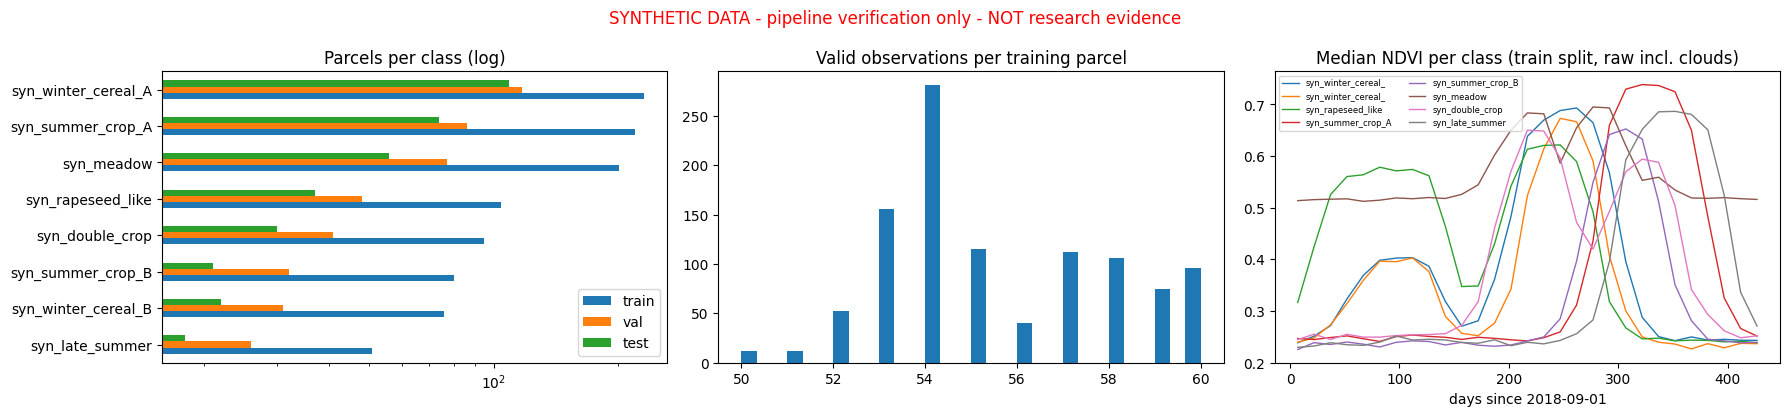

In [12]:
# 5.4 Training-only normalisation, GPU-resident data store, and parcel-level audit
def norm_stats(cache, rows, chunk=20000):
    C = cache["X"].shape[2]
    s = np.zeros(C); ss = np.zeros(C); n = 0
    for i in range(0, len(rows), chunk):
        r = rows[i:i + chunk]
        v = cache["X"][r].astype(np.float64)[cache["valid"][r]]
        s += v.sum(0); ss += (v ** 2).sum(0); n += len(v)
    mean = s / n
    std = np.sqrt(np.maximum(ss / n - mean ** 2, 0)) + 1e-6
    return mean.astype(np.float32), std.astype(np.float32)

class ParcelStore:
    """Normalised parcel series (float16) kept on the GPU when they fit, else in CPU memory."""
    def __init__(self, cache, mean, std, device):
        N, T, C = cache["X"].shape
        host = torch.empty((N, T, C), dtype=torch.float16)
        for s in range(0, N, 20000):
            xs = (cache["X"][s:s + 20000].astype(np.float32) - mean) / std
            xs[~cache["valid"][s:s + 20000]] = 0.0
            host[s:s + 20000] = torch.from_numpy(xs.astype(np.float16))
        lut = np.full(256, -1, np.int64)
        for r, i in RAW_TO_IDX.items():
            lut[r] = i
        y = lut[cache["y"].astype(np.int64)]
        assert (y >= 0).all(), "label outside the crop-class mapping"
        self.device = device
        self.on_gpu = device.type == "cuda" and host.numel() * 2 / 1e6 <= KEEP_DATA_ON_GPU_MAX_MB
        home = device if self.on_gpu else torch.device("cpu")
        self.X = host.to(home)
        self.days = torch.from_numpy(cache["days"].astype(np.float32)).to(home)
        self.valid = torch.from_numpy(cache["valid"]).to(home)
        self.y = torch.from_numpy(y).to(home)
        self.lengths = self.valid.sum(1)
        self.mean, self.std = mean, std

    def batch(self, idx, valid_override=None):
        idx = torch.as_tensor(idx, device=self.X.device)
        x = self.X[idx].to(self.device, non_blocking=True).float()
        d = self.days[idx].to(self.device, non_blocking=True)
        v = (self.valid[idx] if valid_override is None else valid_override).to(self.device, non_blocking=True)
        y = self.y[idx].to(self.device, non_blocking=True)
        return x, d, v, y

def ndvi_np(X):
    X = X.astype(np.float32)
    return np.clip((X[..., NIR_IDX] - X[..., RED_IDX]) / (X[..., NIR_IDX] + X[..., RED_IDX] + 1e-6), -1, 1)

# ---- Parcel-level audit on fold configuration 0 (labels of the TRAINING split only for curves) ----
y_raw = CACHE["y"]
counts = pd.DataFrame({k: pd.Series(y_raw[SPLIT0[k]]).map(RAW_CLASS_NAMES).value_counts() for k in ("train", "val", "test")}).fillna(0).astype(int)
counts["train_share_%"] = (100 * counts["train"] / counts["train"].sum()).round(2)
print(counts.sort_values("train", ascending=False).to_string())
imb = counts["train"].max() / max(counts["train"].replace(0, np.nan).min(), 1)
print(f"\nImbalance ratio (largest/smallest training class): {imb:.0f}x  -> macro-F1 is the primary metric")

tr = SPLIT0["train"]
nd = ndvi_np(CACHE["X"][tr]); vv = CACHE["valid"][tr]
max_ndvi = np.where(vv, nd, -1).max(1)
blue = CACHE["X"][tr][..., BLUE_IDX].astype(np.float32)
cloud_proxy = float((blue[vv] > HP["pheno_cloud_blue_thresh"]).mean())
BAND_CHECK = {"median_parcel_max_ndvi": float(np.median(max_ndvi)),
              "frac_obs_ndvi_below_m0.1": float((nd[vv] < -0.1).mean()),
              "frac_obs_blue_above_thresh_cloud_proxy": round(cloud_proxy, 4),
              "valid_obs_per_parcel": {k: float(v) for k, v in pd.Series(vv.sum(1)).describe()[["min", "mean", "max"]].round(1).items()}}
print("\nBand-order / data plausibility:", json.dumps(BAND_CHECK, indent=1))
if BAND_CHECK["median_parcel_max_ndvi"] < 0.4 or BAND_CHECK["frac_obs_ndvi_below_m0.1"] > 0.2:
    raise RuntimeError("Band-order check FAILED: vegetation NDVI is implausible. Verify BAND_NAMES/RED_IDX/NIR_IDX "
                       "against the dataset documentation before continuing.")
print("Band-order check passed (NIR/red mapping produces plausible crop NDVI).")

fig, ax = plt.subplots(1, 3, figsize=(18, 4.2))
counts[["train", "val", "test"]].sort_values("train").plot.barh(ax=ax[0], logx=True); ax[0].set_title("Parcels per class (log)")
ax[1].hist(vv.sum(1), bins=30); ax[1].set_title("Valid observations per training parcel")
bins = np.arange(0, 450, 15)
dd = CACHE["days"][tr]
for r in CROP_RAW_LABELS:
    sel = y_raw[tr] == r
    if sel.sum() == 0:
        continue
    d_, n_ = dd[sel][vv[sel]], nd[sel][vv[sel]]
    b = np.digitize(d_, bins)
    med = [np.median(n_[b == i]) if (b == i).sum() > 5 else np.nan for i in range(1, len(bins))]
    ax[2].plot(bins[:-1] + 7, med, label=RAW_CLASS_NAMES[r][:18], lw=1)
ax[2].set_title("Median NDVI per class (train split, raw incl. clouds)"); ax[2].set_xlabel(f"days since {REF_DATE}")
ax[2].legend(fontsize=6, ncol=2)
if RESULT_BANNER:
    fig.suptitle(RESULT_BANNER, color="red")
plt.tight_layout(); fig.savefig(DIRS["figures"] / "05_parcel_audit.png", dpi=110); plt.show()
counts.to_csv(DIRS["tables"] / "class_counts_fc0.csv")

## 6. Model components and the temporal JEPA objective

**Tokens.** Each valid acquisition of a parcel is one token: $\mathrm{LN}(W_x x_t) + W_d\,e(\text{day}_t)$, where $e$ is a fixed sinusoidal encoding of the day since 2018-09-01 and $W_d$ is a learned projection initialised small, so that **content dominates the date signal at initialisation**. (A plain sum $W_x x_t + e(\text{day}_t)$ let the date dominate and produced a *positional shortcut* during validation: targets became predictable from dates alone. It is kept as the ablation `token_embed='raw_sum'`, and the share of target variance explained by date is monitored every epoch.) Padding and removed observations are excluded as attention *keys*.

**Encoder** $f_\theta$: pre-LayerNorm transformer (`d_model`, `depth`, `heads` from the profile), final LayerNorm.

**JEPA forward pass** for a batch with validity mask $V$, context mask $C \subseteq V$ and target blocks $B_1..B_M \subseteq V \setminus C$:

1. Target path (no gradient): $\bar h = \mathrm{LN}(f_{\bar\theta}(x; \text{keys}=V))$ — the EMA target encoder sees the **full** series; targets are selected *from its output*.
2. Context path: $h = f_\theta(x; \text{keys}=C)$. Tokens outside $C$ are never attended to, so target content cannot leak into context representations (verified in Section 10).
3. Predictor $g_\phi$ (narrow transformer), one pass per block $m$: inputs are $W h_t + e(\text{day}_t)$ for $t \in C$ and a learned mask token $+\,e(\text{day}_t)$ for $t \in B_m$.
4. Loss: $\mathcal{L} = \frac{1}{\sum_m |B_m|} \sum_m \sum_{t \in B_m} \ell\big(g_\phi(\cdot)_t, \bar h_t\big)$ with $\ell$ = smooth-L1 (default) or squared error, averaged over feature dimensions.
5. After each optimiser step: $\bar\theta \leftarrow \tau \bar\theta + (1-\tau)\theta$, with $\tau$ increasing linearly from 0.996 to 1.0.

Downstream representations are the **average-pooled outputs of the EMA target encoder** over valid tokens. The supervised baseline uses an identical encoder architecture trained from scratch with a linear head, so model capacity is matched.

In [13]:
# 6.1 Encoder, classifier, predictor and temporal JEPA
def date_encoding(days, dim, max_period=1000.0):
    half = dim // 2
    freqs = torch.exp(-math.log(max_period) * torch.arange(half, device=days.device, dtype=torch.float32) / max(half, 1))
    ang = days.float().unsqueeze(-1) * freqs
    enc = torch.cat([torch.sin(ang), torch.cos(ang)], dim=-1)
    return F.pad(enc, (0, 1)) if dim % 2 else enc

class MaskedSelfAttention(nn.Module):
    def __init__(self, dim, heads, dropout=0.0):
        super().__init__()
        assert dim % heads == 0, "dim must be divisible by heads"
        self.heads, self.dropout = heads, dropout
        self.qkv = nn.Linear(dim, 3 * dim)
        self.proj = nn.Linear(dim, dim)

    def forward(self, x, key_mask):          # key_mask: [B,T] True = may be attended to
        B, T, D = x.shape
        qkv = self.qkv(x).reshape(B, T, 3, self.heads, D // self.heads).permute(2, 0, 3, 1, 4)
        out = F.scaled_dot_product_attention(qkv[0], qkv[1], qkv[2], attn_mask=key_mask[:, None, None, :],
                                             dropout_p=self.dropout if self.training else 0.0)
        return self.proj(out.transpose(1, 2).reshape(B, T, D))

class TransformerBlock(nn.Module):
    def __init__(self, dim, heads, mlp_ratio=4.0, dropout=0.0):
        super().__init__()
        self.n1, self.n2 = nn.LayerNorm(dim), nn.LayerNorm(dim)
        self.attn = MaskedSelfAttention(dim, heads, dropout)
        hid = int(dim * mlp_ratio)
        self.mlp = nn.Sequential(nn.Linear(dim, hid), nn.GELU(), nn.Dropout(dropout), nn.Linear(hid, dim))
        self.drop = nn.Dropout(dropout)

    def forward(self, x, key_mask):
        x = x + self.drop(self.attn(self.n1(x), key_mask))
        return x + self.drop(self.mlp(self.n2(x)))

def _init_weights(m):
    if isinstance(m, nn.Linear):
        nn.init.trunc_normal_(m.weight, std=0.02)
        if m.bias is not None:
            nn.init.zeros_(m.bias)
    elif isinstance(m, nn.LayerNorm):
        nn.init.ones_(m.weight); nn.init.zeros_(m.bias)

TOKEN_EMBEDS = ("ln_content_learned_date", "raw_sum")

class TemporalEncoder(nn.Module):
    """token_embed='ln_content_learned_date' (default): LN(W_x x) + W_d e(day), W_d small-init, so content dominates
    at initialisation. 'raw_sum': W_x x + e(day) - kept only as an ablation; it lets the fixed date encoding dominate
    and produced a positional shortcut in validation (see VALIDATION_REPORT.md)."""
    def __init__(self, in_ch, d_model, depth, heads, token_embed="ln_content_learned_date", mlp_ratio=4.0, dropout=0.0):
        super().__init__()
        assert token_embed in TOKEN_EMBEDS
        self.d_model, self.token_embed = d_model, token_embed
        self.in_proj = nn.Linear(in_ch, d_model)
        self.in_norm = nn.LayerNorm(d_model) if token_embed != "raw_sum" else nn.Identity()
        self.date_proj = nn.Linear(d_model, d_model) if token_embed != "raw_sum" else nn.Identity()
        self.blocks = nn.ModuleList([TransformerBlock(d_model, heads, mlp_ratio, dropout) for _ in range(depth)])
        self.norm = nn.LayerNorm(d_model)
        self.apply(_init_weights)

    def embed(self, x, days):
        return self.in_norm(self.in_proj(x)), self.date_proj(date_encoding(days, self.d_model))

    def forward(self, x, days, key_mask):
        c, e = self.embed(x, days)
        h = c + e
        for blk in self.blocks:
            h = blk(h, key_mask)
        return self.norm(h)

def masked_mean(h, mask):
    m = mask.unsqueeze(-1).to(h.dtype)
    return (h * m).sum(1) / m.sum(1).clamp_min(1.0)

class ParcelClassifier(nn.Module):
    def __init__(self, encoder, n_classes, dropout=0.1):
        super().__init__()
        self.encoder, self.drop = encoder, nn.Dropout(dropout)
        self.head = nn.Linear(encoder.d_model, n_classes)
        nn.init.trunc_normal_(self.head.weight, std=0.02); nn.init.zeros_(self.head.bias)

    def forward(self, x, days, valid):
        return self.head(self.drop(masked_mean(self.encoder(x, days, valid), valid)))

class TemporalPredictor(nn.Module):
    def __init__(self, enc_dim, pred_dim, depth, heads, token_embed="ln_content_learned_date"):
        super().__init__()
        self.pred_dim = pred_dim
        self.date_proj = nn.Linear(pred_dim, pred_dim) if token_embed != "raw_sum" else nn.Identity()
        self.in_proj = nn.Linear(enc_dim, pred_dim)
        self.mask_token = nn.Parameter(torch.zeros(pred_dim))
        self.blocks = nn.ModuleList([TransformerBlock(pred_dim, heads) for _ in range(depth)])
        self.norm = nn.LayerNorm(pred_dim)
        self.out_proj = nn.Linear(pred_dim, enc_dim)
        self.apply(_init_weights)
        nn.init.trunc_normal_(self.mask_token, std=0.02)

    def forward(self, ctx_h, days, ctx_mask, tgt_mask):
        z = self.in_proj(ctx_h)
        pe = self.date_proj(date_encoding(days, self.pred_dim)).to(z.dtype)
        z = torch.where(tgt_mask.unsqueeze(-1), self.mask_token.to(z.dtype) + pe, z + pe)
        attend = ctx_mask | tgt_mask
        for blk in self.blocks:
            z = blk(z, attend)
        return self.out_proj(self.norm(z))

class TemporalJEPA(nn.Module):
    def __init__(self, in_ch, d_model, depth, heads, pred_dim, pred_depth, token_embed="ln_content_learned_date", loss_type="smooth_l1"):
        super().__init__()
        self.context_encoder = TemporalEncoder(in_ch, d_model, depth, heads, token_embed)
        self.target_encoder = copy.deepcopy(self.context_encoder)
        for p in self.target_encoder.parameters():
            p.requires_grad_(False)
        self.predictor = TemporalPredictor(d_model, pred_dim, pred_depth, max(1, pred_dim // 16), token_embed)
        assert loss_type in ("smooth_l1", "l2")
        self.loss_type = loss_type

    def train(self, mode=True):
        super().train(mode)
        self.target_encoder.eval()          # the EMA teacher is never in training mode
        return self

    def forward(self, x, days, valid, masks):
        with torch.no_grad():
            h_t = self.target_encoder(x, days, valid)
            h_t = F.layer_norm(h_t.float(), (h_t.shape[-1],))
        h_c = self.context_encoder(x, days, masks.ctx)
        num = torch.zeros((), device=x.device, dtype=torch.float32)
        den = torch.zeros((), device=x.device, dtype=torch.float32)
        for m in range(masks.blocks.shape[1]):
            bm = masks.blocks[:, m]
            pred = self.predictor(h_c, days, masks.ctx, bm).float()
            if self.loss_type == "smooth_l1":
                el = F.smooth_l1_loss(pred, h_t, reduction="none").mean(-1)
            else:
                el = ((pred - h_t) ** 2).mean(-1)
            w = bm.float() * masks.weight[:, None]
            num = num + torch.where(w > 0, el * w, torch.zeros_like(el)).sum()
            den = den + w.sum()
        return num / den.clamp_min(1.0), den

    @torch.no_grad()
    def ema_update(self, momentum):
        for pt, pc in zip(self.target_encoder.parameters(), self.context_encoder.parameters()):
            pt.mul_(momentum).add_(pc.detach(), alpha=1.0 - momentum)
        for bt, bc in zip(self.target_encoder.buffers(), self.context_encoder.buffers()):
            bt.copy_(bc)

def n_params(m, trainable_only=False):
    return sum(p.numel() for p in m.parameters() if p.requires_grad or not trainable_only)

MODEL_CFG = dict(in_ch=len(BAND_NAMES), d_model=P["d_model"], depth=P["depth"], heads=P["heads"],
                 pred_dim=P["pred_dim"], pred_depth=P["pred_depth"], token_embed=HP["token_embed"])
ENC_KEYS = ("in_ch", "d_model", "depth", "heads", "token_embed")
_tmp = TemporalJEPA(**MODEL_CFG)
print(f"Encoder params: {n_params(_tmp.context_encoder):,}   Predictor params: {n_params(_tmp.predictor):,}   "
      f"(target encoder is an EMA copy, not trained by gradients)")
del _tmp

Encoder params: 105,088   Predictor params: 30,752   (target encoder is an EMA copy, not trained by gradients)


## 7. Target-selection policies — baseline, research modification, and controls

All policies share **exactly the same masking machinery**: $M=4$ target blocks of contiguous valid observations, each block length drawn as `round(U(0.08, 0.15) · L)` (L = number of valid observations), placed **without overlap**, followed by a contiguous context window of `U(0.85, 1.0) · L` observations from which target tokens are removed. Because block lengths are drawn identically and blocks do not overlap, every policy masks the same number of tokens in distribution (a test in Section 10 verifies this). **Policies differ only in where block starts are sampled.**

For each block, the start $s$ is drawn from feasible (non-overlapping, in-range) starts with probability

$$p(s) = (1-\varepsilon)\,\frac{W(s)}{\sum_{s'} W(s')} + \varepsilon\,\frac{1}{|\mathcal{S}_{\text{feasible}}|}, \qquad W(s) = \sum_{t=s}^{s+\ell-1} w_t ,$$

with $\varepsilon = 0.2$ (uniform mixing keeps every placement possible). The per-observation weights $w_t$ define the policy:

| Policy | $w_t$ | Role |
|---|---|---|
| `random_block` | $1$ | **Unmodified baseline** (I-JEPA analogue: uniform placement) |
| `phenology` | $r_t^\alpha$, where $r_t$ = per-sample-normalised $\lvert d\,\mathrm{NDVI}/dt\rvert$ of the cloud-screened, running-median-smoothed NDVI trajectory | **Research modification**: targets concentrate on green-up, senescence and harvest transitions |
| `spectral_change` | normalised rate of change of the full 10-band (z-scored) spectrum | Control: is any *generic* change-based placement enough? |
| `inverse_phenology` | $(1-r_t)^\alpha + 10^{-3}$ | Control: is the *direction* of the effect phenological? |

**Operational definition of the phenology signal (label-free, input-only, per sample):** NDVI $=(B8-B4)/(B8+B4)$; observations with blue reflectance $> 0.25$ are treated as cloud-contaminated and their NDVI is linearly interpolated from clear neighbours (if ≥ 2 clear observations exist); a running median (window 3) suppresses residual single-date spikes; $r_t = |s_{t+1}-s_{t-1}| / (d_{t+1}-d_{t-1})$ with one-sided differences at the ends, divided by the per-sample maximum. Weights are computed **only for pretraining rows** and **never use labels**. Crop calendars derived from labelled data are deliberately *not* used, as that would leak label information into self-supervised pretraining.

In [14]:
# 7.1 Policy weights (label-free) and the temporal multi-block mask sampler
from dataclasses import dataclass
POLICIES = ("random_block", "phenology", "spectral_change", "inverse_phenology")

def running_median_prefix(s, lengths, window):
    """Edge-padded running median along time within each sample's valid prefix. s: [N,T]."""
    h = window // 2
    t = np.arange(s.shape[1])[None, :]
    Lm1 = np.maximum(lengths[:, None] - 1, 0)
    stack = [np.take_along_axis(s, np.clip(t + k, 0, Lm1), axis=1) for k in range(-h, h + 1)]
    return np.median(np.stack(stack, -1), -1)

def temporal_change_rate(s, days, lengths):
    """|central difference| per day inside the valid prefix. s: [N,T] or [N,T,C] (L2 norm over C)."""
    t = np.arange(s.shape[1])[None, :]
    Lm1 = np.maximum(lengths[:, None] - 1, 0)
    prev, nxt = np.clip(t - 1, 0, Lm1), np.clip(t + 1, 0, Lm1)
    if s.ndim == 2:
        mag = np.abs(np.take_along_axis(s, nxt, 1) - np.take_along_axis(s, prev, 1))
    else:
        ds = np.take_along_axis(s, nxt[..., None], 1) - np.take_along_axis(s, prev[..., None], 1)
        mag = np.sqrt((ds ** 2).sum(-1))
    dd = (np.take_along_axis(days, nxt, 1) - np.take_along_axis(days, prev, 1)).astype(np.float32)
    rate = mag / np.maximum(dd, 1.0)
    rate[t >= lengths[:, None]] = 0.0
    return rate.astype(np.float32)

def phenology_rate(cache, rows):
    X = cache["X"][rows].astype(np.float32)
    valid = cache["valid"][rows]; days = cache["days"][rows].astype(np.float32); L = valid.sum(1)
    nd = ndvi_np(X)
    cloudy = (X[..., BLUE_IDX] > HP["pheno_cloud_blue_thresh"]) & valid
    for i in np.where(cloudy.any(1))[0]:
        l = L[i]; c = cloudy[i, :l]; clear = ~c
        if clear.sum() >= 2:
            row = nd[i, :l]
            row[c] = np.interp(days[i, :l][c], days[i, :l][clear], row[clear])
    sm = running_median_prefix(nd, L, HP["pheno_smooth_window"])
    return temporal_change_rate(sm, days, L)

def _norm_rows(r):
    return r / (r.max(1, keepdims=True) + 1e-8)

def policy_center_weights(policy, cache, rows, mean, std, pheno_rate=None):
    valid = cache["valid"][rows]; L = valid.sum(1); a = HP["policy_alpha"]
    if policy == "random_block":
        w = valid.astype(np.float32)
    elif policy in ("phenology", "inverse_phenology"):
        sn = _norm_rows(pheno_rate if pheno_rate is not None else phenology_rate(cache, rows))
        w = sn ** a if policy == "phenology" else (1.0 - sn) ** a + 1e-3
    elif policy == "spectral_change":
        Z = (cache["X"][rows].astype(np.float32) - mean) / std
        Zs = np.stack([running_median_prefix(Z[..., c], L, HP["pheno_smooth_window"]) for c in range(Z.shape[-1])], -1)
        w = _norm_rows(temporal_change_rate(Zs, cache["days"][rows].astype(np.float32), L)) ** a
    else:
        raise ValueError(f"unknown policy {policy}")
    return np.where(valid, w, 0.0).astype(np.float32)

@dataclass
class MaskBatch:
    ctx: torch.Tensor          # [B,T] bool, context tokens
    blocks: torch.Tensor       # [B,M,T] bool, target blocks
    weight: torch.Tensor       # [B] float, 0 for samples excluded from the loss
    n_fallback: int            # blocks that had to overlap because no free window existed

class TemporalBlockMaskSampler:
    def __init__(self, n_blocks, block_scale, context_scale, min_context, epsilon):
        self.M, self.bs, self.cs = n_blocks, block_scale, context_scale
        self.min_ctx, self.eps = min_context, epsilon

    @torch.no_grad()
    def sample(self, lengths, weights, gen):
        B, T = weights.shape
        dev = weights.device
        ar = torch.arange(T, device=dev)
        L = lengths.long().clamp_min(1)
        Lf = L.float()
        valid = ar[None] < L[:, None]
        w = torch.where(valid, weights.float().clamp_min(0), torch.zeros((), device=dev))
        cw = F.pad(torch.cumsum(w, 1), (1, 0))
        union = torch.zeros(B, T, dtype=torch.bool, device=dev)
        blocks = torch.zeros(B, self.M, T, dtype=torch.bool, device=dev)
        n_fallback = 0
        for m in range(self.M):
            u = torch.rand(B, generator=gen, device=dev)
            blen = torch.round((self.bs[0] + u * (self.bs[1] - self.bs[0])) * Lf).long().clamp_min(1)
            blen = torch.minimum(blen, (L - 1).clamp_min(1))
            end = ar[None] + blen[:, None]
            in_range = end <= L[:, None]
            endc = end.clamp(max=T)
            wsum = torch.gather(cw, 1, endc) - cw[:, :T]
            cu = F.pad(torch.cumsum(union.long(), 1), (1, 0))
            covered = torch.gather(cu, 1, endc) - cu[:, :T]
            feasible = in_range & (covered == 0)
            none = ~feasible.any(1)
            if bool(none.any()):
                n_fallback += int(none.sum())
                feasible = torch.where(none[:, None], in_range, feasible)
            nf = feasible.float()
            nf_norm = nf / nf.sum(1, keepdim=True).clamp_min(1.0)
            ws = wsum * nf
            tot = ws.sum(1, keepdim=True)
            p_w = torch.where(tot > 0, ws / tot.clamp_min(1e-12), nf_norm)
            p = (1 - self.eps) * p_w + self.eps * nf_norm
            s = torch.multinomial(p, 1, generator=gen).squeeze(1)
            blk = (ar[None] >= s[:, None]) & (ar[None] < (s + blen)[:, None])
            blocks[:, m] = blk
            union |= blk
        clen = torch.round((self.cs[0] + torch.rand(B, generator=gen, device=dev) * (self.cs[1] - self.cs[0])) * Lf).long()
        clen = torch.minimum(clen.clamp_min(1), L)
        cstart = torch.floor(torch.rand(B, generator=gen, device=dev) * (L - clen + 1).float()).long()
        window = (ar[None] >= cstart[:, None]) & (ar[None] < (cstart + clen)[:, None])
        ctx = window & valid & ~union
        bad = ctx.sum(1) < self.min_ctx
        if bool(bad.any()):                       # repair: keep only the first target block
            blocks[bad, 1:] = False
            union = blocks.any(1)
            ctx = window & valid & ~union
        ok = ctx.sum(1) >= self.min_ctx
        ctx = torch.where(ok[:, None], ctx, valid)  # excluded samples: harmless full context, zero loss weight
        blocks = blocks & ok[:, None, None]
        return MaskBatch(ctx=ctx, blocks=blocks, weight=ok.float(), n_fallback=n_fallback)

def make_sampler():
    return TemporalBlockMaskSampler(HP["n_target_blocks"], HP["target_block_scale"], HP["context_scale"],
                                    HP["min_context_tokens"], HP["policy_epsilon"])

@torch.no_grad()
def placement_stats(masks, valid, pheno_norm, days):
    """Diagnostics: masked-token budget and phenological 'enrichment' of target tokens."""
    tgt = masks.blocks.any(1) & (masks.weight[:, None] > 0)
    vf = valid.float().sum().clamp_min(1)
    enrich = (pheno_norm[tgt].mean() / pheno_norm[valid].mean().clamp_min(1e-8)).item() if tgt.any() else float("nan")
    return dict(target_frac=(tgt.float().sum() / vf).item(), context_frac=(masks.ctx.float().sum() / vf).item(),
                pheno_enrichment=enrich, mean_target_day=days[tgt].float().mean().item() if tgt.any() else float("nan"),
                excluded_samples=int((masks.weight == 0).sum()), fallback_blocks=masks.n_fallback)

## 8. Metrics and evaluation utilities

Parcel-level classification metrics only (no segmentation metrics): **macro-F1 (primary)**, balanced accuracy (= mean per-class recall), overall accuracy, per-class precision/recall/F1 and the confusion matrix. Macro averages are taken over classes **present in the evaluated ground truth**. Paired-bootstrap confidence intervals resample test parcels with the same indices for both methods.

**Missing-observation protocol (pre-declared):** for each test parcel, a fixed random key is drawn per observation (seed `missing_eval_seed`); at removal rate $r$, the $\lfloor rL \rfloor$ observations with the smallest keys are removed, always keeping at least 3. Masks are therefore **identical for every model** and **nested** across rates. A second scenario removes all observations between 1 May and 30 June 2019 (simulated persistent cloud cover in the main growing season).

In [15]:
# 8.1 Metrics, bootstrap, missing-observation scenarios, inference helpers, collapse diagnostics
def confusion_np(y, p, K):
    return np.bincount(np.asarray(y) * K + np.asarray(p), minlength=K * K).reshape(K, K)

def metrics_from_cm(cm):
    tp = np.diag(cm).astype(float); sup = cm.sum(1).astype(float); pred = cm.sum(0).astype(float)
    present = sup > 0
    prec = np.divide(tp, pred, out=np.zeros_like(tp), where=pred > 0)
    rec = np.divide(tp, sup, out=np.zeros_like(tp), where=sup > 0)
    f1 = np.divide(2 * prec * rec, prec + rec, out=np.zeros_like(tp), where=(prec + rec) > 0)
    return dict(macro_f1=float(f1[present].mean()) if present.any() else float("nan"),
                balanced_accuracy=float(rec[present].mean()) if present.any() else float("nan"),
                overall_accuracy=float(tp.sum() / max(cm.sum(), 1)),
                per_class_f1=f1.round(5).tolist(), per_class_precision=prec.round(5).tolist(),
                per_class_recall=rec.round(5).tolist(), support=sup.astype(int).tolist(),
                n_classes_present=int(present.sum()))

def compute_metrics(y, p, K=None, with_cm=True):
    K = K or N_CLASSES
    cm = confusion_np(y, p, K)
    m = metrics_from_cm(cm)
    if with_cm:
        m["confusion"] = cm.tolist()
    return m

def paired_bootstrap(y, pa, pb, K, reps, seed=0):
    rng = np.random.default_rng(seed); n = len(y); diffs = np.empty(reps)
    for r in range(reps):
        i = rng.integers(0, n, n)
        diffs[r] = metrics_from_cm(confusion_np(y[i], pa[i], K))["macro_f1"] - metrics_from_cm(confusion_np(y[i], pb[i], K))["macro_f1"]
    point = metrics_from_cm(confusion_np(y, pa, K))["macro_f1"] - metrics_from_cm(confusion_np(y, pb, K))["macro_f1"]
    return dict(diff=float(point), ci_low=float(np.percentile(diffs, 2.5)), ci_high=float(np.percentile(diffs, 97.5)))

def make_missing_scenarios(store, rows, rates, gap, seed, min_keep):
    valid = store.valid[torch.as_tensor(rows, device=store.valid.device)].cpu().numpy()
    days = store.days[torch.as_tensor(rows, device=store.days.device)].cpu().numpy()
    u = np.random.default_rng(seed).random(valid.shape); u[~valid] = np.inf
    rank = np.argsort(np.argsort(u, axis=1, kind="stable"), axis=1, kind="stable")
    L = valid.sum(1)
    out = {}
    for r in rates:
        k = np.minimum(np.floor(r * L), np.maximum(L - min_keep, 0)).astype(int)
        keep = valid & ~(rank < k[:, None])
        out["full" if r == 0 else f"drop{int(round(r * 100))}"] = torch.from_numpy(keep)
    if "full" not in out:
        out["full"] = torch.from_numpy(valid)
    if gap:
        lo, hi = HP["gap_window_days"]
        keep = valid & ~((days >= lo) & (days <= hi))
        short = keep.sum(1) < min_keep
        if short.any():
            keep[short] |= (valid & (rank < min_keep))[short]
        out["gap_may_jun"] = torch.from_numpy(keep)
    return out

@torch.no_grad()
def predict_logits(model, store, rows, valid_override=None, bs=1024):
    model.eval(); outs = []
    for s in range(0, len(rows), bs):
        vo = None if valid_override is None else valid_override[s:s + bs]
        x, d, v, _ = store.batch(rows[s:s + bs], vo)
        with autocast_ctx():
            outs.append(model(x, d, v).float().cpu())
    return torch.cat(outs).numpy()

@torch.no_grad()
def extract_features(encoder, store, rows, valid_override=None, bs=1024):
    encoder.eval(); outs = []
    for s in range(0, len(rows), bs):
        vo = None if valid_override is None else valid_override[s:s + bs]
        x, d, v, _ = store.batch(rows[s:s + bs], vo)
        with autocast_ctx():
            h = encoder(x, d, v)
        outs.append(masked_mean(h.float(), v).cpu())
    return torch.cat(outs)

@torch.no_grad()
def embedding_diagnostics(Z):
    Z = Z.float().cpu()
    Zc = Z - Z.mean(0, keepdim=True)
    s = torch.linalg.svdvals(Zc)
    p = s / s.sum().clamp_min(1e-12)
    erank = float(torch.exp(-(p * torch.log(p.clamp_min(1e-12))).sum()))
    Zn = F.normalize(Z, dim=1)
    perm = torch.randperm(len(Z), generator=torch.Generator().manual_seed(0))
    return dict(mean_dim_std=float(Z.std(0).mean()), effective_rank=erank,
                mean_pair_cosine=float((Zn * Zn[perm]).sum(1).mean()))

@torch.no_grad()
def date_variance_ratio(Z, days, bin_days=15):
    """Share of token-feature variance explained by acquisition date alone (between-bin / total variance).
    Values near 1 mean target representations mostly encode WHEN, not WHAT: a positional shortcut."""
    Z = Z.float().cpu(); b = torch.div(days.float().cpu(), bin_days, rounding_mode="floor").long()
    mu = Z.mean(0); tot = ((Z - mu) ** 2).sum(1).mean()
    nb = int(b.max()) + 1
    cnt = torch.bincount(b, minlength=nb).float()
    means = torch.zeros(nb, Z.shape[1]).index_add_(0, b, Z) / cnt.clamp_min(1)[:, None]
    between = (cnt[:, None] * (means - mu) ** 2).sum() / len(Z)
    return float(between / tot.clamp_min(1e-12))

@torch.no_grad()
def knn_macro_f1(Ztr, ytr, Zva, yva, K, k=20, temp=0.07):
    Ztr, Zva = F.normalize(Ztr.float(), dim=1), F.normalize(Zva.float(), dim=1)
    topv, topi = (Zva @ Ztr.T).topk(min(k, len(Ztr)), dim=1)
    votes = torch.zeros(len(Zva), K)
    votes.scatter_add_(1, ytr[topi], torch.exp(topv / temp))
    return compute_metrics(yva.numpy(), votes.argmax(1).numpy(), K, with_cm=False)["macro_f1"]

## 9. Training infrastructure: run directories, checkpoints, resume, logging, trainers

* **Run identity.** Every run lives in `WORK_DIR/runs/<namespace>/<run_id>__<config_hash>/` with `config.json`, `status.json`, `log.jsonl`, `metrics.json` and checkpoints. Changing any setting changes the hash, so earlier runs are kept rather than overwritten; a hash mismatch inside an existing directory raises an error instead of silently mixing results.
* **Checkpoints** are written atomically (temp file + rename) at the end of each epoch / evaluation and every `checkpoint_every_minutes`. They contain model, optimiser, scaler, step, and all RNG states (Python, NumPy, torch CPU/CUDA, mask generator), so a resumed run continues the same sample order and mask sequence. Corrupt checkpoints raise `CorruptCheckpointError` and are **never deleted automatically**.
* **Interruptions** (`KeyboardInterrupt`) save a checkpoint before re-raising; re-running the cell resumes. CUDA OOM, non-finite losses and non-finite gradients stop the run with a diagnostic (with fp16 loss scaling, occasional inf gradients are skipped by the scaler as designed and counted).
* **Checkpoint selection.** SSL: final epoch of the fixed schedule. Downstream: best validation macro-F1 (ties → lower validation loss). Test metrics are computed once, from the selected checkpoint.
* **Label budgets** are nested and stratified: for each class, a seeded permutation of its training parcels is drawn and the first `ceil(b · n_c)` (at least 1) are labelled. The same subsets are used by every method for a given seed (paired design).

In [16]:
# 9.1 Utilities: errors, JSON/JSONL, run directories, checkpoints, RNG, schedules, timing
class CorruptCheckpointError(RuntimeError): pass
class NonFiniteError(RuntimeError): pass
class SimulatedInterrupt(Exception): pass

def btag(b):
    return ("%g" % b).replace(".", "p")

def write_json(path, obj):
    path = Path(path); tmp = path.with_name(path.name + ".tmp")
    tmp.write_text(json.dumps(obj, indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o)), encoding="utf-8")
    os.replace(tmp, path)

def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

def append_jsonl(path, row):
    with open(path, "a", encoding="utf-8") as f:
        f.write(json.dumps(row, default=float) + "\n")

def read_jsonl(path):
    if not Path(path).exists():
        return []
    with open(path, encoding="utf-8") as f:
        return [json.loads(l) for l in f if l.strip()]

def truncate_jsonl(path, max_step):
    rows = [r for r in read_jsonl(path) if r.get("step", 0) <= max_step]
    with open(path, "w", encoding="utf-8") as f:
        for r in rows:
            f.write(json.dumps(r, default=float) + "\n")

class RunDir:
    def __init__(self, run_id, cfg, root=None, create=True):
        self.run_id, self.cfg, self.hash = run_id, cfg, _hash(cfg, 8)
        self.path = Path(root or DIRS["runs"]) / f"{run_id}__{self.hash}"
        self.ckpt_last, self.ckpt_best = self.path / "ckpt_last.pt", self.path / "ckpt_best.pt"
        self.log, self.metrics_path, self.status_path = self.path / "log.jsonl", self.path / "metrics.json", self.path / "status.json"
        if create:
            self.path.mkdir(parents=True, exist_ok=True)
            cp = self.path / "config.json"
            if cp.exists():
                if read_json(cp).get("config_hash") != self.hash:
                    raise RuntimeError(f"{cp} belongs to a different configuration. Move the directory aside; it is not deleted.")
            else:
                write_json(cp, dict(config_hash=self.hash, run_id=run_id, created=dt.datetime.now().isoformat(timespec="seconds"), config=cfg))

    def status(self):
        return read_json(self.status_path).get("status", "pending") if self.status_path.exists() else "pending"

    def set_status(self, s, **kw):
        if self.path.exists():
            write_json(self.status_path, dict(status=s, updated=dt.datetime.now().isoformat(timespec="seconds"), **kw))

    def is_complete(self):
        return self.status() in ("complete", "collapsed") and self.metrics_path.exists()

    def metrics(self):
        return read_json(self.metrics_path)

def atomic_torch_save(obj, path):
    path = Path(path); tmp = path.with_name(path.name + ".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, path)

def load_checkpoint(path, expected_hash=None):
    try:
        ck = torch.load(path, map_location="cpu", weights_only=False)   # own, trusted files (contain RNG states)
    except Exception as e:
        raise CorruptCheckpointError(f"Cannot read checkpoint {path} ({type(e).__name__}: {e}). It was NOT deleted; "
                                     "move or rename it to restart this run from scratch.") from e
    if not isinstance(ck, dict) or "config_hash" not in ck:
        raise CorruptCheckpointError(f"{path} is not a checkpoint written by this notebook.")
    if expected_hash is not None and ck["config_hash"] != expected_hash:
        raise RuntimeError(f"Checkpoint {path} has config hash {ck['config_hash']} but this run expects {expected_hash}.")
    return ck

def get_rng_state(gen=None):
    return dict(py=random.getstate(), np=np.random.get_state(), torch=torch.get_rng_state(),
                cuda=torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
                gen=gen.get_state() if gen is not None else None)

def set_rng_state(st, gen=None):
    random.setstate(st["py"]); np.random.set_state(st["np"]); torch.set_rng_state(st["torch"])
    if st.get("cuda") is not None and torch.cuda.is_available():
        torch.cuda.set_rng_state_all(st["cuda"])
    if gen is not None and st.get("gen") is not None:
        gen.set_state(st["gen"])

class PerfMeter:
    def __init__(self):
        if DEVICE.type == "cuda":
            torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    def peak(self):
        out = dict(rss_mb=round(psutil.Process().memory_info().rss / 2 ** 20, 1))
        if DEVICE.type == "cuda":
            out.update(peak_alloc_mb=round(torch.cuda.max_memory_allocated() / 2 ** 20, 1),
                       peak_reserved_mb=round(torch.cuda.max_memory_reserved() / 2 ** 20, 1))
        return out

def sync():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

def lr_factor(step, total, warmup, min_ratio):
    if step < warmup:
        return (step + 1) / warmup
    prog = min(1.0, (step - warmup) / max(1, total - warmup))
    return min_ratio + (1 - min_ratio) * 0.5 * (1 + math.cos(math.pi * prog))

def param_groups(pairs, wd):
    groups = []
    for module, lr in pairs:
        dec, nodec = [], []
        for n, p in module.named_parameters():
            if p.requires_grad:
                (nodec if p.ndim < 2 or "mask_token" in n else dec).append(p)
        groups += [dict(params=dec, weight_decay=wd, base_lr=lr, lr=lr), dict(params=nodec, weight_decay=0.0, base_lr=lr, lr=lr)]
    return [g for g in groups if g["params"]]

def set_lr(opt, factor):
    for g in opt.param_groups:
        g["lr"] = g["base_lr"] * factor

def check_grads_finite(gn, where):
    if not torch.isfinite(gn):
        if USE_GRAD_SCALER:
            return False          # fp16: the scaler skips this step and lowers the scale
        raise NonFiniteError(f"Non-finite gradient norm in {where}")
    return True

def nested_label_subsets(train_rows, y_raw, budgets, seed):
    rng = np.random.default_rng(10_000 + seed)
    yr = y_raw[train_rows]
    perms = {c: rng.permutation(train_rows[yr == c]) for c in CROP_RAW_LABELS if (yr == c).any()}
    out = {}
    for b in sorted(set(budgets)):
        parts = [p if b >= 1 else p[:min(len(p), max(1, int(math.ceil(b * len(p)))))] for p in perms.values()]
        out[b] = np.sort(np.concatenate(parts))
    return out

def class_weights_for(y_idx, K, mode):
    cnt = np.bincount(y_idx, minlength=K).astype(float)
    w = np.ones(K) if mode == "none" else np.where(cnt > 0, 1.0 / np.sqrt(np.maximum(cnt, 1)), 0.0)
    w = w / w[cnt > 0].mean()
    return torch.tensor(w, dtype=torch.float32)

def obs_dropout(valid, max_rate, min_keep, gen):
    if max_rate <= 0:
        return valid
    B, T = valid.shape
    rate = torch.rand(B, 1, generator=gen, device=valid.device) * max_rate
    keep = valid & (torch.rand(B, T, generator=gen, device=valid.device) >= rate)
    return torch.where((keep.sum(1) < min_keep)[:, None], valid, keep)

In [17]:
# 9.2 Fold contexts (split + train-only normalisation + store + policy weights + missing-observation masks)
class FoldContext:
    def __init__(self, fc):
        t0 = time.time()
        self.fc = fc
        self.split, self.split_report = make_split(CACHE, fc, verbose=False)
        self.mean, self.std = norm_stats(CACHE, self.split["train"])          # TRAINING rows only
        self.store = ParcelStore(CACHE, self.mean, self.std, DEVICE)
        self.pre = self.split["pretrain"]
        self.pheno_rate = phenology_rate(CACHE, self.pre)                     # label-free, pretraining rows only
        self.pheno_norm_t = torch.from_numpy(_norm_rows(self.pheno_rate)).to(DEVICE)
        self._w, self._subsets = {}, {}
        rng = np.random.default_rng(0)
        self.probe_local = np.sort(rng.choice(len(self.pre), size=min(HP["probe_size"], len(self.pre)), replace=False))
        self.knn_train = np.sort(rng.choice(self.split["train"], size=min(5000, len(self.split["train"])), replace=False))
        self.knn_val = np.sort(rng.choice(self.split["val"], size=min(2000, len(self.split["val"])), replace=False))
        self.budgets = sorted(set(P["lp_budgets"]) | set(P["ft_budgets"]) | set(P["sup_budgets"]) | set(P["rf_budgets"]) | {HP["primary_budget"]})
        self.test_scen = make_missing_scenarios(self.store, self.split["test"], P["missing_rates"], P["eval_gap"],
                                                HP["missing_eval_seed"], HP["min_keep_obs"])
        self.y_val = self.store.y[torch.as_tensor(self.split["val"], device=self.store.y.device)].cpu().numpy()
        self.y_test = self.store.y[torch.as_tensor(self.split["test"], device=self.store.y.device)].cpu().numpy()
        write_json(DIRS["runs"] / f"norm_stats_fc{fc}.json",
                   dict(mean=self.mean.tolist(), std=self.std.tolist(), bands=BAND_NAMES,
                        n_train_rows=int(len(self.split["train"])), computed_from="training split only"))
        self.build_s = round(time.time() - t0, 1)

    def weights(self, policy):
        if policy not in self._w:
            w = policy_center_weights(policy, CACHE, self.pre, self.mean, self.std, pheno_rate=self.pheno_rate)
            self._w[policy] = torch.from_numpy(w).to(self.store.X.device)
        return self._w[policy]

    def subsets(self, seed):
        if seed not in self._subsets:
            self._subsets[seed] = nested_label_subsets(self.split["train"], CACHE["y"], self.budgets, seed)
        return self._subsets[seed]

_CTX = {}
def get_context(fc):
    if fc not in _CTX:
        _CTX.clear()
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
        _CTX[fc] = FoldContext(fc)
        c = _CTX[fc]
        print(f"[context fc{fc}] train={len(c.split['train'])} val={len(c.split['val'])} test={len(c.split['test'])} "
              f"pretrain={len(c.pre)}  data on {'GPU' if c.store.on_gpu else 'CPU'}  built in {c.build_s}s")
    return _CTX[fc]

# ---- Declarative run configurations (their hash identifies a run) ----
SSL_HP_KEYS = ["n_target_blocks", "target_block_scale", "context_scale", "min_context_tokens", "policy_epsilon",
               "policy_alpha", "pheno_smooth_window", "pheno_cloud_blue_thresh", "ssl_lr", "ssl_min_lr",
               "ssl_weight_decay", "ssl_warmup_frac", "ema_start", "ema_end", "grad_clip", "ssl_loss",
               "collapse_rank_rel", "collapse_rank_floor", "collapse_std_min", "stop_on_collapse", "probe_size"]
DOWN_HP_KEYS = ["sup_lr", "ft_encoder_lr", "head_lr", "down_weight_decay", "down_warmup_frac", "head_dropout",
                "train_obs_dropout_max", "class_weighting", "grad_clip", "missing_eval_seed", "min_keep_obs", "gap_window_days"]
LP_HP_KEYS = ["lp_weight_decays", "lp_max_iter", "class_weighting", "missing_eval_seed", "min_keep_obs", "gap_window_days"]

def _base_cfg(fc):
    return dict(nb=NOTEBOOK_VERSION, data_sha=CACHE_MANIFEST["sha256"][:16], split_mode=SPLIT_MODE, test_tile=TEST_TILE,
                fold_config=FOLD_CONFIGS[fc], precision=str(AMP_DTYPE) if USE_AMP else "fp32",
                missing_rates=P["missing_rates"], eval_gap=P["eval_gap"])

def ssl_cfg(policy, fc, seed, epochs=None, batch_size=None, model_cfg=None, max_rows=None):
    return dict(kind="ssl", policy=policy, fc=fc, seed=seed, epochs=epochs or P["pretrain_epochs"],
                batch_size=batch_size or P["ssl_batch_size"], model=model_cfg or MODEL_CFG, max_rows=max_rows,
                knn_monitor=P["knn_monitor"], hp={k: HP[k] for k in SSL_HP_KEYS}, **_base_cfg(fc))

def ssl_rundir(policy, fc, seed, create=False, **kw):
    prefix = kw.pop("prefix", "ssl"); root = kw.pop("root", None)
    return RunDir(f"{prefix}_{policy}_fc{fc}_s{seed}", ssl_cfg(policy, fc, seed, **kw), root=root, create=create)

def cls_cfg(kind, fc, seed, budget, policy=None):
    init = ssl_rundir(policy, fc, seed).hash if kind == "finetune" else None
    return dict(kind=kind, fc=fc, seed=seed, budget=budget, policy=policy, init_ssl_hash=init, model=MODEL_CFG,
                epochs=P["downstream_epochs"], min_steps=P["downstream_min_steps"], batch_size=P["downstream_batch_size"],
                eval_every=P["eval_every_steps"], hp={k: HP[k] for k in DOWN_HP_KEYS}, **_base_cfg(fc))

def cls_rundir(kind, fc, seed, budget, policy=None, create=False, root=None, prefix=None):
    rid = f"sup_fc{fc}_s{seed}_b{btag(budget)}" if kind == "supervised" else f"ft_{policy}_fc{fc}_s{seed}_b{btag(budget)}"
    return RunDir(f"{prefix}_{rid}" if prefix else rid, cls_cfg(kind, fc, seed, budget, policy), root=root, create=create)

def lp_cfg(source, fc, seed):
    init = None if source == "random_init" else ssl_rundir(source, fc, seed).hash
    return dict(kind="lp", source=source, fc=fc, seed=seed, init_ssl_hash=init, budgets=P["lp_budgets"],
                model={k: MODEL_CFG[k] for k in ENC_KEYS}, hp={k: HP[k] for k in LP_HP_KEYS}, **_base_cfg(fc))

def lp_rundir(source, fc, seed, create=False):
    return RunDir(f"lp_{source}_fc{fc}_s{seed}", lp_cfg(source, fc, seed), create=create)

def rf_cfg(fc, seed, budget):
    return dict(kind="rf", fc=fc, seed=seed, budget=budget, trees=P["rf_trees"], grid=36, min_samples_leaf=2,
                class_weight="balanced_subsample", **_base_cfg(fc))

def rf_rundir(fc, seed, budget, create=False):
    return RunDir(f"rf_fc{fc}_s{seed}_b{btag(budget)}", rf_cfg(fc, seed, budget), create=create)

In [18]:
# 9.3 Self-supervised JEPA pretraining runner
@torch.no_grad()
def ssl_epoch_diagnostics(model, ctx, policy, sampler, final=False):
    rows = ctx.pre[ctx.probe_local]
    diag = embedding_diagnostics(extract_features(model.target_encoder, ctx.store, rows))
    toks, tdays = [], []
    for s0 in range(0, len(rows), 1024):                         # token-level LN-ed targets, exactly as in the loss
        x_, d_, v_, _ = ctx.store.batch(rows[s0:s0 + 1024])
        with autocast_ctx():
            h_ = model.target_encoder(x_, d_, v_)
        h_ = F.layer_norm(h_.float(), (h_.shape[-1],))
        toks.append(h_[v_].cpu()); tdays.append(d_[v_].cpu())
    diag["target_date_var_ratio"] = date_variance_ratio(torch.cat(toks), torch.cat(tdays))
    g = torch.Generator(device=DEVICE); g.manual_seed(1234)               # separate from the training RNG
    loc = torch.as_tensor(ctx.probe_local, device=ctx.weights(policy).device)
    w = ctx.weights(policy)[loc].to(DEVICE)
    _, d, v, _ = ctx.store.batch(rows)
    masks = sampler.sample(v.sum(1), w, g)
    pn = ctx.pheno_norm_t[torch.as_tensor(ctx.probe_local, device=DEVICE)]
    diag.update(placement_stats(masks, v, pn, d))
    if final:
        tgt = masks.blocks.any(1) & (masks.weight[:, None] > 0)
        diag["target_day_hist"] = np.histogram(d[tgt].cpu().numpy(), bins=np.arange(0, 481, 30))[0].tolist()
        diag["valid_day_hist"] = np.histogram(d[v].cpu().numpy(), bins=np.arange(0, 481, 30))[0].tolist()
    if P["knn_monitor"]:
        Ztr = extract_features(model.target_encoder, ctx.store, ctx.knn_train)
        Zva = extract_features(model.target_encoder, ctx.store, ctx.knn_val)
        ytr = ctx.store.y[torch.as_tensor(ctx.knn_train, device=ctx.store.y.device)].cpu()
        yva = ctx.store.y[torch.as_tensor(ctx.knn_val, device=ctx.store.y.device)].cpu()
        diag["knn_val_macro_f1_monitor"] = knn_macro_f1(Ztr, ytr, Zva, yva, N_CLASSES)   # monitoring only, never used for selection
    return diag

def train_ssl(policy, fc, seed, epochs=None, batch_size=None, model_cfg=None, max_rows=None,
              stop_after_steps=None, prefix="ssl", root=None, verbose=True):
    assert policy in POLICIES
    epochs = epochs or P["pretrain_epochs"]; bs = batch_size or P["ssl_batch_size"]; mcfg = model_cfg or MODEL_CFG
    ctx = get_context(fc)
    rd = ssl_rundir(policy, fc, seed, create=True, epochs=epochs, batch_size=bs, model_cfg=mcfg,
                    max_rows=max_rows, prefix=prefix, root=root)
    if rd.is_complete():
        if verbose: print(f"[skip] {rd.path.name} already complete")
        return rd.metrics()
    pre_local = np.arange(len(ctx.pre)) if max_rows is None else np.arange(min(max_rows, len(ctx.pre)))
    n = len(pre_local); spe = math.ceil(n / bs); total = epochs * spe
    warm = max(1, int(HP["ssl_warmup_frac"] * total))
    set_global_seed(seed)
    model = TemporalJEPA(**mcfg, loss_type=HP["ssl_loss"]).to(DEVICE)
    opt = torch.optim.AdamW(param_groups([(model.context_encoder, HP["ssl_lr"]), (model.predictor, HP["ssl_lr"])],
                                         HP["ssl_weight_decay"]), lr=HP["ssl_lr"], betas=(0.9, 0.95))
    scaler, sampler = make_grad_scaler(), make_sampler()
    gen = torch.Generator(device=DEVICE); gen.manual_seed(seed * 1_000_003 + 17)
    weights = ctx.weights(policy)
    pre_rows_t = torch.as_tensor(ctx.pre, device=ctx.store.X.device)
    step, elapsed_prev, hist, collapsed_epochs, skipped = 0, 0.0, [], 0, 0
    if rd.ckpt_last.exists():
        ck = load_checkpoint(rd.ckpt_last, rd.hash)
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); scaler.load_state_dict(ck["scaler"])
        set_rng_state(ck["rng"], gen)
        step, elapsed_prev, hist = ck["step"], ck["elapsed_s"], ck["hist"]
        collapsed_epochs, skipped = ck["collapsed_epochs"], ck["skipped_steps"]
        truncate_jsonl(rd.log, step)
        print(f"[resume] {rd.path.name} from step {step}/{total}")
    if not hist:                                    # epoch-0 diagnostics: the reference for the relative collapse rule
        d0 = ssl_epoch_diagnostics(model, ctx, policy, sampler)
        hist.append(dict(epoch=0, step=0, **{k: v for k, v in d0.items() if not k.endswith("hist")}))
        append_jsonl(rd.log, hist[0])
    erank0 = hist[0]["effective_rank"]
    rank_min = max(HP["collapse_rank_floor"], HP["collapse_rank_rel"] * erank0)
    rd.set_status("running", step=step)
    perf, t0, last_ck = PerfMeter(), time.time(), time.time()

    def save(s):
        atomic_torch_save(dict(config_hash=rd.hash, step=s, model=model.state_dict(), opt=opt.state_dict(),
                               scaler=scaler.state_dict(), rng=get_rng_state(gen), hist=hist,
                               elapsed_s=elapsed_prev + time.time() - t0, collapsed_epochs=collapsed_epochs,
                               skipped_steps=skipped), rd.ckpt_last)
    status, final_diag = "complete", None
    try:
        while step < total:
            ep, k0 = step // spe, step % spe
            perm = torch.randperm(n, generator=torch.Generator().manual_seed(seed * 7919 + ep))
            model.train(); ep_t0, losses, data_t = time.time(), [], 0.0
            for k in range(k0, spe):
                td = time.time()
                local = torch.as_tensor(pre_local)[perm[k * bs:(k + 1) * bs]]
                x, d, v, _ = ctx.store.batch(pre_rows_t[local.to(pre_rows_t.device)])
                masks = sampler.sample(v.sum(1), weights[local.to(weights.device)].to(DEVICE), gen)
                data_t += time.time() - td
                mom = HP["ema_start"] + (HP["ema_end"] - HP["ema_start"]) * step / max(1, total - 1)
                set_lr(opt, lr_factor(step, total, warm, HP["ssl_min_lr"] / HP["ssl_lr"]))
                with autocast_ctx():
                    loss, _ = model(x, d, v, masks)
                if not torch.isfinite(loss):
                    raise NonFiniteError(f"Non-finite SSL loss at step {step} in {rd.path.name}")
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.unscale_(opt)
                gn = torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], HP["grad_clip"])
                if not check_grads_finite(gn, rd.path.name):
                    skipped += 1
                scaler.step(opt); scaler.update()
                model.ema_update(mom)
                step += 1
                losses.append(loss.detach())
                if stop_after_steps is not None and step >= stop_after_steps:
                    save(step); raise SimulatedInterrupt()
                if time.time() - last_ck > 60 * HP["checkpoint_every_minutes"]:
                    save(step); last_ck = time.time()
            sync(); ep_time = time.time() - ep_t0
            is_final = step >= total
            diag = ssl_epoch_diagnostics(model, ctx, policy, sampler, final=is_final)
            sps = (spe - k0) / max(ep_time, 1e-9)
            row = dict(epoch=ep + 1, step=step, loss=float(torch.stack(losses).float().mean()), ema=mom,
                       lr=opt.param_groups[0]["lr"], epoch_time_s=round(ep_time, 2), data_time_s=round(data_t, 2),
                       steps_per_s=round(sps, 2), **{k: v for k, v in diag.items() if not k.endswith("hist")}, **perf.peak())
            append_jsonl(rd.log, row); hist.append(row)
            if verbose:
                print(f"[{rd.run_id}] ep {ep+1}/{epochs} loss {row['loss']:.4f} erank {diag['effective_rank']:.1f} "
                      f"std {diag['mean_dim_std']:.3f} tgt {diag['target_frac']:.2f} enrich {diag['pheno_enrichment']:.2f} "
                      + (f"kNN {diag['knn_val_macro_f1_monitor']:.3f} " if 'knn_val_macro_f1_monitor' in diag else "")
                      + f"dateVar {diag['target_date_var_ratio']:.2f} | {ep_time:.1f}s/ep, est. remaining {(total-step)/sps/60:.1f} min (estimate)")
            if step > warm and (diag["effective_rank"] < rank_min or diag["mean_dim_std"] < HP["collapse_std_min"]):
                collapsed_epochs += 1
                print(f"WARNING: collapse indicators in {rd.run_id} (epoch {ep+1}): effective rank {diag['effective_rank']:.2f} "
                      f"(initial {erank0:.2f}, limit {rank_min:.2f}), feature std {diag['mean_dim_std']:.4f}")
                if HP["stop_on_collapse"] and collapsed_epochs >= 3:
                    status = "collapsed"; save(step); break
            else:
                collapsed_epochs = 0
            save(step)
            if is_final:
                final_diag = diag
    except KeyboardInterrupt:
        save(step); rd.set_status("interrupted", step=step)
        print(f"Interrupted: checkpoint saved at step {step}. Re-run the cell to resume."); raise
    except SimulatedInterrupt:
        rd.set_status("interrupted", step=step); raise
    except torch.cuda.OutOfMemoryError as e:
        rd.set_status("failed", error="CUDA OOM")
        raise RuntimeError(f"CUDA out of memory in {rd.run_id} (batch {bs}). Reduce ssl_batch_size or "
                           "KEEP_DATA_ON_GPU_MAX_MB; the last checkpoint is kept for resuming.") from e
    except Exception as e:
        rd.set_status("failed", error=f"{type(e).__name__}: {e}"); raise
    if status == "collapsed" or final_diag is None:
        final_diag = ssl_epoch_diagnostics(model, ctx, policy, sampler, final=True)
    atomic_torch_save(dict(config_hash=rd.hash, model_cfg=mcfg, target_encoder=model.target_encoder.state_dict(),
                           context_encoder=model.context_encoder.state_dict()), rd.path / "encoder_final.pt")
    wall = elapsed_prev + time.time() - t0
    metrics = dict(run_id=rd.run_id, run_dir=str(rd.path), kind="ssl", policy=policy, fc=fc, seed=seed, status=status,
                   epochs_completed=len(hist) - 1, steps=step, total_steps=total, pretrain_rows=n,
                   initial_diagnostics=hist[0], collapse_rank_limit=rank_min,
                   final_loss=hist[-1].get("loss") if len(hist) > 1 else None, final_diagnostics=final_diag,
                   wall_time_s=round(wall, 1), mean_steps_per_s=float(np.mean([h["steps_per_s"] for h in hist[1:]])) if len(hist) > 1 else None,
                   mean_epoch_time_s=float(np.mean([h["epoch_time_s"] for h in hist[1:]])) if len(hist) > 1 else None,
                   skipped_steps_fp16=skipped, peak=perf.peak(), device=str(DEVICE),
                   gpu=torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "cpu",
                   params_encoder=n_params(model.context_encoder), params_predictor=n_params(model.predictor),
                   batch_size=bs, model_cfg=mcfg, selection="final epoch (pre-declared)")
    write_json(rd.metrics_path, metrics); rd.set_status(status)
    return metrics

In [19]:
# 9.4 Supervised / fine-tuning runner (identical training loop and hyperparameters; only the initialisation differs)
def evaluate_test_scenarios(predict_fn, ctx, save_path=None):
    res = {}
    for name, vm in ctx.test_scen.items():
        pred = predict_fn(vm)
        res[name] = compute_metrics(ctx.y_test, pred, with_cm=(name == "full"))
        if name == "full" and save_path is not None:
            np.savez_compressed(save_path, rows=ctx.split["test"], y_true=ctx.y_test, y_pred=pred.astype(np.int16))
    return res

def train_classifier(kind, fc, seed, budget, policy=None, verbose=True, stop_after_steps=None, root=None, prefix=None):
    assert kind in ("supervised", "finetune")
    ctx = get_context(fc)
    rows = ctx.subsets(seed)[budget]
    rd = cls_rundir(kind, fc, seed, budget, policy, create=True, root=root, prefix=prefix)
    if rd.is_complete():
        if verbose: print(f"[skip] {rd.path.name} already complete")
        return rd.metrics()
    enc_path = None
    if kind == "finetune":
        srd = ssl_rundir(policy, fc, seed)
        if not srd.is_complete():
            raise RuntimeError(f"Pretraining run {srd.path.name} is not complete; run Section 12.3/12.4 first.")
        enc_path = srd.path / "encoder_final.pt"
    set_global_seed(seed + 101)
    enc = TemporalEncoder(**{k: MODEL_CFG[k] for k in ENC_KEYS})
    if enc_path is not None:
        enc.load_state_dict(load_checkpoint(enc_path)["target_encoder"])
    model = ParcelClassifier(enc, N_CLASSES, HP["head_dropout"]).to(DEVICE)
    enc_lr = HP["sup_lr"] if kind == "supervised" else HP["ft_encoder_lr"]
    opt = torch.optim.AdamW(param_groups([(model.encoder, enc_lr), (model.head, HP["head_lr"])], HP["down_weight_decay"]), lr=enc_lr)
    scaler = make_grad_scaler()
    y_lab = ctx.store.y[torch.as_tensor(rows, device=ctx.store.y.device)].cpu().numpy()
    cw = class_weights_for(y_lab, N_CLASSES, HP["class_weighting"]).to(DEVICE)
    bs = P["downstream_batch_size"]; spe = math.ceil(len(rows) / bs)
    total = max(P["downstream_min_steps"], P["downstream_epochs"] * spe)
    warm = max(1, int(HP["down_warmup_frac"] * total))
    gen = torch.Generator(device=DEVICE); gen.manual_seed(seed * 1_000_003 + 29)
    rows_t = torch.as_tensor(rows)
    step, elapsed_prev, best, skipped = 0, 0.0, dict(val_macro_f1=-1.0, val_loss=float("inf"), step=0), 0
    if rd.ckpt_last.exists():
        ck = load_checkpoint(rd.ckpt_last, rd.hash)
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); scaler.load_state_dict(ck["scaler"])
        set_rng_state(ck["rng"], gen); step, elapsed_prev, best, skipped = ck["step"], ck["elapsed_s"], ck["best"], ck["skipped"]
        truncate_jsonl(rd.log, step)
        print(f"[resume] {rd.path.name} from step {step}/{total}")
    rd.set_status("running", step=step)
    perf, t0 = PerfMeter(), time.time()
    val_rows = ctx.split["val"]

    def save_last():
        atomic_torch_save(dict(config_hash=rd.hash, step=step, model=model.state_dict(), opt=opt.state_dict(),
                               scaler=scaler.state_dict(), rng=get_rng_state(gen), best=best, skipped=skipped,
                               elapsed_s=elapsed_prev + time.time() - t0), rd.ckpt_last)
    try:
        while step < total:
            ep, k = step // spe, step % spe
            perm = torch.randperm(len(rows), generator=torch.Generator().manual_seed(seed * 7919 + 13 * ep + 1))
            model.train()
            x, d, v, y = ctx.store.batch(rows_t[perm[k * bs:(k + 1) * bs]])
            v = obs_dropout(v, HP["train_obs_dropout_max"], HP["min_keep_obs"], gen)
            set_lr(opt, lr_factor(step, total, warm, 0.01))
            with autocast_ctx():
                logits = model(x, d, v)
            loss = F.cross_entropy(logits.float(), y, weight=cw)
            if not torch.isfinite(loss):
                raise NonFiniteError(f"Non-finite loss at step {step} in {rd.path.name}")
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            gn = torch.nn.utils.clip_grad_norm_(model.parameters(), HP["grad_clip"])
            if not check_grads_finite(gn, rd.path.name):
                skipped += 1
            scaler.step(opt); scaler.update()
            step += 1
            if step % P["eval_every_steps"] == 0 or step == total:
                tv = time.time()
                logits_v = predict_logits(model, ctx.store, val_rows)
                f1 = compute_metrics(ctx.y_val, logits_v.argmax(1), with_cm=False)["macro_f1"]
                vl = float(F.cross_entropy(torch.from_numpy(logits_v), torch.from_numpy(ctx.y_val)))
                append_jsonl(rd.log, dict(step=step, train_loss=loss.item(), val_macro_f1=f1, val_loss=vl,
                                          val_time_s=round(time.time() - tv, 2), lr=opt.param_groups[0]["lr"], **perf.peak()))
                if f1 > best["val_macro_f1"] or (f1 == best["val_macro_f1"] and vl < best["val_loss"]):
                    best = dict(val_macro_f1=f1, val_loss=vl, step=step)
                    atomic_torch_save(dict(config_hash=rd.hash, step=step, model=model.state_dict(), best=best), rd.ckpt_best)
                save_last()
            if stop_after_steps is not None and step >= stop_after_steps:
                save_last(); raise SimulatedInterrupt()
    except KeyboardInterrupt:
        save_last(); rd.set_status("interrupted", step=step)
        print(f"Interrupted: checkpoint saved at step {step}. Re-run the cell to resume."); raise
    except SimulatedInterrupt:
        rd.set_status("interrupted", step=step); raise
    except torch.cuda.OutOfMemoryError as e:
        rd.set_status("failed", error="CUDA OOM")
        raise RuntimeError(f"CUDA OOM in {rd.run_id}: reduce downstream_batch_size.") from e
    except Exception as e:
        rd.set_status("failed", error=f"{type(e).__name__}: {e}"); raise
    train_time = elapsed_prev + time.time() - t0
    model.load_state_dict(load_checkpoint(rd.ckpt_best, rd.hash)["model"])
    te0 = time.time()
    test = evaluate_test_scenarios(lambda vm: predict_logits(model, ctx.store, ctx.split["test"], vm).argmax(1),
                                   ctx, rd.path / "test_predictions.npz")
    metrics = dict(run_id=rd.run_id, run_dir=str(rd.path), kind=kind, policy=policy, fc=fc, seed=seed, budget=budget,
                   n_labelled=int(len(rows)), labelled_subset_hash=_hash(rows.tolist()), total_steps=total,
                   best=best, test=test, status="complete", train_time_s=round(train_time, 1),
                   test_eval_time_s=round(time.time() - te0, 1), skipped_steps_fp16=skipped, peak=perf.peak(),
                   params=n_params(model), device=str(DEVICE), selection="best validation macro-F1",
                   split_hash=ctx.split_report["split_hash"])
    write_json(rd.metrics_path, metrics); rd.set_status("complete")
    if rd.ckpt_last.exists():
        rd.ckpt_last.unlink()        # redundant after completion; the selected (best) checkpoint is kept
    if verbose:
        print(f"[{rd.run_id}] n_lab={len(rows)} steps={total} best val F1 {best['val_macro_f1']:.4f} @ {best['step']} | "
              f"test macro-F1 {test['full']['macro_f1']:.4f} | {train_time:.0f}s")
    return metrics

In [20]:
# 9.5 Linear-probe runner (frozen encoder) and Random-Forest reference
def fit_linear_probe(Ftr, ytr, Fva, yva, cw):
    mu, sd = Ftr.mean(0, keepdim=True), Ftr.std(0, keepdim=True) + 1e-6
    Xtr, Xva = ((Ftr - mu) / sd).to(DEVICE), ((Fva - mu) / sd).to(DEVICE)
    ytr_t = torch.as_tensor(ytr, device=DEVICE)
    best = None
    for wd in HP["lp_weight_decays"]:
        torch.manual_seed(0)
        lin = nn.Linear(Xtr.shape[1], N_CLASSES).to(DEVICE)
        nn.init.zeros_(lin.weight); nn.init.zeros_(lin.bias)
        opt = torch.optim.LBFGS(lin.parameters(), lr=1.0, max_iter=HP["lp_max_iter"], history_size=20,
                                line_search_fn="strong_wolfe")
        def closure():
            opt.zero_grad()
            l = F.cross_entropy(lin(Xtr), ytr_t, weight=cw) + wd * (lin.weight ** 2).sum()
            l.backward()
            return l
        opt.step(closure)
        with torch.no_grad():
            f1 = compute_metrics(yva, lin(Xva).argmax(1).cpu().numpy(), with_cm=False)["macro_f1"]
        if best is None or f1 > best[0]:
            best = (f1, wd, copy.deepcopy(lin))
    return best[2], mu, sd, best[1], best[0]

def run_linear_probe(source, fc, seed, verbose=True):
    ctx = get_context(fc)
    rd = lp_rundir(source, fc, seed, create=True)
    if rd.is_complete():
        if verbose: print(f"[skip] {rd.path.name} already complete")
        return rd.metrics()
    rd.set_status("running"); t0, perf = time.time(), PerfMeter()
    try:
        if source == "random_init":
            set_global_seed(seed + 303)
            enc = TemporalEncoder(**{k: MODEL_CFG[k] for k in ENC_KEYS})
        else:
            srd = ssl_rundir(source, fc, seed)
            if not srd.is_complete():
                raise RuntimeError(f"Pretraining run {srd.path.name} is not complete.")
            enc = TemporalEncoder(**{k: MODEL_CFG[k] for k in ENC_KEYS})
            enc.load_state_dict(load_checkpoint(srd.path / "encoder_final.pt")["target_encoder"])
        enc = enc.to(DEVICE).eval()
        tr_all = ctx.split["train"]
        Ftr_all = extract_features(enc, ctx.store, tr_all)
        Fva = extract_features(enc, ctx.store, ctx.split["val"])
        Fte = {name: extract_features(enc, ctx.store, ctx.split["test"], vm) for name, vm in ctx.test_scen.items()}
        feat_time = time.time() - t0
        results = {}
        for b in P["lp_budgets"]:
            rows = ctx.subsets(seed)[b]
            ii = np.searchsorted(tr_all, rows)
            assert (tr_all[ii] == rows).all(), "label subset must be inside the training split"
            ytr = ctx.store.y[torch.as_tensor(rows, device=ctx.store.y.device)].cpu().numpy()
            cw = class_weights_for(ytr, N_CLASSES, HP["class_weighting"]).to(DEVICE)
            lin, mu, sd, wd, vf1 = fit_linear_probe(Ftr_all[ii], ytr, Fva, ctx.y_val, cw)
            with torch.no_grad():
                per = {}
                for name, Ft in Fte.items():
                    pred = lin(((Ft - mu) / sd).to(DEVICE)).argmax(1).cpu().numpy()
                    per[name] = compute_metrics(ctx.y_test, pred, with_cm=(name == "full"))
                    if name == "full":
                        np.savez_compressed(rd.path / f"test_predictions_b{btag(b)}.npz", rows=ctx.split["test"],
                                            y_true=ctx.y_test, y_pred=pred.astype(np.int16))
            results[btag(b)] = dict(budget=b, n_labelled=int(len(rows)), selected_weight_decay=wd, val_macro_f1=vf1, test=per)
            if verbose:
                print(f"[{rd.run_id}] budget {b:g}: n={len(rows)} wd={wd:g} val F1 {vf1:.4f} test F1 {per['full']['macro_f1']:.4f}")
    except Exception as e:
        rd.set_status("failed", error=f"{type(e).__name__}: {e}"); raise
    metrics = dict(run_id=rd.run_id, run_dir=str(rd.path), kind="lp", source=source, fc=fc, seed=seed, status="complete",
                   results=results, feature_extraction_s=round(feat_time, 1), wall_time_s=round(time.time() - t0, 1),
                   peak=perf.peak(), feature_dim=int(Ftr_all.shape[1]), encoder="EMA target encoder (mean-pooled)"
                   if source != "random_init" else "randomly initialised encoder (control)")
    write_json(rd.metrics_path, metrics); rd.set_status("complete")
    return metrics

def rf_features(rows, valid_override=None, grid=None):
    X = CACHE["X"][rows].astype(np.float32); days = CACHE["days"][rows].astype(np.float32)
    valid = CACHE["valid"][rows] if valid_override is None else valid_override.cpu().numpy()
    G = len(grid); C = X.shape[2]
    out = np.empty((len(rows), G * C), np.float32)
    for i in range(len(rows)):
        m = valid[i]; d = days[i, m]
        for c in range(C):
            out[i, c * G:(c + 1) * G] = np.interp(grid, d, X[i, m, c])
    return out

def run_rf(fc, seed, budget, verbose=True):
    ctx = get_context(fc)
    rd = rf_rundir(fc, seed, budget, create=True)
    if rd.is_complete():
        if verbose: print(f"[skip] {rd.path.name} already complete")
        return rd.metrics()
    rd.set_status("running"); t0 = time.time()
    try:
        tr = ctx.split["train"]
        dtr = CACHE["days"][tr][CACHE["valid"][tr]]
        grid = np.linspace(float(dtr.min()), float(dtr.max()), rd.cfg["grid"])
        rows = ctx.subsets(seed)[budget]
        ytr = ctx.store.y[torch.as_tensor(rows, device=ctx.store.y.device)].cpu().numpy()
        rf = RandomForestClassifier(n_estimators=P["rf_trees"], min_samples_leaf=2, max_features="sqrt",
                                    max_samples=0.5 if len(rows) > 2000 else None, class_weight="balanced_subsample",
                                    n_jobs=-1, random_state=seed)
        rf.fit(rf_features(rows, grid=grid), ytr)
        fit_s = time.time() - t0
        vf1 = compute_metrics(ctx.y_val, rf.predict(rf_features(ctx.split["val"], grid=grid)), with_cm=False)["macro_f1"]
        test = evaluate_test_scenarios(lambda vm: rf.predict(rf_features(ctx.split["test"], vm, grid)), ctx,
                                       rd.path / "test_predictions.npz")
        del rf
    except Exception as e:
        rd.set_status("failed", error=f"{type(e).__name__}: {e}"); raise
    metrics = dict(run_id=rd.run_id, run_dir=str(rd.path), kind="rf", fc=fc, seed=seed, budget=budget,
                   n_labelled=int(len(rows)), val_macro_f1=vf1, test=test, status="complete",
                   fit_time_s=round(fit_s, 1), wall_time_s=round(time.time() - t0, 1),
                   note="reference baseline: per-band linear interpolation onto a 36-date grid")
    write_json(rd.metrics_path, metrics); rd.set_status("complete")
    if verbose:
        print(f"[{rd.run_id}] n={len(rows)} val F1 {vf1:.4f} test F1 {test['full']['macro_f1']:.4f} ({metrics['wall_time_s']}s)")
    return metrics

## 10. Sanity tests — decision gate 1

Nothing in Section 12 should be run unless every test passes. Tests use a tiny model and real batches from the active data source:

1. Tensor shapes, finite inputs, encoder/classifier/JEPA forward passes.
2. One JEPA step: finite loss; gradients reach the context encoder and predictor; **the EMA target encoder receives no gradients**.
3. EMA rule $\bar\theta \leftarrow m\bar\theta + (1-m)\theta$ reproduced exactly.
4. **Context isolation:** perturbing every non-context input leaves predictions unchanged; perturbing context inputs changes them; the target encoder does depend on target inputs.
5. Mask sampler (every policy): targets/context inside valid observations, disjoint, minimum context respected, deterministic for a fixed seed, **matched masking budget across policies**, and the expected direction of phenological enrichment.
6. Tiny-batch overfit of the supervised classifier.
7. Metric implementation vs scikit-learn; collapse diagnostics on isotropic vs rank-1 features.
8. Corrupt-checkpoint detection; NaN propagation to the loss guard.
9. Missing-observation masks: subset of valid, minimum kept, nested across rates, deterministic.
10. Leakage and training-only normalisation re-checks.
11. **Interrupt → resume reproduces an uninterrupted run** for both the SSL trainer and the classifier trainer (test runs live in `runs/<namespace>/_sanity/`, which this cell recreates).

In [21]:
# 10.1 Sanity tests
from sklearn.metrics import f1_score, balanced_accuracy_score
SANITY = []
def check(name, cond, detail=""):
    SANITY.append(dict(test=name, passed=bool(cond), detail=str(detail)))
    print(("PASS  " if cond else "FAIL  ") + name + (f"   [{detail}]" if str(detail) else ""))

t_sanity = time.time()
FC0 = P["fold_configs"][0]
ctx0 = get_context(FC0)
TINY_CFG = dict(in_ch=len(BAND_NAMES), d_model=32, depth=2, heads=4, pred_dim=16, pred_depth=1, token_embed=HP["token_embed"])
TINY_ENC = {k: TINY_CFG[k] for k in ENC_KEYS}

# --- 1. shapes and forward passes ---
rows8 = ctx0.pre[:8]
x, d, v, y = ctx0.store.batch(rows8)
check("batch shapes", tuple(x.shape) == (8, T_MAX, len(BAND_NAMES)) and tuple(v.shape) == (8, T_MAX) and tuple(y.shape) == (8,), tuple(x.shape))
check("batch inputs finite", bool(torch.isfinite(x).all()))
check("labels in range", bool(((y >= 0) & (y < N_CLASSES)).all()))
set_global_seed(0)
_enc = TemporalEncoder(**TINY_ENC).to(DEVICE)
check("encoder output shape", tuple(_enc(x, d, v).shape) == (8, T_MAX, 32))
check("classifier logits shape", tuple(ParcelClassifier(_enc, N_CLASSES).to(DEVICE)(x, d, v).shape) == (8, N_CLASSES))
_c, _e = (t.detach() for t in TemporalEncoder(**{**TINY_ENC, "d_model": MODEL_CFG["d_model"], "heads": MODEL_CFG["heads"]}).to(DEVICE).embed(x, d))
_ratio = float(_c[v].std() / _e[v].std().clamp_min(1e-12))
check("token embedding: content dominates the date signal at initialisation", HP["token_embed"] == "raw_sum" or _ratio > 2.0,
      f"std(content)/std(date) = {_ratio:.1f}" + (" (raw_sum ablation: check skipped)" if HP["token_embed"] == "raw_sum" else ""))

# --- 2. one JEPA step ---
set_global_seed(0)
jepa = TemporalJEPA(**TINY_CFG).to(DEVICE).train()
sampler = make_sampler()
g = torch.Generator(device=DEVICE); g.manual_seed(0)
w8 = ctx0.weights("phenology")[torch.arange(8, device=ctx0.weights("phenology").device)].to(DEVICE)
masks = sampler.sample(v.sum(1), w8, g)
loss, ntok = jepa(x, d, v, masks)
check("JEPA loss finite and > 0", bool(torch.isfinite(loss)) and loss.item() > 0, f"loss={loss.item():.4f}, target tokens={int(ntok)}")
loss.backward()
cg = [p.grad for p in jepa.context_encoder.parameters()]
check("context encoder receives finite gradients", all(gr is not None and bool(torch.isfinite(gr).all()) for gr in cg))
check("context encoder gradients non-zero", sum(float(gr.abs().sum()) for gr in cg) > 0)
check("predictor receives gradients (incl. mask token)", all(p.grad is not None for p in jepa.predictor.parameters()))
check("EMA target encoder: requires_grad=False and no .grad", all((not p.requires_grad) and p.grad is None for p in jepa.target_encoder.parameters()))
check("target encoder stays in eval mode during training", not jepa.target_encoder.training)

# --- 3. EMA rule ---
with torch.no_grad():
    for p in jepa.context_encoder.parameters():
        p.add_(0.01 * torch.randn_like(p))
tb = [p.detach().clone() for p in jepa.target_encoder.parameters()]
cn = [p.detach().clone() for p in jepa.context_encoder.parameters()]
jepa.ema_update(0.9)
err = max(float((pt - (0.9 * a + 0.1 * b)).abs().max()) for pt, a, b in zip(jepa.target_encoder.parameters(), tb, cn))
check("EMA update = m*target + (1-m)*online", err < 1e-6, f"max err {err:.1e}")

# --- 4. context isolation ---
jepa.eval()
with torch.no_grad():
    blk0, union = masks.blocks[:, 0], masks.blocks.any(1)
    p1 = jepa.predictor(jepa.context_encoder(x, d, masks.ctx), d, masks.ctx, blk0)
    outside = ~masks.ctx
    x2 = x.clone(); x2[outside] = x2[outside] + 5.0 * torch.randn_like(x2[outside])
    p2 = jepa.predictor(jepa.context_encoder(x2, d, masks.ctx), d, masks.ctx, blk0)
    x3 = x.clone(); x3[masks.ctx] = x3[masks.ctx] + 5.0 * torch.randn_like(x3[masks.ctx])
    p3 = jepa.predictor(jepa.context_encoder(x3, d, masks.ctx), d, masks.ctx, blk0)
    dt_ = float((p1 - p2)[blk0].abs().max()) if blk0.any() else 0.0
    dc_ = float((p1 - p3)[blk0].abs().max()) if blk0.any() else 0.0
    ht1, ht2 = jepa.target_encoder(x, d, v), jepa.target_encoder(x2, d, v)
    dtt = float((ht1 - ht2)[union].abs().max()) if union.any() else 0.0
check("context isolation: non-context inputs do not affect predictions", dt_ < 1e-4, f"max diff {dt_:.1e}")
check("predictions depend on context inputs (>> isolation residual)", dc_ > max(1e-7, 1e3 * dt_), f"max diff {dc_:.1e} vs residual {dt_:.1e}")
check("target encoder sees the full series (targets depend on target inputs)", dtt > 1e-4, f"max diff {dtt:.1e}")

# --- 5. mask sampler, all policies ---
nloc = torch.arange(min(512, len(ctx0.pre)))
rows_s = ctx0.pre[nloc.numpy()]
_, ds, vs, _ = ctx0.store.batch(rows_s)
pn_s = ctx0.pheno_norm_t[nloc.to(DEVICE)]
pstats = {}
for pol in POLICIES:
    wp = ctx0.weights(pol)
    check(f"[{pol}] weights computed for pretraining rows only", wp.shape[0] == len(ctx0.pre) and bool((wp[~ctx0.store.valid[torch.as_tensor(ctx0.pre, device=ctx0.store.valid.device)].to(wp.device)] == 0).all()))
    ws = wp[nloc.to(wp.device)].to(DEVICE)
    g1 = torch.Generator(device=DEVICE); g1.manual_seed(7); m1 = sampler.sample(vs.sum(1), ws, g1)
    g2 = torch.Generator(device=DEVICE); g2.manual_seed(7); m2 = sampler.sample(vs.sum(1), ws, g2)
    un = m1.blocks.any(1); ok = m1.weight > 0
    check(f"[{pol}] targets & context inside valid observations", int((un & ~vs).sum()) == 0 and int((m1.ctx & ~vs).sum()) == 0)
    check(f"[{pol}] context and targets disjoint", int((m1.ctx & un).sum()) == 0)
    check(f"[{pol}] minimum context respected", bool((m1.ctx[ok].sum(1) >= HP["min_context_tokens"]).all()))
    check(f"[{pol}] deterministic for a fixed generator seed", torch.equal(m1.blocks, m2.blocks) and torch.equal(m1.ctx, m2.ctx))
    pstats[pol] = placement_stats(m1, vs, pn_s, ds)
print(pd.DataFrame(pstats).T.round(3).to_string())
tf = {p: s["target_frac"] for p, s in pstats.items()}
check("matched masking budget across policies (|diff target fraction| < 0.02)", max(abs(tf[p] - tf["random_block"]) for p in tf) < 0.02, {k: round(v, 3) for k, v in tf.items()})
check("phenology policy enriches high-change observations vs random", pstats["phenology"]["pheno_enrichment"] > pstats["random_block"]["pheno_enrichment"],
      f"{pstats['phenology']['pheno_enrichment']:.2f} vs {pstats['random_block']['pheno_enrichment']:.2f}")
check("inverse_phenology de-enriches them vs random", pstats["inverse_phenology"]["pheno_enrichment"] < pstats["random_block"]["pheno_enrichment"])

# --- 6. tiny-batch overfit ---
set_global_seed(0)
rows64 = ctx0.split["train"][:64]
xo, do, vo, yo = ctx0.store.batch(rows64)
mo = ParcelClassifier(TemporalEncoder(**TINY_ENC), N_CLASSES, dropout=0.0).to(DEVICE)
oo = torch.optim.Adam(mo.parameters(), lr=3e-3)
for it in range(300):
    lo = F.cross_entropy(mo(xo, do, vo), yo); oo.zero_grad(); lo.backward(); oo.step()
with torch.no_grad():
    acc = float((mo(xo, do, vo).argmax(1) == yo).float().mean())
check("tiny-batch overfit: >= 95% train accuracy on 64 parcels in 300 steps", acc >= 0.95, f"acc={acc:.3f} loss={lo.item():.4f}")

# --- 7. metrics and collapse diagnostics ---
rr = np.random.default_rng(0)
yt = rr.integers(0, N_CLASSES, 600); yp = np.where(rr.random(600) < 0.6, yt, rr.integers(0, N_CLASSES, 600))
mm = compute_metrics(yt, yp)
check("macro-F1 matches scikit-learn", abs(mm["macro_f1"] - f1_score(yt, yp, labels=np.unique(yt), average="macro", zero_division=0)) < 1e-9)
check("balanced accuracy matches scikit-learn", abs(mm["balanced_accuracy"] - balanced_accuracy_score(yt, yp)) < 1e-9)
check("effective rank high for isotropic features", embedding_diagnostics(torch.randn(1000, 32))["effective_rank"] > 20)
check("effective rank ~1 for collapsed (rank-1) features", embedding_diagnostics(torch.randn(1000, 1) @ torch.randn(1, 32))["effective_rank"] < 1.5)

# --- 8. failure detection ---
SAN_ROOT = DIRS["runs"] / "_sanity"
if SAN_ROOT.exists():
    shutil.rmtree(SAN_ROOT)          # contains only artifacts created by this test cell
SAN_ROOT.mkdir(parents=True)
(SAN_ROOT / "corrupt.pt").write_bytes(b"this is not a checkpoint")
try:
    load_checkpoint(SAN_ROOT / "corrupt.pt"); raised = False
except CorruptCheckpointError:
    raised = True
check("corrupt checkpoint raises CorruptCheckpointError", raised)
xn = x.clone(); xn[0][v[0]] = float("nan")
with torch.no_grad():
    ln, _ = jepa(xn, d, v, masks)
check("NaN input yields a non-finite loss (caught by the trainer guard)", (not bool(torch.isfinite(ln))) or float(masks.weight[0]) == 0)

# --- 9. missing-observation masks ---
sc = ctx0.test_scen
full = sc["full"]
check("scenario masks are subsets of valid observations", all(int((m & ~full).sum()) == 0 for m in sc.values()))
check("at least min_keep observations kept", all(bool((m.sum(1) >= full.sum(1).clamp(max=HP["min_keep_obs"])).all()) for m in sc.values()))
drops = sorted([k for k in sc if k.startswith("drop")], key=lambda s: int(s[4:]))
nested = all(int((sc[b] & ~sc[a]).sum()) == 0 for a, b in zip(["full"] + drops[:-1], drops)) if drops else True
check("random-drop masks nested across rates", nested, drops)
sc2 = make_missing_scenarios(ctx0.store, ctx0.split["test"], P["missing_rates"], P["eval_gap"], HP["missing_eval_seed"], HP["min_keep_obs"])
check("scenario masks deterministic", all(torch.equal(sc[k], sc2[k]) for k in sc))

# --- 10. leakage / normalisation ---
pp = CACHE["patch_id"]
check("no pretraining patch appears in val/test", not np.isin(pp[ctx0.pre], pp[np.concatenate([ctx0.split["val"], ctx0.split["test"]])]).any())
check("label subsets are inside the training split", all(np.isin(r, ctx0.split["train"]).all() for r in ctx0.subsets(0).values()))
bl = sorted(ctx0.subsets(0))
check("label subsets nested across budgets", all(np.isin(ctx0.subsets(0)[a], ctx0.subsets(0)[b]).all() for a, b in zip(bl[:-1], bl[1:])))
m_, s_ = norm_stats(CACHE, ctx0.split["train"])
check("normalisation statistics = training-split statistics", np.allclose(m_, ctx0.mean) and np.allclose(s_, ctx0.std))

# --- 11. interrupt -> resume reproduces an uninterrupted run ---
kw = dict(epochs=2, batch_size=32, model_cfg=TINY_CFG, max_rows=192, root=SAN_ROOT, verbose=False)
try:
    train_ssl("phenology", FC0, 0, stop_after_steps=5, prefix="sanityA", **kw); interrupted = False
except SimulatedInterrupt:
    interrupted = True
check("SSL: simulated interruption leaves a checkpoint", interrupted and len(list(SAN_ROOT.glob("sanityA_*/ckpt_last.pt"))) == 1)
mA = train_ssl("phenology", FC0, 0, prefix="sanityA", **kw)
mB = train_ssl("phenology", FC0, 0, prefix="sanityB", **kw)
eA = torch.load(Path(mA["run_dir"]) / "encoder_final.pt", weights_only=False)["target_encoder"]
eB = torch.load(Path(mB["run_dir"]) / "encoder_final.pt", weights_only=False)["target_encoder"]
md_ = max(float((eA[k] - eB[k]).abs().max()) for k in eA)
tol = 1e-6 if DEVICE.type == "cpu" else 1e-3
check("SSL: resumed run matches uninterrupted run", md_ <= tol and mA["steps"] == mA["total_steps"], f"max |dparam| {md_:.1e} (tol {tol:g})")
b_small = min(P["sup_budgets"])
stop_at = max(2, P["eval_every_steps"] + 1)
try:
    train_classifier("supervised", FC0, 0, b_small, stop_after_steps=stop_at, root=SAN_ROOT, prefix="sanityA", verbose=False); interrupted = False
except SimulatedInterrupt:
    interrupted = True
cA = train_classifier("supervised", FC0, 0, b_small, root=SAN_ROOT, prefix="sanityA", verbose=False)
cB = train_classifier("supervised", FC0, 0, b_small, root=SAN_ROOT, prefix="sanityB", verbose=False)
dF = abs(cA["test"]["full"]["macro_f1"] - cB["test"]["full"]["macro_f1"])
check("classifier: interrupted+resumed run matches uninterrupted run", interrupted and dF <= (1e-9 if DEVICE.type == "cpu" else 0.02)
      and cA["best"]["step"] == cB["best"]["step"], f"|d test macro-F1| = {dF:.2e}")

TIMINGS["sanity_tests_s"] = round(time.time() - t_sanity, 1)
n_fail = sum(not s["passed"] for s in SANITY)
write_json(DIRS["results"] / "sanity_tests.json", dict(passed=n_fail == 0, n_tests=len(SANITY), n_failed=n_fail,
                                                       device=str(DEVICE), tests=SANITY, seconds=TIMINGS["sanity_tests_s"]))
print(f"\n{len(SANITY) - n_fail}/{len(SANITY)} tests passed in {TIMINGS['sanity_tests_s']} s (measured).")
if n_fail:
    raise RuntimeError(f"DECISION GATE 1 FAILED: {n_fail} sanity test(s) failed. Fix them before running experiments.")

[context fc0] train=1057 val=458 test=367 pretrain=1057  data on CPU  built in 0.0s
PASS  batch shapes   [(8, 60, 10)]
PASS  batch inputs finite
PASS  labels in range
PASS  encoder output shape
PASS  classifier logits shape
PASS  token embedding: content dominates the date signal at initialisation   [std(content)/std(date) = 8.9]
PASS  JEPA loss finite and > 0   [loss=0.4393, target tokens=211]
PASS  context encoder receives finite gradients
PASS  context encoder gradients non-zero
PASS  predictor receives gradients (incl. mask token)
PASS  EMA target encoder: requires_grad=False and no .grad
PASS  target encoder stays in eval mode during training
PASS  EMA update = m*target + (1-m)*online   [max err 1.2e-07]
PASS  context isolation: non-context inputs do not affect predictions   [max diff 0.0e+00]
PASS  predictions depend on context inputs (>> isolation residual)   [max diff 1.8e-02 vs residual 0.0e+00]
PASS  target encoder sees the full series (targets depend on target inputs)   [max

PASS  tiny-batch overfit: >= 95% train accuracy on 64 parcels in 300 steps   [acc=1.000 loss=0.0019]
PASS  macro-F1 matches scikit-learn
PASS  balanced accuracy matches scikit-learn
PASS  effective rank high for isotropic features
PASS  effective rank ~1 for collapsed (rank-1) features
PASS  corrupt checkpoint raises CorruptCheckpointError
PASS  NaN input yields a non-finite loss (caught by the trainer guard)
PASS  scenario masks are subsets of valid observations
PASS  at least min_keep observations kept
PASS  random-drop masks nested across rates   [['drop50']]
PASS  scenario masks deterministic
PASS  no pretraining patch appears in val/test
PASS  label subsets are inside the training split
PASS  label subsets nested across budgets
PASS  normalisation statistics = training-split statistics


PASS  SSL: simulated interruption leaves a checkpoint
[resume] sanityA_phenology_fc0_s0__ca15e778 from step 5/12


PASS  SSL: resumed run matches uninterrupted run   [max |dparam| 0.0e+00 (tol 1e-06)]


[resume] sanityA_sup_fc0_s0_b0p1__a3947171 from step 11/20


PASS  classifier: interrupted+resumed run matches uninterrupted run   [|d test macro-F1| = 0.00e+00]

57/57 tests passed in 21.6 s (measured).


## 11. Experiment plan, throughput benchmark and runtime projection

The plan for the active profile is built from the configuration (one entry per run). The benchmark **measures** step time, data-assembly time, inference throughput and peak GPU memory on this machine with the profile's model and batch sizes; the projection multiplies these measurements by the planned number of steps. **Projections are estimates** (labelled as such); measured values are labelled as measurements. In `SMOKE_TEST`, the QUICK_PILOT configuration is benchmarked as well so that you get a pilot estimate before downloading PASTIS.

In [22]:
# 11.1 Build the experiment plan for the active profile
def build_plan(prof=None):
    p = P if prof in (None, PROFILE) else PROFILES[prof]     # active profile uses P (includes JEPA_P_OVERRIDES)
    plan = []
    for fc in p["fold_configs"]:
        for s in p["seeds"]:
            for b in p["sup_budgets"]:
                plan.append(dict(kind="supervised", fc=fc, seed=s, budget=b))
            if p["run_rf"]:
                for b in p["rf_budgets"]:
                    plan.append(dict(kind="rf", fc=fc, seed=s, budget=b))
            for pol in p["pretrain_policies"]:
                plan.append(dict(kind="ssl", fc=fc, seed=s, policy=pol))
            plan.append(dict(kind="lp", fc=fc, seed=s, source="random_init"))
            for pol in p["pretrain_policies"]:
                plan.append(dict(kind="lp", fc=fc, seed=s, source=pol))
            for pol in p["pretrain_policies"]:
                for b in p["ft_budgets"]:
                    plan.append(dict(kind="finetune", fc=fc, seed=s, budget=b, policy=pol))
    return plan

def spec_rundir(s):
    if s["kind"] == "ssl":
        return ssl_rundir(s["policy"], s["fc"], s["seed"])
    if s["kind"] == "supervised":
        return cls_rundir("supervised", s["fc"], s["seed"], s["budget"])
    if s["kind"] == "finetune":
        return cls_rundir("finetune", s["fc"], s["seed"], s["budget"], s["policy"])
    if s["kind"] == "lp":
        return lp_rundir(s["source"], s["fc"], s["seed"])
    return rf_rundir(s["fc"], s["seed"], s["budget"])

def spec_name(s):
    return {"ssl": f"ssl {s.get('policy')}", "supervised": f"supervised b={s.get('budget')}",
            "finetune": f"finetune {s.get('policy')} b={s.get('budget')}", "lp": f"linear probe {s.get('source')}",
            "rf": f"random forest b={s.get('budget')}"}[s["kind"]] + f" | fc{s['fc']} seed {s['seed']}"

def plan_status():
    rows = []
    for s in PLAN:
        rd = spec_rundir(s)
        rows.append(dict(run=spec_name(s), kind=s["kind"], status=rd.status() if rd.path.exists() else "pending",
                         dir=rd.path.name))
    return pd.DataFrame(rows)

PLAN = build_plan()
st = plan_status()
print(f"Plan for {PROFILE}: {len(PLAN)} runs")
print(st.groupby(["kind", "status"]).size().unstack(fill_value=0).to_string())

Plan for SMOKE_TEST: 10 runs
status      pending
kind               
finetune          2
lp                3
rf                1
ssl               2
supervised        2


In [23]:
# 11.2 Throughput benchmark (MEASURED on this machine)
def bench_ssl(mcfg, bs, n_steps, ctx):
    set_global_seed(0)
    model = TemporalJEPA(**mcfg, loss_type=HP["ssl_loss"]).to(DEVICE).train()
    opt = torch.optim.AdamW(param_groups([(model.context_encoder, 1e-4), (model.predictor, 1e-4)], 0.05), lr=1e-4)
    scaler, smp = make_grad_scaler(), make_sampler()
    g = torch.Generator(device=DEVICE); g.manual_seed(0)
    w_all = ctx.weights("phenology"); rng = np.random.default_rng(0)
    perf = PerfMeter(); tt, td = [], []
    for i in range(n_steps + 3):
        loc = torch.as_tensor(rng.integers(0, len(ctx.pre), bs))
        sync(); a = time.time()
        x, d, v, _ = ctx.store.batch(torch.as_tensor(ctx.pre)[loc])
        masks = smp.sample(v.sum(1), w_all[loc.to(w_all.device)].to(DEVICE), g)
        sync(); b = time.time()
        with autocast_ctx():
            loss, _ = model(x, d, v, masks)
        opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], 1.0)
        scaler.step(opt); scaler.update(); model.ema_update(0.996)
        sync(); c = time.time()
        if i >= 3:
            tt.append(c - a); td.append(b - a)
    out = dict(s_per_step=float(np.median(tt)), data_s_per_step=float(np.median(td)), **perf.peak())
    del model, opt
    return out

def bench_cls(mcfg, bs, n_steps, ctx):
    set_global_seed(0)
    model = ParcelClassifier(TemporalEncoder(**{k: mcfg[k] for k in ENC_KEYS}), N_CLASSES).to(DEVICE).train()
    opt = torch.optim.AdamW(model.parameters(), lr=1e-4); scaler = make_grad_scaler()
    rng = np.random.default_rng(0); perf = PerfMeter(); tt = []
    for i in range(n_steps + 3):
        r = ctx.split["train"][rng.integers(0, len(ctx.split["train"]), bs)]
        sync(); a = time.time()
        x, d, v, y = ctx.store.batch(r)
        with autocast_ctx():
            loss = F.cross_entropy(model(x, d, v).float(), y)
        opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        sync()
        if i >= 3:
            tt.append(time.time() - a)
    rows = ctx.split["val"]
    sync(); a = time.time(); predict_logits(model, ctx.store, rows); sync()
    out = dict(s_per_step=float(np.median(tt)), infer_parcels_per_s=len(rows) / max(time.time() - a, 1e-9), **perf.peak())
    del model, opt
    return out

def bench_lp(ctx, dim):
    n = min(len(ctx.split["train"]), 20000)
    Ft, Fv = torch.randn(n, dim), torch.randn(min(len(ctx.split["val"]), 5000), dim)
    yt = np.random.default_rng(0).integers(0, N_CLASSES, n); yv = np.random.default_rng(1).integers(0, N_CLASSES, len(Fv))
    a = time.time(); fit_linear_probe(Ft, yt, Fv, yv, torch.ones(N_CLASSES, device=DEVICE))
    return dict(lp_fit_s_per_row=(time.time() - a) / n)

def bench_rf(ctx, trees):
    n = min(len(ctx.split["train"]), 2000)
    rows = ctx.split["train"][:n]
    tr = ctx.split["train"]; dd = CACHE["days"][tr][CACHE["valid"][tr]]
    a = time.time(); Xf = rf_features(rows, grid=np.linspace(float(dd.min()), float(dd.max()), 36)); feat_s = time.time() - a
    a = time.time()
    RandomForestClassifier(n_estimators=trees, min_samples_leaf=2, class_weight="balanced_subsample", n_jobs=-1,
                           random_state=0).fit(Xf, CACHE["y"][rows])
    return dict(rf_feat_s_per_row=feat_s / n, rf_fit_s_per_tree_per_row=(time.time() - a) / trees / n)

ctxB = get_context(P["fold_configs"][0])
t0 = time.time()
BENCH = {"device": str(DEVICE), "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "cpu",
         "precision": str(AMP_DTYPE) if USE_AMP else "fp32", "T_MAX": T_MAX}
BENCH[PROFILE] = dict(ssl=bench_ssl(MODEL_CFG, P["ssl_batch_size"], P["benchmark_steps"], ctxB),
                      cls=bench_cls(MODEL_CFG, P["downstream_batch_size"], P["benchmark_steps"], ctxB),
                      **bench_lp(ctxB, P["d_model"]), **bench_rf(ctxB, 20))
if P["benchmark_pilot_config"]:
    QP = PROFILES["QUICK_PILOT"]
    qcfg = dict(in_ch=len(BAND_NAMES), d_model=QP["d_model"], depth=QP["depth"], heads=QP["heads"],
                pred_dim=QP["pred_dim"], pred_depth=QP["pred_depth"], token_embed=HP["token_embed"])
    BENCH["QUICK_PILOT"] = dict(ssl=bench_ssl(qcfg, QP["ssl_batch_size"], P["benchmark_steps"], ctxB),
                                cls=bench_cls(qcfg, QP["downstream_batch_size"], P["benchmark_steps"], ctxB),
                                **bench_lp(ctxB, QP["d_model"]), **bench_rf(ctxB, 20))
TIMINGS["benchmark_s"] = round(time.time() - t0, 1)
write_json(DIRS["logs"] / f"benchmark_{NS}.json", BENCH)
for k in [kk for kk in BENCH if kk in PROFILES]:
    b = BENCH[k]
    print(f"[MEASURED, {k} model/batch] SSL {b['ssl']['s_per_step']*1000:.0f} ms/step "
          f"(data+masks {b['ssl']['data_s_per_step']*1000:.0f} ms), peak alloc {b['ssl'].get('peak_alloc_mb','n/a')} MB | "
          f"classifier {b['cls']['s_per_step']*1000:.0f} ms/step, inference {b['cls']['infer_parcels_per_s']:.0f} parcels/s, "
          f"peak alloc {b['cls'].get('peak_alloc_mb','n/a')} MB")
if DEVICE.type == "cpu":
    print("NOTE: measured on CPU - GPU runtimes will differ substantially.")

[MEASURED, SMOKE_TEST model/batch] SSL 200 ms/step (data+masks 3 ms), peak alloc n/a MB | classifier 63 ms/step, inference 2311 parcels/s, peak alloc n/a MB
[MEASURED, QUICK_PILOT model/batch] SSL 3339 ms/step (data+masks 6 ms), peak alloc n/a MB | classifier 1176 ms/step, inference 559 parcels/s, peak alloc n/a MB
NOTE: measured on CPU - GPU runtimes will differ substantially.


In [24]:
# 11.3 Runtime projection (ESTIMATE = measured throughput x planned steps)
ASSUMED_PASTIS = dict(train=70000, val=24000, test=24000)   # ASSUMPTION used only when no real PASTIS cache exists yet

def project_runtime(prof, b, n, only_pending=False):
    p = P if prof == PROFILE else PROFILES[prof]
    plan = build_plan(prof) if not only_pending else [s for s in PLAN if not spec_rundir(s).is_complete()]
    ips = b["cls"]["infer_parcels_per_s"]
    nscen = len(p["missing_rates"]) + int(p["eval_gap"]) + (0 if 0.0 in p["missing_rates"] else 1)
    diag_s = (min(HP["probe_size"], n["train"]) + (7000 if p["knn_monitor"] else 0)) / ips
    out = {}
    for s in plan:
        k = s["kind"]
        if k == "ssl":
            sec = p["pretrain_epochs"] * (math.ceil(n["train"] / p["ssl_batch_size"]) * b["ssl"]["s_per_step"] + diag_s)
        elif k in ("supervised", "finetune"):
            nl = max(N_CLASSES, s["budget"] * n["train"])
            steps = max(p["downstream_min_steps"], p["downstream_epochs"] * math.ceil(nl / p["downstream_batch_size"]))
            sec = steps * b["cls"]["s_per_step"] + steps / p["eval_every_steps"] * n["val"] / ips + nscen * n["test"] / ips
        elif k == "lp":
            sec = (n["train"] + n["val"] + nscen * n["test"]) / ips + sum(
                max(N_CLASSES, bb * n["train"]) * b["lp_fit_s_per_row"] for bb in p["lp_budgets"])
        else:
            nl = max(N_CLASSES, s["budget"] * n["train"])
            n_fit = nl * (0.5 if nl > 2000 else 1.0)               # bootstrap subsample used by run_rf
            nlog = max(1.0, math.log(max(n_fit, 2)) / math.log(2000))  # tree building ~ n log n, benchmarked at n=2000
            sec = (nl + n["val"] + nscen * n["test"]) * b["rf_feat_s_per_row"] + \
                  p["rf_trees"] * n_fit * nlog * b["rf_fit_s_per_tree_per_row"]
        out[k] = out.get(k, 0) + sec
    df = pd.DataFrame({"typical_h": {k: v / 3600 for k, v in out.items()}})
    df.loc["TOTAL"] = df.sum()
    df["low_h"], df["high_h"] = df["typical_h"] * 0.7, df["typical_h"] * 1.8
    return df[["low_h", "typical_h", "high_h"]].round(2)

n_now = dict(train=len(ctxB.split["train"]), val=len(ctxB.split["val"]), test=len(ctxB.split["test"]))
print(f"ESTIMATE - remaining runtime for the active profile {PROFILE} on this device (data sizes {n_now}):")
PROJ_ACTIVE = project_runtime(PROFILE, BENCH[PROFILE], n_now, only_pending=True)
print(PROJ_ACTIVE.to_string())
if "QUICK_PILOT" in BENCH:
    if DATA_SOURCE == "pastis":
        scale = len(META_ALL) / max(len(META), 1)
        n_pilot = {k: int(v * scale) for k, v in n_now.items()}; basis = f"real subset scaled x{scale:.1f}"
    else:
        n_pilot = ASSUMED_PASTIS; basis = "ASSUMED PASTIS parcel counts (unverified)"
    print(f"\nESTIMATE - full QUICK_PILOT on this device, pilot model/batch benchmarked, sizes from {basis}: {n_pilot}")
    PROJ_PILOT = project_runtime("QUICK_PILOT", BENCH["QUICK_PILOT"], n_pilot)
    print(PROJ_PILOT.to_string())
    PROJ_PILOT.to_csv(DIRS["tables"] / "runtime_projection_quick_pilot.csv")
PROJ_ACTIVE.to_csv(DIRS["tables"] / "runtime_projection_active.csv")
print("\nThese are projections. Per-epoch measured times and updated remaining-time estimates are printed during training.")

ESTIMATE - remaining runtime for the active profile SMOKE_TEST on this device (data sizes {'train': 1057, 'val': 458, 'test': 367}):
            low_h  typical_h  high_h
supervised   0.00       0.00    0.00
rf           0.00       0.00    0.00
ssl          0.01       0.01    0.01
lp           0.00       0.00    0.00
finetune     0.00       0.00    0.00
TOTAL        0.01       0.01    0.02

ESTIMATE - full QUICK_PILOT on this device, pilot model/batch benchmarked, sizes from ASSUMED PASTIS parcel counts (unverified): {'train': 70000, 'val': 24000, 'test': 24000}
            low_h  typical_h  high_h
supervised   9.23      13.19   23.74
rf           0.06       0.09    0.16
ssl         43.45      62.08  111.74
lp           0.68       0.98    1.76
finetune    18.46      26.37   47.47
TOTAL       71.89     102.70  184.86

These are projections. Per-epoch measured times and updated remaining-time estimates are printed during training.


## 12. Controlled experiments

Run the cells in order. Every cell **skips completed runs** and **resumes interrupted ones**; it is safe to re-run after a crash, a kernel restart (re-run Sections 0–11 first; they reuse caches) or a `KeyboardInterrupt`. Matched conditions across methods: same fold configuration, same nested label subsets per seed, same encoder architecture and capacity, same downstream loop, same evaluation masks. Pretraining uses **training-fold parcels only**.

| Cell | Experiment | Role |
|---|---|---|
| 12.1 | Supervised encoder from scratch | Baseline |
| 12.2 | Random Forest on interpolated series | Non-deep reference |
| 12.3 | JEPA pretraining, `random_block` | Unmodified JEPA baseline |
| 12.4 | JEPA pretraining, `phenology` (+ controls in RESEARCH_RUN) | Research modification |
| 12.5 | Linear probes (random-init encoder control + each pretrained encoder) | Representation quality, label efficiency, missing observations |
| 12.6 | Fine-tuning from each pretrained encoder | Practical utility |

In [25]:
# 12.0 Experiment executor (failures are recorded and, by default, stop execution)
FAILURES = []
def run_spec(s):
    k = s["kind"]
    if k == "supervised":
        return train_classifier("supervised", s["fc"], s["seed"], s["budget"])
    if k == "finetune":
        return train_classifier("finetune", s["fc"], s["seed"], s["budget"], s["policy"])
    if k == "ssl":
        return train_ssl(s["policy"], s["fc"], s["seed"])
    if k == "lp":
        return run_linear_probe(s["source"], s["fc"], s["seed"])
    return run_rf(s["fc"], s["seed"], s["budget"])

def execute(pred, label):
    todo = [s for s in PLAN if pred(s)]
    pending = [s for s in todo if not spec_rundir(s).is_complete()]
    print(f"=== {label}: {len(todo)} runs ({len(todo) - len(pending)} already complete) ===")
    t0 = time.time()
    for s in todo:
        try:
            run_spec(s)
        except KeyboardInterrupt:
            print("KeyboardInterrupt - progress is checkpointed; re-run this cell to resume."); raise
        except Exception as e:
            FAILURES.append(dict(run=spec_name(s), error=f"{type(e).__name__}: {e}"))
            print(f"FAILED  {spec_name(s)}: {type(e).__name__}: {e}")
            if STOP_ON_RUN_FAILURE:
                raise
    TIMINGS[label] = round(time.time() - t0, 1) + TIMINGS.get(label, 0)
    print(f"=== {label} finished in {time.time()-t0:.0f} s (measured, this session) ===")

if not read_json(DIRS["results"] / "sanity_tests.json")["passed"]:
    raise RuntimeError("Sanity tests have not passed - run Section 10 first.")

In [26]:
# 12.1 Supervised baseline (same encoder architecture, trained from scratch)
execute(lambda s: s["kind"] == "supervised", "supervised")

=== supervised: 2 runs (0 already complete) ===


[sup_fc0_s0_b0p1] n_lab=110 steps=20 best val F1 0.1827 @ 20 | test macro-F1 0.1735 | 1s


[sup_fc0_s0_b1] n_lab=1057 steps=51 best val F1 0.2843 @ 50 | test macro-F1 0.2616 | 4s
=== supervised finished in 7 s (measured, this session) ===


In [27]:
# 12.2 Random-Forest reference
execute(lambda s: s["kind"] == "rf", "random_forest")

=== random_forest: 1 runs (0 already complete) ===
[rf_fc0_s0_b0p1] n=110 val F1 0.8741 test F1 0.8427 (0.2s)
=== random_forest finished in 0 s (measured, this session) ===


In [28]:
# 12.3 JEPA pretraining - unmodified baseline policy (uniform target placement)
execute(lambda s: s["kind"] == "ssl" and s["policy"] == "random_block", "ssl_random_block")

=== ssl_random_block: 1 runs (0 already complete) ===


[ssl_random_block_fc0_s0] ep 1/2 loss 0.3705 erank 2.6 std 0.322 tgt 0.46 enrich 1.03 kNN 0.448 dateVar 0.14 | 3.5s/ep, est. remaining 0.1 min (estimate)


[ssl_random_block_fc0_s0] ep 2/2 loss 0.3215 erank 2.6 std 0.324 tgt 0.46 enrich 1.03 kNN 0.444 dateVar 0.14 | 3.6s/ep, est. remaining 0.0 min (estimate)
=== ssl_random_block finished in 12 s (measured, this session) ===


In [29]:
# 12.4 JEPA pretraining - research modification (phenology-aware targets) and, in RESEARCH_RUN, the controls
execute(lambda s: s["kind"] == "ssl" and s["policy"] != "random_block", "ssl_modification_and_controls")

=== ssl_modification_and_controls: 1 runs (0 already complete) ===


[ssl_phenology_fc0_s0] ep 1/2 loss 0.3696 erank 2.6 std 0.323 tgt 0.46 enrich 1.38 kNN 0.447 dateVar 0.14 | 3.5s/ep, est. remaining 0.1 min (estimate)


[ssl_phenology_fc0_s0] ep 2/2 loss 0.3238 erank 2.6 std 0.325 tgt 0.46 enrich 1.38 kNN 0.446 dateVar 0.14 | 3.5s/ep, est. remaining 0.0 min (estimate)
=== ssl_modification_and_controls finished in 12 s (measured, this session) ===


In [30]:
# 12.5 Linear probes on frozen encoders (random-init control + pretrained), all label budgets and missing-observation scenarios
execute(lambda s: s["kind"] == "lp", "linear_probes")

=== linear_probes: 3 runs (0 already complete) ===


[lp_random_init_fc0_s0] budget 0.1: n=110 wd=0.01 val F1 0.4866 test F1 0.4246


[lp_random_init_fc0_s0] budget 1: n=1057 wd=1e-05 val F1 0.6140 test F1 0.5653


[lp_random_block_fc0_s0] budget 0.1: n=110 wd=0.0001 val F1 0.5287 test F1 0.4957


[lp_random_block_fc0_s0] budget 1: n=1057 wd=1e-05 val F1 0.6011 test F1 0.5544


[lp_phenology_fc0_s0] budget 0.1: n=110 wd=0.0001 val F1 0.5295 test F1 0.4984


[lp_phenology_fc0_s0] budget 1: n=1057 wd=1e-05 val F1 0.6036 test F1 0.5646
=== linear_probes finished in 7 s (measured, this session) ===


In [31]:
# 12.6 Fine-tuning from the pretrained EMA target encoders
execute(lambda s: s["kind"] == "finetune", "fine_tuning")
st = plan_status()
print(st.groupby(["kind", "status"]).size().unstack(fill_value=0).to_string())
write_json(DIRS["results"] / "timings.json", TIMINGS)

=== fine_tuning: 2 runs (0 already complete) ===


[ft_random_block_fc0_s0_b0p1] n_lab=110 steps=20 best val F1 0.1932 @ 20 | test macro-F1 0.1841 | 1s


[ft_phenology_fc0_s0_b0p1] n_lab=110 steps=20 best val F1 0.1932 @ 20 | test macro-F1 0.1858 | 1s
=== fine_tuning finished in 4 s (measured, this session) ===
status      complete
kind                
finetune           2
lp                 3
rf                 1
ssl                2
supervised         2


## 13. Results and visualisations (generated only from saved run outputs)

Every number below is read from `metrics.json` / prediction files written by completed runs. Runs that have not completed are listed as **PENDING**; nothing is imputed. Aggregates are mean ± sample standard deviation over (fold configuration, seed); with fewer than three runs the spread is not an adequate uncertainty estimate.

In [32]:
# 13.1 Collect results
PRIMARY_B = HP["primary_budget"]
SCEN_ORDER = ["full"] + [f"drop{int(round(r*100))}" for r in P["missing_rates"] if r > 0] + (["gap_may_jun"] if P["eval_gap"] else [])

def method_of(s):
    k = s["kind"]
    if k == "supervised": return "Supervised (scratch)"
    if k == "rf": return "Random forest"
    if k == "lp": return "LP: random-init encoder" if s["source"] == "random_init" else f"LP: JEPA {s['source']}"
    if k == "finetune": return f"FT: JEPA {s['policy']}"
    return f"SSL {s['policy']}"

def _row(base, mm, **kw):
    return dict(base, **kw, macro_f1=mm["macro_f1"], balanced_accuracy=mm["balanced_accuracy"], overall_accuracy=mm["overall_accuracy"])

def collect_results():
    rows, pend, fail = [], [], []
    for s in PLAN:
        rd = spec_rundir(s)
        if not rd.is_complete():
            stt = rd.status() if rd.path.exists() else "pending"
            (fail if stt == "failed" else pend).append(dict(run=spec_name(s), status=stt))
            continue
        if s["kind"] == "ssl":
            continue
        m = rd.metrics()
        base = dict(method=method_of(s), kind=s["kind"], fc=s["fc"], seed=s["seed"], run_dir=str(rd.path))
        if s["kind"] == "lp":
            for bt, r in m["results"].items():
                for scen, mm in r["test"].items():
                    rows.append(_row(base, mm, budget=r["budget"], n_labelled=r["n_labelled"], scenario=scen,
                                     pred_file=str(rd.path / f"test_predictions_b{bt}.npz")))
        else:
            for scen, mm in m["test"].items():
                rows.append(_row(base, mm, budget=m["budget"], n_labelled=m["n_labelled"], scenario=scen,
                                 pred_file=str(rd.path / "test_predictions.npz")))
    return pd.DataFrame(rows), pd.DataFrame(pend), pd.DataFrame(fail)

RES, PENDING, FAILED = collect_results()
FULL = RES[RES.scenario == "full"] if not RES.empty else RES

def stamp(fig):
    if RESULT_BANNER:
        fig.suptitle(RESULT_BANNER, color="red", fontsize=10)

print(f"Completed downstream result rows: {len(RES)} | pending runs: {len(PENDING)} | failed runs: {len(FAILED)}")
if RESULT_BANNER:
    print("*** " + RESULT_BANNER + " ***")

Completed downstream result rows: 33 | pending runs: 0 | failed runs: 0
*** SYNTHETIC DATA - pipeline verification only - NOT research evidence ***


In [33]:
# 13.2 Main table: test macro-F1 (full observations) by method and label budget
def fmt(mu, sd, n):
    return f"{mu:.3f} ± {sd:.3f} (n={n})" if n > 1 else f"{mu:.3f} (n=1)"

if FULL.empty:
    print("No completed downstream runs - all results PENDING.")
    MAIN = pd.DataFrame()
else:
    MAIN = FULL.groupby(["method", "budget"]).agg(macro_f1_mean=("macro_f1", "mean"), macro_f1_std=("macro_f1", "std"),
                                                  bal_acc_mean=("balanced_accuracy", "mean"), oa_mean=("overall_accuracy", "mean"),
                                                  n_runs=("macro_f1", "size"), n_labelled=("n_labelled", "mean")).reset_index()
    MAIN["cell"] = [fmt(a, b, n) for a, b, n in zip(MAIN.macro_f1_mean, MAIN.macro_f1_std.fillna(0), MAIN.n_runs)]
    piv = MAIN.pivot(index="method", columns="budget", values="cell").fillna("PENDING / not planned")
    piv.columns = [f"{c:g} labels" for c in piv.columns]
    print("Test macro-F1, full observations (mean ± sd over fold configs x seeds)")
    print(piv.to_string())
    MAIN.to_csv(DIRS["tables"] / "main_results_long.csv", index=False)
    piv.to_csv(DIRS["tables"] / "main_results_macro_f1.csv")
    nl = FULL.groupby("budget").n_labelled.mean().round(0)
    print("\nMean number of labelled training parcels per budget:", nl.to_dict())

Test macro-F1, full observations (mean ± sd over fold configs x seeds)
                          0.1 labels               1 labels
method                                                     
FT: JEPA phenology       0.186 (n=1)  PENDING / not planned
FT: JEPA random_block    0.184 (n=1)  PENDING / not planned
LP: JEPA phenology       0.498 (n=1)            0.565 (n=1)
LP: JEPA random_block    0.496 (n=1)            0.554 (n=1)
LP: random-init encoder  0.425 (n=1)            0.565 (n=1)
Random forest            0.843 (n=1)  PENDING / not planned
Supervised (scratch)     0.174 (n=1)            0.262 (n=1)

Mean number of labelled training parcels per budget: {0.1: 110.0, 1.0: 1057.0}


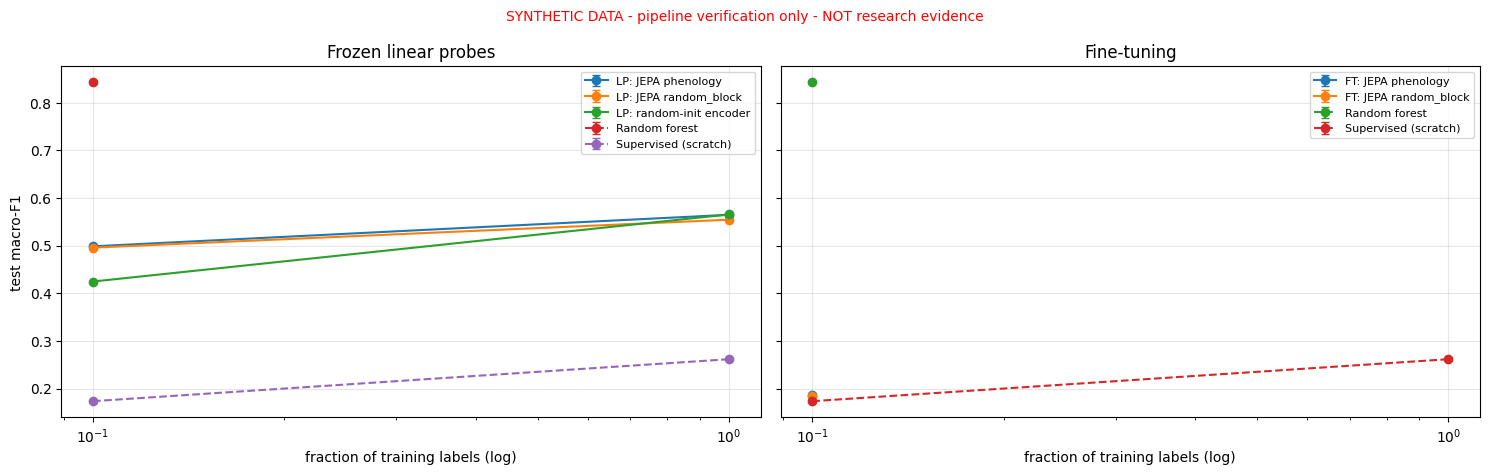

In [34]:
# 13.3 Label-efficiency curves
if not FULL.empty:
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
    groups = [("Frozen linear probes", lambda m: m.startswith("LP")), ("Fine-tuning", lambda m: m.startswith("FT"))]
    for ax, (title, sel) in zip(axes, groups):
        for m in sorted(MAIN.method.unique()):
            if not (sel(m) or m in ("Supervised (scratch)", "Random forest")):
                continue
            sub = MAIN[MAIN.method == m].sort_values("budget")
            ls = "--" if m in ("Supervised (scratch)", "Random forest") else "-"
            ax.errorbar(sub.budget, sub.macro_f1_mean, yerr=sub.macro_f1_std.fillna(0), marker="o", ls=ls, capsize=3, label=m)
        ax.set_xscale("log"); ax.set_xlabel("fraction of training labels (log)"); ax.set_title(title); ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
    axes[0].set_ylabel("test macro-F1")
    stamp(fig); plt.tight_layout(); fig.savefig(DIRS["figures"] / "13_label_efficiency.png", dpi=120); plt.show()
else:
    print("Label-efficiency curves: PENDING")

In [35]:
# 13.4 Paired comparisons against the unmodified JEPA baseline (same fold config, seed, label subset, test parcels)
def paired_table(prefix):
    base = f"{prefix}: JEPA random_block"
    rows = []
    if FULL.empty or base not in set(FULL.method):
        return pd.DataFrame()
    for m in sorted(x for x in FULL.method.unique() if x.startswith(f"{prefix}: JEPA") and x != base):
        for b in sorted(FULL.budget.unique()):
            A = FULL[(FULL.method == m) & (FULL.budget == b)]
            B = FULL[(FULL.method == base) & (FULL.budget == b)]
            for _, r in A.merge(B, on=["fc", "seed"], suffixes=("_a", "_b")).iterrows():
                za, zb = np.load(r.pred_file_a), np.load(r.pred_file_b)
                assert np.array_equal(za["rows"], zb["rows"]) and np.array_equal(za["y_true"], zb["y_true"]), "unpaired test sets"
                bs = paired_bootstrap(za["y_true"].astype(np.int64), za["y_pred"].astype(np.int64), zb["y_pred"].astype(np.int64),
                                      N_CLASSES, P["bootstrap_reps"], seed=int(r.seed))
                rows.append(dict(comparison=f"{m}  minus  {base}", budget=b, fc=r.fc, seed=r.seed, **bs,
                                 ci_excludes_zero_positive=bs["ci_low"] > 0, ci_excludes_zero_negative=bs["ci_high"] < 0))
    return pd.DataFrame(rows)

PAIRED = pd.concat([paired_table("LP"), paired_table("FT")], ignore_index=True)
if PAIRED.empty:
    print("Paired comparisons: PENDING (need completed runs for random_block and at least one other policy)")
    PAIRED_SUM = pd.DataFrame()
else:
    PAIRED_SUM = PAIRED.groupby(["comparison", "budget"]).agg(mean_diff=("diff", "mean"), sd_diff=("diff", "std"),
                                                             n_pairs=("diff", "size"), n_positive=("diff", lambda s: int((s > 0).sum())),
                                                             n_ci_positive=("ci_excludes_zero_positive", "sum"),
                                                             n_ci_negative=("ci_excludes_zero_negative", "sum")).reset_index()
    print(f"Paired macro-F1 differences with per-pair bootstrap 95% CIs ({P['bootstrap_reps']} resamples of test parcels)")
    print(PAIRED.round(4).to_string(index=False))
    print("\nSummary:")
    print(PAIRED_SUM.round(4).to_string(index=False))
    PAIRED.to_csv(DIRS["tables"] / "paired_differences.csv", index=False)
    PAIRED_SUM.to_csv(DIRS["tables"] / "paired_differences_summary.csv", index=False)

Paired macro-F1 differences with per-pair bootstrap 95% CIs (200 resamples of test parcels)
                                      comparison  budget  fc  seed   diff  ci_low  ci_high  ci_excludes_zero_positive  ci_excludes_zero_negative
LP: JEPA phenology  minus  LP: JEPA random_block     0.1   0     0 0.0027  0.0000   0.0087                      False                      False
LP: JEPA phenology  minus  LP: JEPA random_block     1.0   0     0 0.0103 -0.0062   0.0296                      False                      False
FT: JEPA phenology  minus  FT: JEPA random_block     0.1   0     0 0.0017  0.0000   0.0049                      False                      False

Summary:
                                      comparison  budget  mean_diff  sd_diff  n_pairs  n_positive  n_ci_positive  n_ci_negative
FT: JEPA phenology  minus  FT: JEPA random_block     0.1     0.0017      NaN        1           1              0              0
LP: JEPA phenology  minus  LP: JEPA random_block     0.1     0

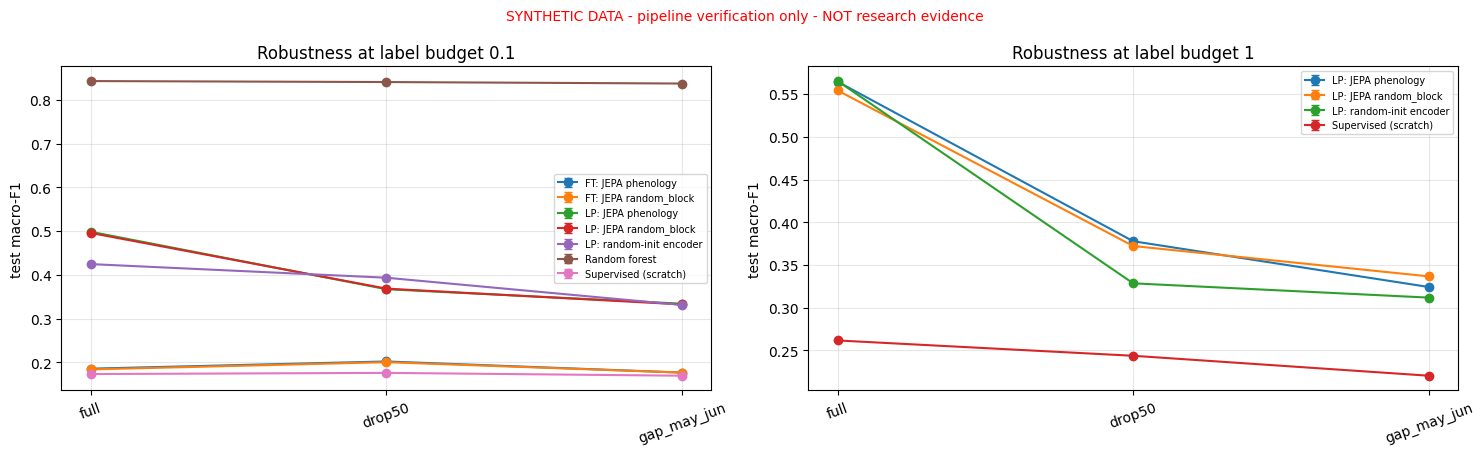

scenario                         full  drop50  gap_may_jun
method                  budget                            
FT: JEPA phenology      0.1     0.186   0.202        0.177
FT: JEPA random_block   0.1     0.184   0.201        0.177
LP: JEPA phenology      0.1     0.498   0.367        0.334
                        1.0     0.565   0.378        0.324
LP: JEPA random_block   0.1     0.496   0.369        0.333
                        1.0     0.554   0.372        0.337
LP: random-init encoder 0.1     0.425   0.394        0.331
                        1.0     0.565   0.329        0.312
Random forest           0.1     0.843   0.840        0.837
Supervised (scratch)    0.1     0.174   0.176        0.170
                        1.0     0.262   0.244        0.220


In [36]:
# 13.5 Missing-observation robustness (same masks for every model)
if not RES.empty:
    budgets_rob = [b for b in sorted({PRIMARY_B, 1.0}) if b in set(RES.budget)]
    fig, axes = plt.subplots(1, max(1, len(budgets_rob)), figsize=(7.5 * max(1, len(budgets_rob)), 4.6), squeeze=False)
    rob = RES.groupby(["method", "budget", "scenario"]).macro_f1.agg(["mean", "std", "size"]).reset_index()
    for ax, b in zip(axes[0], budgets_rob):
        for m in sorted(rob.method.unique()):
            sub = rob[(rob.method == m) & (rob.budget == b)].set_index("scenario").reindex(SCEN_ORDER).dropna(subset=["mean"])
            if len(sub):
                ax.errorbar([SCEN_ORDER.index(s) for s in sub.index], sub["mean"], yerr=sub["std"].fillna(0), marker="o", capsize=3, label=m)
        ax.set_xticks(range(len(SCEN_ORDER))); ax.set_xticklabels(SCEN_ORDER, rotation=20)
        ax.set_title(f"Robustness at label budget {b:g}"); ax.set_ylabel("test macro-F1"); ax.grid(alpha=0.3); ax.legend(fontsize=7)
    stamp(fig); plt.tight_layout(); fig.savefig(DIRS["figures"] / "13_missing_observations.png", dpi=120); plt.show()
    ROB = rob.pivot_table(index=["method", "budget"], columns="scenario", values="mean").reindex(columns=SCEN_ORDER)
    print(ROB.round(3).to_string()); ROB.to_csv(DIRS["tables"] / "missing_observation_robustness.csv")
else:
    print("Missing-observation robustness: PENDING")

Per-class test F1 at label budget 0.1 (mean over runs)
                     FT: JEPA phenology  FT: JEPA random_block  LP: JEPA phenology  LP: JEPA random_block  Random forest  Supervised (scratch)  test_support
syn_winter_cereal_A               0.141                  0.130               0.424                  0.424          0.917                 0.072           109
syn_winter_cereal_B               0.000                  0.000               0.314                  0.314          0.424                 0.000            22
syn_rapeseed_like                 0.000                  0.000               0.725                  0.725          1.000                 0.000            37
syn_summer_crop_A                 0.457                  0.454               0.538                  0.528          0.906                 0.434            74
syn_summer_crop_B                 0.000                  0.000               0.462                  0.450          0.923                 0.000            21
syn

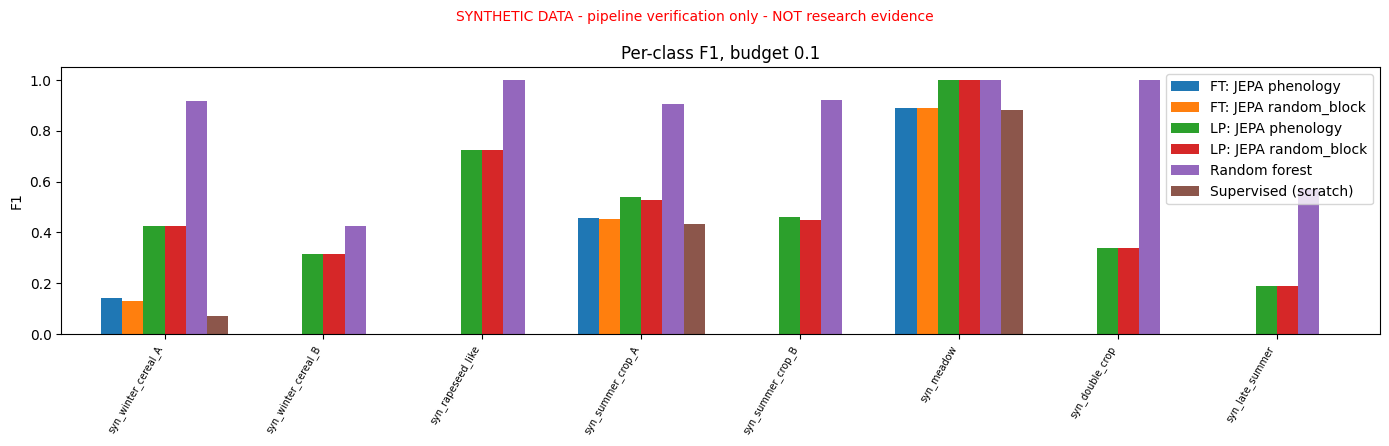

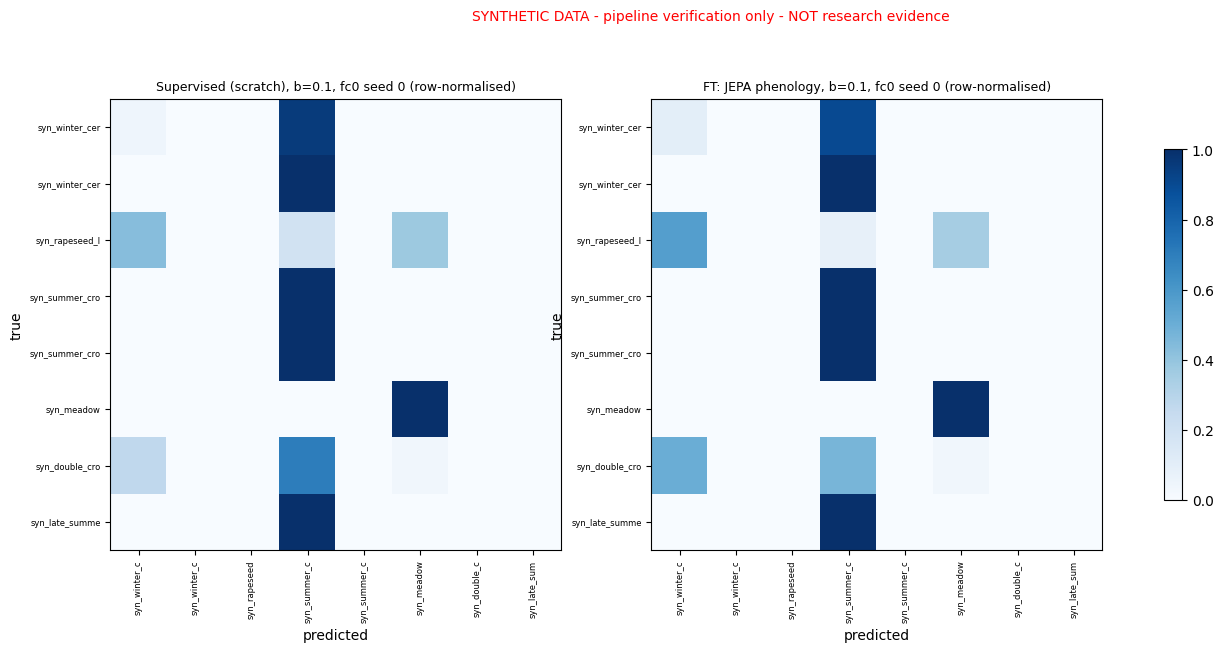

In [37]:
# 13.6 Per-class F1 and confusion matrices
def _full_metrics(row):
    m = read_json(Path(row.run_dir) / "metrics.json")
    if row.kind == "lp":
        return m["results"][btag(row.budget)]["test"]["full"]
    return m["test"]["full"]

if not FULL.empty:
    common = sorted(set(FULL[FULL.method == "Supervised (scratch)"].budget) & set(FULL[FULL.method.str.startswith("FT")].budget))
    b_pc = max(common) if common else max(FULL.budget)
    sel = FULL[(FULL.budget == b_pc) & FULL.method.isin(
        ["Supervised (scratch)", "Random forest", "LP: JEPA random_block", "LP: JEPA phenology", "FT: JEPA random_block", "FT: JEPA phenology"])]
    pcf = {m: np.mean([_full_metrics(r)["per_class_f1"] for r in g.itertuples()], axis=0) for m, g in sel.groupby("method")}
    support = _full_metrics(next(sel.itertuples()))["support"]
    PCF = pd.DataFrame(pcf, index=CLASS_NAMES); PCF["test_support"] = support
    print(f"Per-class test F1 at label budget {b_pc:g} (mean over runs)")
    print(PCF.round(3).to_string()); PCF.to_csv(DIRS["tables"] / f"per_class_f1_b{btag(b_pc)}.csv")
    fig, ax = plt.subplots(figsize=(14, 4.5))
    PCF.drop(columns="test_support").plot.bar(ax=ax, width=0.8); ax.set_ylabel("F1"); ax.set_title(f"Per-class F1, budget {b_pc:g}")
    plt.xticks(rotation=60, ha="right", fontsize=7); stamp(fig); plt.tight_layout()
    fig.savefig(DIRS["figures"] / "13_per_class_f1.png", dpi=120); plt.show()
    cms = [m for m in ["Supervised (scratch)", "FT: JEPA phenology", "LP: JEPA phenology"] if m in set(sel.method)][:2]
    if cms:
        fig, axes = plt.subplots(1, len(cms), figsize=(8 * len(cms), 6.5), squeeze=False)
        for ax, m in zip(axes[0], cms):
            r = sel[sel.method == m].sort_values(["fc", "seed"]).iloc[0]
            cm = np.array(_full_metrics(r)["confusion"], dtype=float)
            cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
            im = ax.imshow(cmn, vmin=0, vmax=1, cmap="Blues")
            ax.set_xticks(range(N_CLASSES)); ax.set_yticks(range(N_CLASSES))
            ax.set_xticklabels([c[:12] for c in CLASS_NAMES], rotation=90, fontsize=6); ax.set_yticklabels([c[:14] for c in CLASS_NAMES], fontsize=6)
            ax.set_title(f"{m}, b={b_pc:g}, fc{r.fc} seed {r.seed} (row-normalised)", fontsize=9); ax.set_xlabel("predicted"); ax.set_ylabel("true")
        fig.colorbar(im, ax=axes[0].tolist(), shrink=0.7); stamp(fig)
        fig.savefig(DIRS["figures"] / "13_confusion_matrices.png", dpi=120); plt.show()
else:
    print("Per-class metrics and confusion matrices: PENDING")

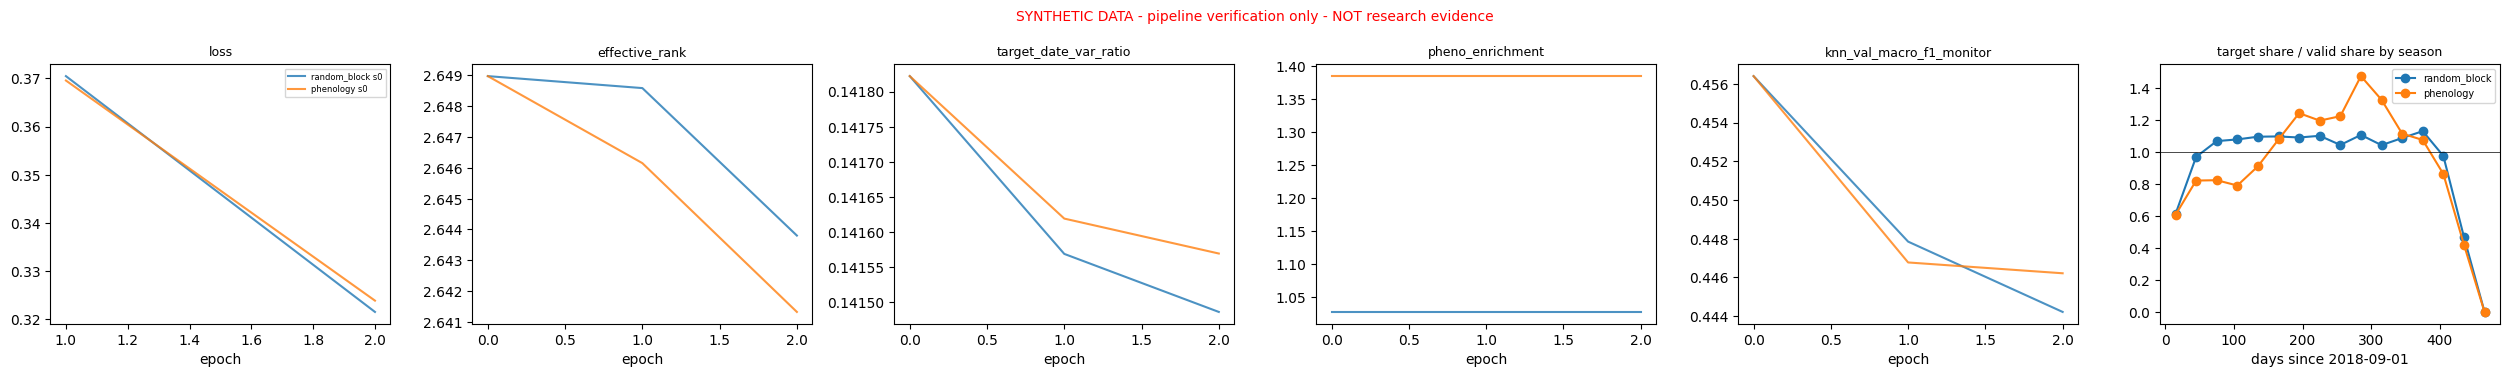

kNN values are a monitoring signal only; they were never used to select checkpoints.


In [38]:
# 13.7 SSL training curves, collapse diagnostics and target placement
ssl_specs = [s for s in PLAN if s["kind"] == "ssl" and spec_rundir(s).is_complete()]
if ssl_specs:
    cols = ["loss", "effective_rank", "target_date_var_ratio", "pheno_enrichment"] + (["knn_val_macro_f1_monitor"] if P["knn_monitor"] else [])
    fig, axes = plt.subplots(1, len(cols) + 1, figsize=(4.2 * (len(cols) + 1), 3.8))
    cmap = {p: c for p, c in zip(POLICIES, ["tab:blue", "tab:orange", "tab:green", "tab:red"])}
    hist_ratio = {}
    for s in ssl_specs:
        rd = spec_rundir(s); lg = pd.DataFrame(read_jsonl(rd.log))
        for ax, c in zip(axes, cols):
            if c in lg:
                ax.plot(lg.epoch, lg[c], color=cmap[s["policy"]], alpha=0.8, label=f"{s['policy']} s{s['seed']}")
                ax.set_title(c, fontsize=9); ax.set_xlabel("epoch")
        fd = rd.metrics()["final_diagnostics"]
        if "target_day_hist" in fd:
            r_ = np.array(fd["target_day_hist"], float) / np.maximum(np.array(fd["valid_day_hist"], float), 1)
            hist_ratio.setdefault(s["policy"], []).append(r_ / max(r_[np.array(fd["valid_day_hist"]) > 0].mean(), 1e-9))
    axes[0].legend(fontsize=6)
    for pol, hs in hist_ratio.items():
        axes[-1].plot(np.arange(15, 480, 30), np.mean(hs, 0), marker="o", color=cmap[pol], label=pol)
    axes[-1].axhline(1, color="k", lw=0.5); axes[-1].set_title("target share / valid share by season", fontsize=9)
    axes[-1].set_xlabel(f"days since {REF_DATE}"); axes[-1].legend(fontsize=7)
    stamp(fig); plt.tight_layout(); fig.savefig(DIRS["figures"] / "13_ssl_curves.png", dpi=120); plt.show()
    print("kNN values are a monitoring signal only; they were never used to select checkpoints.")
else:
    print("SSL curves: PENDING")

In [39]:
# 13.8 Runtime, memory and model-size table (measured)
rt = []
for s in PLAN:
    rd = spec_rundir(s)
    if not rd.is_complete():
        continue
    m = rd.metrics(); pk = m.get("peak", {})
    rt.append(dict(run=spec_name(s), kind=s["kind"], status=m.get("status"),
                   time_s=m.get("wall_time_s", m.get("train_time_s")), steps=m.get("steps", m.get("total_steps")),
                   steps_per_s=m.get("mean_steps_per_s"), peak_alloc_mb=pk.get("peak_alloc_mb"),
                   peak_reserved_mb=pk.get("peak_reserved_mb"), rss_mb=pk.get("rss_mb"),
                   params=m.get("params", (m.get("params_encoder") or 0) + (m.get("params_predictor") or 0) or None)))
RUNTIME = pd.DataFrame(rt)
if not RUNTIME.empty:
    print(RUNTIME.to_string(index=False))
    print("\nTotal measured run time by kind (s):", RUNTIME.groupby("kind").time_s.sum().round(1).to_dict())
    RUNTIME.to_csv(DIRS["tables"] / "runtime_memory.csv", index=False)
else:
    print("Runtime table: PENDING")
print("\nPending runs:", "none" if PENDING.empty else "")
if not PENDING.empty:
    print(PENDING.to_string(index=False))
if not FAILED.empty:
    print("\nFAILED runs:"); print(FAILED.to_string(index=False))

                                     run       kind   status  time_s  steps  steps_per_s peak_alloc_mb peak_reserved_mb  rss_mb   params
           supervised b=0.1 | fc0 seed 0 supervised complete     1.5   20.0          NaN          None             None  2180.1 105608.0
           supervised b=1.0 | fc0 seed 0 supervised complete     4.4   51.0          NaN          None             None  2180.1 105608.0
        random forest b=0.1 | fc0 seed 0         rf complete     0.2    NaN          NaN          None             None     NaN      NaN
           ssl random_block | fc0 seed 0        ssl complete    10.3   34.0        4.835          None             None  2180.1 135840.0
              ssl phenology | fc0 seed 0        ssl complete    10.2   34.0        4.850          None             None  2180.1 135840.0
   linear probe random_init | fc0 seed 0         lp complete     2.4    NaN          NaN          None             None  2180.1      NaN
  linear probe random_block | fc0 seed 0 

## 14. Automatically generated research summary

Generated from saved outputs and the pre-registered decision rules (Section 0.2). It distinguishes **measured** results from **interpretation**, and it refuses to declare support for the hypothesis from synthetic data, from the smoke-test profile, or with fewer than three paired runs.

In [40]:
# 14.1 Decision gates, hypothesis verdict and next step
from IPython.display import Markdown, display
L = []
def add(s=""):
    L.append(s)

sanity = read_json(DIRS["results"] / "sanity_tests.json")
gates = {}
gates["G1 sanity tests"] = ("PASS" if sanity["passed"] else "FAIL", f"{sanity['n_tests']-sanity['n_failed']}/{sanity['n_tests']} passed")

ctxS = get_context(P["fold_configs"][0])
ytr_idx = ctxS.store.y[torch.as_tensor(ctxS.split["train"], device=ctxS.store.y.device)].cpu().numpy()
maj_f1 = compute_metrics(ctxS.y_test, np.full_like(ctxS.y_test, np.bincount(ytr_idx).argmax()), with_cm=False)["macro_f1"]
chance_f1 = compute_metrics(ctxS.y_test, np.random.default_rng(0).integers(0, N_CLASSES, len(ctxS.y_test)), with_cm=False)["macro_f1"]
sup = FULL[FULL.method == "Supervised (scratch)"] if not FULL.empty else pd.DataFrame()
if len(sup):
    bmax = sup.budget.max(); f = sup[sup.budget == bmax].macro_f1.mean()
    gates["G2 supervised baseline plausible"] = ("PASS" if f > max(maj_f1, chance_f1) + 0.05 else "FAIL",
                                                 f"macro-F1 {f:.3f} at budget {bmax:g} vs majority {maj_f1:.3f} / uniform-random {chance_f1:.3f}")
else:
    gates["G2 supervised baseline plausible"] = ("PENDING", "")

ssl_m = [spec_rundir(s).metrics() for s in PLAN if s["kind"] == "ssl" and spec_rundir(s).is_complete()]
if ssl_m:
    bad = [m["run_id"] for m in ssl_m if m["status"] == "collapsed" or m["final_diagnostics"]["effective_rank"] < m["collapse_rank_limit"]]
    def _loss_ratio(m):
        lg = [r for r in read_jsonl(Path(m["run_dir"]) / "log.jsonl") if "loss" in r]
        return lg[-1]["loss"] / lg[0]["loss"] if len(lg) >= 2 and lg[0]["loss"] > 0 else float("nan")
    lratio = {m["run_id"]: _loss_ratio(m) for m in ssl_m}
    shortcut = [m["run_id"] for m in ssl_m if m["final_diagnostics"].get("target_date_var_ratio", 0) > HP["date_var_ratio_max"]
                or lratio[m["run_id"]] < HP["shortcut_loss_ratio_min"]]
    dvr = [m["final_diagnostics"].get("target_date_var_ratio", float("nan")) for m in ssl_m]
    gates["G3 no representation collapse / positional shortcut"] = ("PASS" if not (bad or shortcut) else "FAIL",
        f"effective rank initial {min(m['initial_diagnostics']['effective_rank'] for m in ssl_m):.2f}-{max(m['initial_diagnostics']['effective_rank'] for m in ssl_m):.2f} "
        f"-> final {min(m['final_diagnostics']['effective_rank'] for m in ssl_m):.2f}-{max(m['final_diagnostics']['effective_rank'] for m in ssl_m):.2f} "
        f"(collapse if < {HP['collapse_rank_rel']:.0%} of initial); "
        f"target variance explained by date {np.nanmin(dvr):.2f}-{np.nanmax(dvr):.2f} (max {HP['date_var_ratio_max']}); "
        f"final/first-epoch SSL loss {np.nanmin(list(lratio.values())):.3f}-{np.nanmax(list(lratio.values())):.3f} (min {HP['shortcut_loss_ratio_min']})"
        + (f"; collapsed: {bad}" if bad else "") + (f"; shortcut: {shortcut}" if shortcut else ""))
else:
    gates["G3 no representation collapse / positional shortcut"] = ("PENDING", "")

def pair_diffs(ma, mb, b):
    if FULL.empty:
        return pd.Series(dtype=float)
    A = FULL[(FULL.method == ma) & (FULL.budget == b)]; B = FULL[(FULL.method == mb) & (FULL.budget == b)]
    j = A.merge(B, on=["fc", "seed"], suffixes=("_a", "_b"))
    return j.macro_f1_a - j.macro_f1_b

dj = pair_diffs("LP: JEPA random_block", "LP: random-init encoder", PRIMARY_B)
gates["G4 JEPA beats random-init features (LP, primary budget)"] = (
    "PENDING" if dj.empty else (("PASS" if (dj > 0).all() else "FAIL") + (" (weak: < 3 pairs)" if len(dj) < 3 else "")),
    "" if dj.empty else f"mean diff {dj.mean():+.3f} over {len(dj)} pair(s)")

prim = PAIRED[(PAIRED.comparison.str.startswith("LP: JEPA phenology")) & (PAIRED.budget == PRIMARY_B)] if not PAIRED.empty else pd.DataFrame()
if prim.empty:
    verdict, vdetail = "PENDING", "primary-endpoint runs not complete"
else:
    n = len(prim); mdiff = prim["diff"].mean()
    vdetail = (f"mean paired diff {mdiff:+.4f} macro-F1 over {n} pair(s); {int((prim['diff'] > 0).sum())} positive; "
               f"{int((prim.ci_low > 0).sum())} with bootstrap CI > 0, {int((prim.ci_high < 0).sum())} with CI < 0")
    if DATA_SOURCE == "synthetic" or PROFILE == "SMOKE_TEST":
        verdict = "NOT EVALUATED (synthetic data or SMOKE_TEST profile)"
    elif n < 3:
        verdict = "INSUFFICIENT EVIDENCE (< 3 paired runs)"
    elif mdiff > 0 and (prim["diff"] > 0).all() and (prim.ci_low > 0).sum() > n / 2:
        verdict = "SUPPORTED at pilot level (requires controls + more folds before any claim)"
    elif mdiff < 0 and (prim["diff"] < 0).all():
        verdict = "CONTRADICTED"
    else:
        verdict = "INCONCLUSIVE"
gates["G5 hypothesis (primary endpoint)"] = (verdict, vdetail)

# ---- next step (rule-based) ----
def next_step():
    g = {k: v[0] for k, v in gates.items()}
    if g["G1 sanity tests"] != "PASS":
        return "Fix the failing sanity tests before any experiment."
    if g["G3 no representation collapse / positional shortcut"] == "FAIL":     # precedes data-source advice
        return ("JEPA collapsed or learned a positional shortcut: lower ssl_lr, raise ema_start (e.g. 0.998), check that token_embed is "
                "'ln_content_learned_date', and inspect target_date_var_ratio before testing the modification.")
    if DATA_SOURCE == "synthetic":
        return ("The pipeline runs end to end on synthetic data. Next: obtain PASTIS (Section 3), set DATA_SOURCE='pastis' and run "
                "SMOKE_TEST once on the 60-patch subset, then QUICK_PILOT.")
    if PROFILE == "SMOKE_TEST":
        return "The pipeline runs on real PASTIS data. Next: switch to PROFILE='QUICK_PILOT' (check the runtime projection in 11.3 first)."
    if g["G2 supervised baseline plausible"] == "FAIL":
        return "The supervised baseline is implausibly weak: audit labels, band order, normalisation and the metric before anything else."
    if g["G3 no representation collapse / positional shortcut"] == "FAIL":
        return ("JEPA collapsed or learned a positional shortcut: lower ssl_lr, raise ema_start (e.g. 0.998), check that token_embed is "
                "'ln_content_learned_date', and inspect target_date_var_ratio before testing the modification.")
    if g["G4 JEPA beats random-init features (LP, primary budget)"].startswith("FAIL"):
        return ("JEPA features are not better than random features: the baseline JEPA is not learning useful structure. Diagnose it "
                "(longer pretraining, block scale, predictor depth) before interpreting any target-policy difference.")
    if verdict.startswith("SUPPORTED"):
        return ("Run RESEARCH_RUN (all folds, 5 seeds, spectral_change + inverse_phenology controls) to test whether the gain is "
                "phenology-specific rather than a generic informed-masking effect, then complete the literature matrix.")
    if verdict == "CONTRADICTED":
        return ("Phenology-aware placement hurt. Examine per-class effects and the season-wise placement plot; consider whether "
                "prediction targets at transitions are too hard; revise the hypothesis rather than tuning toward a positive result.")
    if verdict.startswith("PENDING"):
        return "Complete the pending runs listed above."
    return ("Inconclusive: add seeds (>=5) and fold configurations before any claim; inspect per-class and missing-observation "
            "effects; if tuning policy_alpha/epsilon, use the validation fold only and disclose the extra tuning budget.")

# ---- best validated downstream checkpoint ----
best_ck = None
for s in PLAN:
    if s["kind"] in ("supervised", "finetune") and spec_rundir(s).is_complete():
        m = spec_rundir(s).metrics()
        if best_ck is None or m["best"]["val_macro_f1"] > best_ck[0]:
            best_ck = (m["best"]["val_macro_f1"], spec_name(s), str(spec_rundir(s).ckpt_best), m["test"]["full"]["macro_f1"])

# ---- assemble report ----
add(f"# Research summary - {NS}")
add(f"Generated {dt.datetime.now().isoformat(timespec='seconds')} | notebook {NOTEBOOK_VERSION} | device {BENCH['gpu']} | precision {BENCH['precision']}")
if RESULT_BANNER:
    add(f"\n**{RESULT_BANNER}.** Nothing below is evidence about real crops.")
add("\n## Data and protocol")
add(f"- Data source: `{DATA_SOURCE}`; {len(META)} patches; {N_PARCELS} parcels; {N_CLASSES} classes; T_MAX={T_MAX}.")
add(f"- Fold configs: {P['fold_configs']} ({SPLIT_MODE}); strict inductive SSL (training folds only); seeds {P['seeds']}.")
add(f"- Primary endpoint: linear-probe test macro-F1 at budget {PRIMARY_B:g}.")
done = len(PLAN) - len(PENDING) - len(FAILED)
add("\n## Experiments")
add(f"- Planned {len(PLAN)} | completed {done} | pending {len(PENDING)} | failed {len(FAILED)}.")
if len(FAILED):
    add("- Failed: " + "; ".join(FAILED.run.tolist()))
add("\n## Decision gates (measured)")
add("| Gate | Result | Detail |\n|---|---|---|")
for k, (r, dtl) in gates.items():
    add(f"| {k} | **{r}** | {dtl} |")
add("\n## Measured results (test macro-F1, full observations)")
if MAIN.empty:
    add("PENDING - no completed downstream runs.")
else:
    t = MAIN[["method", "budget", "n_labelled", "macro_f1_mean", "macro_f1_std", "n_runs"]].copy()
    add("| Method | Budget | Labelled parcels | Macro-F1 mean | SD | Runs |\n|---|---|---|---|---|---|")
    for r in t.itertuples():
        add(f"| {r.method} | {r.budget:g} | {r.n_labelled:.0f} | {r.macro_f1_mean:.4f} | "
            f"{'n/a' if pd.isna(r.macro_f1_std) else f'{r.macro_f1_std:.4f}'} | {r.n_runs} |")
if not PAIRED_SUM.empty:
    add("\n## Paired differences vs the unmodified JEPA (random_block)")
    add("| Comparison | Budget | Mean diff | Pairs | Positive | CI>0 | CI<0 |\n|---|---|---|---|---|---|---|")
    for r in PAIRED_SUM.itertuples():
        add(f"| {r.comparison} | {r.budget:g} | {r.mean_diff:+.4f} | {r.n_pairs} | {r.n_positive} | {int(r.n_ci_positive)} | {int(r.n_ci_negative)} |")
add("\n## Best validated downstream checkpoint")
add("PENDING" if best_ck is None else f"- {best_ck[1]}: val macro-F1 {best_ck[0]:.4f}, test macro-F1 {best_ck[3]:.4f}; `{best_ck[2]}`")
add("\n## Runtime and memory (measured)")
if not RUNTIME.empty:
    add(f"- Total measured run time: {RUNTIME.time_s.sum()/60:.1f} min; by kind (s): {RUNTIME.groupby('kind').time_s.sum().round(0).to_dict()}")
    if RUNTIME.peak_alloc_mb.notna().any():
        add(f"- Peak GPU memory allocated / reserved: {RUNTIME.peak_alloc_mb.max():.0f} / {RUNTIME.peak_reserved_mb.max():.0f} MB")
add(f"- Other timings (s): {json.dumps(TIMINGS)}")
add("\n## Interpretation (not a measurement)")
add(f"- Hypothesis verdict under the pre-registered rule: **{verdict}**.")
add("- A positive pilot result would show only that phenology-aware placement beats uniform placement in this compact setting; "
    "phenology-specificity requires the spectral_change and inverse_phenology controls, and generality requires all folds.")
add("\n## Limitations")
add("- Parcel-level task with per-parcel median series: not the official PASTIS segmentation benchmark; spatial context and mixed pixels are not modelled.")
add("- Compact temporal adaptation of I-JEPA (non-overlapping 1-D blocks, fixed weight decay); see Section 0.4.")
add("- Validation uses the fully labelled validation fold even at low label budgets (identical for all methods, but optimistic in absolute terms).")
add("- Cloud handling relies on a simple blue-band heuristic inside the phenology scorer only.")
add("- Bit-exact GPU reproducibility is not guaranteed; seeds, configs and splits are recorded.")
add("\n## Recommended next experiment")
add(next_step())
REPORT = "\n".join(L)
(DIRS["results"] / "RESEARCH_SUMMARY.md").write_text(REPORT, encoding="utf-8")
display(Markdown(REPORT))
print(f"\nSaved to {DIRS['results'] / 'RESEARCH_SUMMARY.md'}")

# Research summary - synthetic__SMOKE_TEST
Generated 2026-10-09T08:12:00 | notebook 1.0.0 | device cpu | precision fp32

**SYNTHETIC DATA - pipeline verification only - NOT research evidence.** Nothing below is evidence about real crops.

## Data and protocol
- Data source: `synthetic`; 150 patches; 1895 parcels; 8 classes; T_MAX=60.
- Fold configs: [0] (official_folds); strict inductive SSL (training folds only); seeds [0].
- Primary endpoint: linear-probe test macro-F1 at budget 0.1.

## Experiments
- Planned 10 | completed 10 | pending 0 | failed 0.

## Decision gates (measured)
| Gate | Result | Detail |
|---|---|---|
| G1 sanity tests | **PASS** | 57/57 passed |
| G2 supervised baseline plausible | **PASS** | macro-F1 0.262 at budget 1 vs majority 0.057 / uniform-random 0.127 |
| G3 no representation collapse / positional shortcut | **PASS** | effective rank initial 2.65-2.65 -> final 2.64-2.64 (collapse if < 50% of initial); target variance explained by date 0.14-0.14 (max 0.5); final/first-epoch SSL loss 0.868-0.876 (min 0.05) |
| G4 JEPA beats random-init features (LP, primary budget) | **PASS (weak: < 3 pairs)** | mean diff +0.071 over 1 pair(s) |
| G5 hypothesis (primary endpoint) | **NOT EVALUATED (synthetic data or SMOKE_TEST profile)** | mean paired diff +0.0027 macro-F1 over 1 pair(s); 1 positive; 0 with bootstrap CI > 0, 0 with CI < 0 |

## Measured results (test macro-F1, full observations)
| Method | Budget | Labelled parcels | Macro-F1 mean | SD | Runs |
|---|---|---|---|---|---|
| FT: JEPA phenology | 0.1 | 110 | 0.1858 | n/a | 1 |
| FT: JEPA random_block | 0.1 | 110 | 0.1841 | n/a | 1 |
| LP: JEPA phenology | 0.1 | 110 | 0.4984 | n/a | 1 |
| LP: JEPA phenology | 1 | 1057 | 0.5646 | n/a | 1 |
| LP: JEPA random_block | 0.1 | 110 | 0.4957 | n/a | 1 |
| LP: JEPA random_block | 1 | 1057 | 0.5544 | n/a | 1 |
| LP: random-init encoder | 0.1 | 110 | 0.4246 | n/a | 1 |
| LP: random-init encoder | 1 | 1057 | 0.5653 | n/a | 1 |
| Random forest | 0.1 | 110 | 0.8427 | n/a | 1 |
| Supervised (scratch) | 0.1 | 110 | 0.1735 | n/a | 1 |
| Supervised (scratch) | 1 | 1057 | 0.2616 | n/a | 1 |

## Paired differences vs the unmodified JEPA (random_block)
| Comparison | Budget | Mean diff | Pairs | Positive | CI>0 | CI<0 |
|---|---|---|---|---|---|---|
| FT: JEPA phenology  minus  FT: JEPA random_block | 0.1 | +0.0017 | 1 | 1 | 0 | 0 |
| LP: JEPA phenology  minus  LP: JEPA random_block | 0.1 | +0.0027 | 1 | 1 | 0 | 0 |
| LP: JEPA phenology  minus  LP: JEPA random_block | 1 | +0.0103 | 1 | 1 | 0 | 0 |

## Best validated downstream checkpoint
- supervised b=1.0 | fc0 seed 0: val macro-F1 0.2843, test macro-F1 0.2616; `/home/claude/valH/jepa_work/runs/synthetic__SMOKE_TEST/sup_fc0_s0_b1__d4d04ecf/ckpt_best.pt`

## Runtime and memory (measured)
- Total measured run time: 0.6 min; by kind (s): {'finetune': 3.0, 'lp': 7.0, 'rf': 0.0, 'ssl': 20.0, 'supervised': 6.0}
- Other timings (s): {"dataset_preparation_s": 1.4, "sanity_tests_s": 21.6, "benchmark_s": 66.5, "supervised": 6.7, "random_forest": 0.2, "ssl_random_block": 11.9, "ssl_modification_and_controls": 11.9, "linear_probes": 6.8, "fine_tuning": 3.8}

## Interpretation (not a measurement)
- Hypothesis verdict under the pre-registered rule: **NOT EVALUATED (synthetic data or SMOKE_TEST profile)**.
- A positive pilot result would show only that phenology-aware placement beats uniform placement in this compact setting; phenology-specificity requires the spectral_change and inverse_phenology controls, and generality requires all folds.

## Limitations
- Parcel-level task with per-parcel median series: not the official PASTIS segmentation benchmark; spatial context and mixed pixels are not modelled.
- Compact temporal adaptation of I-JEPA (non-overlapping 1-D blocks, fixed weight decay); see Section 0.4.
- Validation uses the fully labelled validation fold even at low label budgets (identical for all methods, but optimistic in absolute terms).
- Cloud handling relies on a simple blue-band heuristic inside the phenology scorer only.
- Bit-exact GPU reproducibility is not guaranteed; seeds, configs and splits are recorded.

## Recommended next experiment
The pipeline runs end to end on synthetic data. Next: obtain PASTIS (Section 3), set DATA_SOURCE='pastis' and run SMOKE_TEST once on the 60-patch subset, then QUICK_PILOT.


Saved to /home/claude/valH/jepa_work/results/synthetic__SMOKE_TEST/RESEARCH_SUMMARY.md
